# Loan Approval Risk Model for FinTech Innovations
### A CRISP-DM analysis: from the \$8,000 / \$50,000 cost trade-off to a deployable, explainable scoring pipeline

## Overview (Bottom Line Up Front)
**The result:** a regularised **Logistic Regression pipeline** ranks applicants almost perfectly (test **ROC-AUC 0.996**, **PR-AUC 0.989**). Used with a **cost-optimised approval threshold (~0.81 instead of the default 0.50)**, it cuts the dollar cost of wrong decisions from **\$1,912 per applicant** (the "deny everyone" baseline) to about **\$464 per applicant (-76%)**. On a 20,000-application portfolio that is roughly **\$29M of avoided error cost / profit** versus lending nothing, and it captures about **76% of the profit a perfect-foresight model could achieve**. (The "approve everyone" strategy would lose about \$723M.)

**The story in four beats**
1. *Accuracy lies.* With 76% of applicants denied, "deny everyone" is 76% accurate, so we judge models by **dollars**, not accuracy.
2. *The data fights back.* The file hides a **target-leaking column** (`RiskScore`), a **text-formatted income field**, an **artificial income floor**, **corrupted income rows**, and a **missing-education flag that perfectly predicts denial**. Finding and handling these mattered more than any algorithm.
3. *Simple beat complex.* After a fair multi-stage tuning contest, regularised Logistic Regression (CV AUC 0.9961) beat gradient boosting (0.9922), random forest and a voting ensemble, and it is the model a regulator can read.
4. *Threshold is a business decision.* Moving from 0.50 to the cost-optimal threshold nearly halves the cost per applicant (\$832 to \$464 on the test set).



## Setup: Libraries and Data Loading
> The lab template places the imports cell after the *Data Understanding* header. I load the libraries and the raw data **first**, because the business-cost analysis in Step 1.3 needs the class prevalence (how many applicants are creditworthy). Every heading below this point follows the numbered instructions of the lab (Steps 1 to 10).

In [4]:
# ---- Core libraries ---------------------------------------------------------
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import loguniform, randint, uniform

# ---- scikit-learn: preprocessing, pipelines, models, validation, metrics -----
from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer, KNNImputer, MissingIndicator
from sklearn.experimental import enable_iterative_imputer   # required to unlock IterativeImputer
from sklearn.impute import IterativeImputer
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, RandomizedSearchCV, GridSearchCV)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              VotingClassifier)
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, accuracy_score, confusion_matrix, make_scorer,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay,
                             r2_score, mean_absolute_error)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

# ---- Global settings --------------------------------------------------------
warnings.filterwarnings("ignore")
RANDOM_STATE = 42                      # reproducibility: every random step uses this seed
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
set_config(display="diagram")          # pipelines render as interactive diagrams

# ---- Load the raw data (change the path if you run this in Colab, e.g. /content/...)
DATA_PATH = "financial_loan_data.csv"
raw = pd.read_csv(DATA_PATH)
print("Raw data loaded:", raw.shape[0], "rows x", raw.shape[1], "columns")

Raw data loaded: 20000 rows x 35 columns


## What this code does: Imports the libraries, sets the random seed and plot style, and loads the loan data.

**What the code does.** Imports every library used later, fixes a random seed (`RANDOM_STATE = 42`), sets plotting style and loads the CSV into `raw` (20,000 rows x 35 columns).

**Why.** Putting all imports first makes the notebook reproducible and easy to audit. The seed guarantees that every split, search and bootstrap gives the same numbers on every run. `IterativeImputer` needs the explicit `enable_iterative_imputer` import because scikit-learn still flags it as experimental.

**Interpretation.** 20,000 applications, 35 columns, as promised in the brief.

**Decision.** Keep `raw` untouched as the original; all cleaning happens on a copy (`df`) so we can always trace back to the source.

### Feature groups (defined early, justified in Step 4.1)
Several EDA cells need to know which columns are money variables, categoricals, and so on, so the groups are declared once here.

In [8]:
# ------------------------------------------------------------------------------
# Feature groups (the reasoning behind each group is documented in Step 4.1).
# They are defined here, early, because several EDA cells below need them.
# ------------------------------------------------------------------------------
NUMERIC_SKEWED = ["AnnualIncome", "MonthlyIncome", "LoanAmount", "MonthlyDebtPayments", "SavingsAccountBalance",
                  "CheckingAccountBalance", "TotalAssets", "TotalLiabilities", "NetWorth",
                  "MonthlyLoanPayment", "TotalDebtToIncomeRatio"]
NUMERIC_OTHER  = ["Age", "CreditScore", "Experience", "LoanDuration", "NumberOfDependents",
                  "CreditCardUtilizationRate", "NumberOfOpenCreditLines", "NumberOfCreditInquiries",
                  "DebtToIncomeRatio", "PaymentHistory", "LengthOfCreditHistory",
                  "UtilityBillsPaymentHistory", "JobTenure", "BaseInterestRate", "InterestRate"]
BINARY_NUMERIC = ["PreviousLoanDefaults"]
NOMINAL        = ["MaritalStatus", "HomeOwnershipStatus", "EmploymentStatus", "LoanPurpose"]
BINARY_CAT     = ["BankruptcyHistory"]
ORDINAL        = ["EducationLevel"]
EDU_ORDER      = ["High School", "Associate", "Bachelor", "Master", "Doctorate"]

## What this code does: Declares which columns are skewed money, other numeric, binary, categorical, ordinal, target or leaky.

**What the code does.** Declares the role of every column once: skewed money/ratio variables, other numerics, a binary numeric, nominal and binary categoricals, the ordinal education column and its order.

**Why.** EDA cells, statistical tests and the pipeline all need the same lists. Defining them once avoids copy-paste inconsistencies. The reasoning behind each group is explained in Step 4.1 and the checks that prove no column was forgotten are run there.

**Decision.** These lists are the single source of truth for the rest of the notebook.

## Part 1: Business Understanding and Planning Phase

### 1. Begin by thoroughly analyzing the business context of FinTech Innovations' loan approval process. Write a short summary that:

#### 1.1 Describes the current manual process and its limitations
Loan officers review each application by hand. That produces:
* **Inconsistent decisions**: two officers can treat the same file differently.
* **Slow turnaround**: every file waits for a person.
* **No audit trail**: the reasons behind an approval or denial are rarely recorded in a comparable way.
* **Exposure to unconscious bias**, and a tendency to overlook creditworthy applicants who look unconventional on paper.

A data-driven model standardises the decision, speeds it up, and leaves a record of exactly which inputs drove each score.

#### 1.2 Identifies key stakeholders and their needs
| Stakeholder | Needs | How this project addresses it |
|---|---|---|
| **Loan officers** | Fast, consistent decision support they can trust and explain | Probability score plus top drivers; officers keep authority over borderline files |
| **Risk / finance management** | Control of default losses and profit | Dollar-cost metric tuned to the \$8k / \$50k economics |
| **Customers (applicants)** | Fair, fast, explainable decisions | Same rules for everyone; segment and fairness audit; interpretable coefficients |
| **Compliance / regulators** | Interpretability, no prohibited attributes, auditability | Linear, inspectable model; ablation of age and marital status; documented pipeline |
| **Partner banks** | Predictable portfolio performance | Confidence intervals and sensitivity analysis on the cost assumptions |

#### 1.3 Explains the implications of different types of model errors
Positive class = *approve*. The historical label is treated as the "right" decision (an assumption discussed in Step 10.4).

| | Model says **approve** | Model says **deny** |
|---|---|---|
| **Truly creditworthy** | Correct: earns about \$8,000 profit | **False Negative**: lost profit of **\$8,000** |
| **Should be denied** | **False Positive**: loss of **\$50,000** on a defaulted loan | Correct: loss avoided |

A false approval costs **6.25 times** a false denial. This asymmetry means that (i) accuracy and F1 at 0.5 are the wrong yardsticks, and (ii) the model should approve only when it is quite sure: the **break-even probability is 50,000 / (50,000 + 8,000) = 0.862**. The code below puts numbers on this.

,Strategy,FP share,FN share,Accuracy,Cost / applicant ($),"Total cost on 20,000 applicants ($M)"
0,Perfect model,0.0000,0.0000,1.0000,0.0000,0.0000
1,Deny everyone,0.0000,0.2390,0.7610,"1,912.0000",38.2400
2,Approve everyone,0.7610,0.0000,0.2390,"38,050.0000",761.0000
3,Coin flip (50/50),0.3805,0.1195,0.5000,"19,981.0000",399.6200


Share of creditworthy applicants (class 1): 23.9%  | Share to deny (class 0): 76.1%
Break-even probability threshold = 50,000 / (50,000 + 8,000) = 0.862


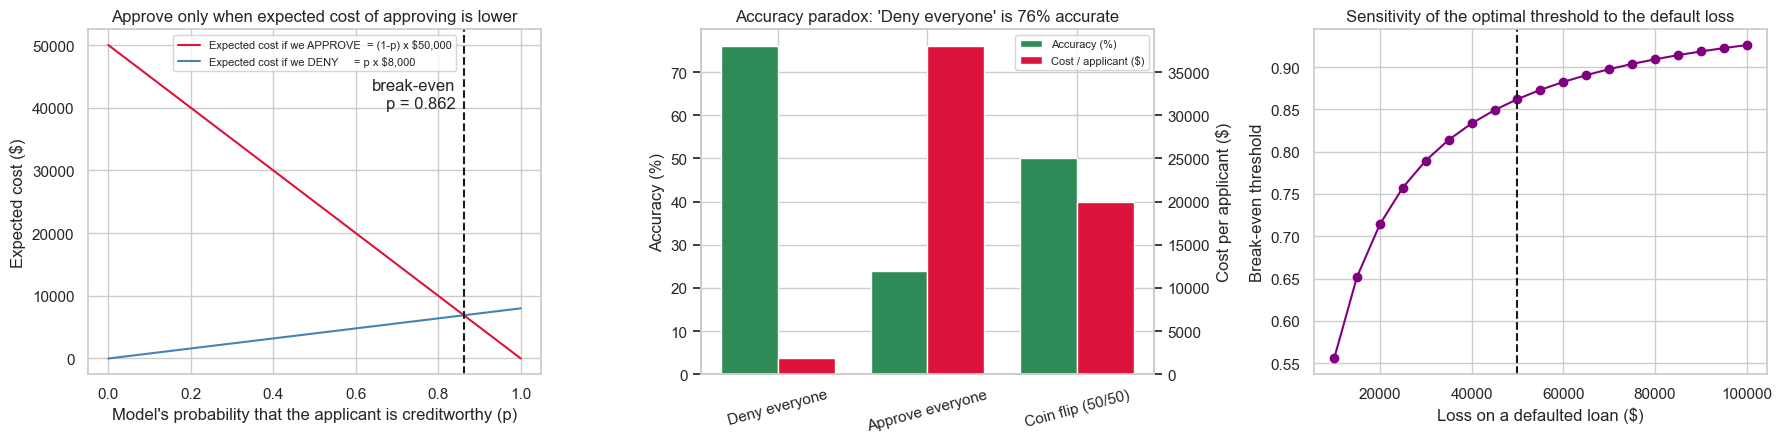

In [16]:
# ------------------------------------------------------------------------------
# Business cost model.  Positive class (1) = "approve / creditworthy".
#   False Positive (FP): we APPROVE an applicant who should have been denied -> loan defaults
#   False Negative (FN): we DENY a creditworthy applicant                    -> lost profit
# ------------------------------------------------------------------------------
FP_COST = 50_000      # average loss on a defaulted loan (principal + collection costs)
FN_COST = 8_000       # average profit lost per missed good loan

BREAK_EVEN = FP_COST / (FP_COST + FN_COST)      # optimal probability threshold (derived below)
prev = raw["LoanApproved"].mean()               # share of creditworthy applicants
n_total = len(raw)

# ---- Baseline "strategies" that need no machine learning ---------------------
def cost_per_applicant(fp_rate, fn_rate):
    """Expected business cost per applicant given the share of FPs and FNs in the portfolio."""
    return FP_COST * fp_rate + FN_COST * fn_rate

baselines = pd.DataFrame({
    "Strategy":            ["Perfect model", "Deny everyone", "Approve everyone", "Coin flip (50/50)"],
    "FP share":            [0.0, 0.0, 1 - prev, 0.5 * (1 - prev)],
    "FN share":            [0.0, prev, 0.0, 0.5 * prev],
    "Accuracy":            [1.0, 1 - prev, prev, 0.5],
})
baselines["Cost / applicant ($)"] = [cost_per_applicant(f, n) for f, n in zip(baselines["FP share"], baselines["FN share"])]
baselines[f"Total cost on {n_total:,} applicants ($M)"] = baselines["Cost / applicant ($)"] * n_total / 1e6
display(baselines)

print(f"Share of creditworthy applicants (class 1): {prev:.1%}  | Share to deny (class 0): {1-prev:.1%}")
print(f"Break-even probability threshold = {FP_COST:,} / ({FP_COST:,} + {FN_COST:,}) = {BREAK_EVEN:.3f}")

# ---- Visual 1: expected cost of each decision vs probability of being creditworthy
p = np.linspace(0, 1, 201)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ax[0].plot(p, (1 - p) * FP_COST, label="Expected cost if we APPROVE  = (1-p) x $50,000", color="crimson")
ax[0].plot(p, p * FN_COST,      label="Expected cost if we DENY     = p x $8,000",       color="steelblue")
ax[0].axvline(BREAK_EVEN, color="k", ls="--"); ax[0].text(BREAK_EVEN - 0.02, 40_000, f"break-even\np = {BREAK_EVEN:.3f}", ha="right")
ax[0].set_xlabel("Model's probability that the applicant is creditworthy (p)"); ax[0].set_ylabel("Expected cost ($)")
ax[0].set_title("Approve only when expected cost of approving is lower"); ax[0].legend(fontsize=8, loc="upper center")

# ---- Visual 2: the accuracy paradox - 'accuracy' vs 'business cost' for naive strategies
b = baselines.iloc[1:]
x = np.arange(len(b)); w = 0.38
ax[1].bar(x - w/2, b["Accuracy"] * 100, w, color="seagreen", label="Accuracy (%)")
ax[1].set_ylabel("Accuracy (%)"); ax[1].set_xticks(x); ax[1].set_xticklabels(b["Strategy"], rotation=15)
ax1b = ax[1].twinx(); ax1b.bar(x + w/2, b["Cost / applicant ($)"], w, color="crimson", label="Cost / applicant ($)"); ax1b.set_ylabel("Cost per applicant ($)"); ax1b.grid(False)
ax[1].set_title("Accuracy paradox: 'Deny everyone' is 76% accurate")
h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = ax1b.get_legend_handles_labels(); ax[1].legend(h1 + h2, l1 + l2, loc="upper right", fontsize=8)

# ---- Visual 3: how the break-even threshold moves if the loss on a default changes
fp_grid = np.arange(10_000, 100_001, 5_000)
ax[2].plot(fp_grid, fp_grid / (fp_grid + FN_COST), marker="o", color="purple")
ax[2].axvline(FP_COST, color="k", ls="--"); ax[2].set_xlabel("Loss on a defaulted loan ($)"); ax[2].set_ylabel("Break-even threshold")
ax[2].set_title("Sensitivity of the optimal threshold to the default loss")
plt.tight_layout(); plt.show()

## What this code does: Sets the \$50,000 / \$8,000 error costs, derives the 0.862 break-even threshold, and prices the no-model baselines.

**What the code does.** (1) Stores the two business costs. (2) Derives the **break-even probability** analytically. (3) Computes the cost of four no-model strategies. (4) Draws three charts: expected cost of approving vs denying as a function of the model's probability; accuracy vs dollar cost for naive strategies; and how the break-even threshold moves if the default loss changes.

**Why.** Before modelling we must know what "good" means in dollars. If approving costs `(1-p) x 50,000` and denying costs `p x 8,000`, we should approve only when the first is smaller, which happens when `p > 50,000/58,000 = 0.862`. The baselines give a yardstick every model must beat.

**Interpretation of the output.**
* 23.9% of applicants are creditworthy, 76.1% are not (imbalance about 3.2 : 1).
* **Deny everyone** costs \$1,912 per applicant (\$38.2M per 20,000 applications) and is "76.1% accurate". **Approve everyone** costs \$38,050 per applicant, about 20 times worse. A coin flip costs \$19,981.
* Left chart: the two cost lines cross at p = 0.862, far right of the 0.5 that default classifiers use.
* Middle chart (the *accuracy paradox*): the most accurate naive strategy is also nearly the cheapest, so accuracy is a poor guide here.
* Right chart: the threshold is sensitive to the assumed default loss (0.55 at \$10k to 0.93 at \$100k), so we will run a sensitivity analysis later.

**Decision.** Judge models primarily by **dollar cost**, treat 0.862 as the theoretical threshold and *verify it empirically* (Step 7.5), and require any model to beat the **\$1,912 deny-everyone baseline**.

#### 1.4 Justifies your choice between classification and regression approaches
I choose **classification** (predict the approval decision as a probability) because:
* the historical target `LoanApproved` is binary and is the decision the business actually has to make;
* a probabilistic classifier *also* yields a continuous risk score for loan officers (1 - P(approve)), so nothing is lost;
* the only continuous "risk" column, `RiskScore`, is contaminated by the decision itself (see Step 3.2), so a regression on it is not a clean risk model;
* I still **test the regression path empirically** in Step 6.1 rather than assume, and it loses clearly.

### 2. Define your modeling goals and success criteria:

#### 2.1 Select appropriate evaluation metrics based on business impact
| Metric | What it measures | Why it matters here |
|---|---|---|
| **Business cost per applicant** (custom) | \$50,000 x FP + \$8,000 x FN, divided by applicants | Directly the profit/loss the business cares about |
| **ROC-AUC** | Quality of the *ranking* of applicants, threshold-free | Stable criterion for selecting and tuning models |
| **PR-AUC (average precision)** | Precision/recall trade-off | Honest under the 24% / 76% class imbalance |
| **Recall (class 1)** | Share of creditworthy applicants we approve | Growth and customer-fairness view |
| **F1** | Balance of precision and recall at 0.5 | Reported for completeness |

#### 2.2 You must use at least two different metrics
The lab requires at least two. This notebook uses **five** (the table above). They answer different questions: ranking (ROC-AUC), imbalance (PR-AUC), classification quality (F1, recall) and money (custom cost). The logic is two-step: **select models with AUC (stable), then choose the decision threshold with the dollar cost (a decision rule, not a model parameter).**

#### 2.3 Consider creating custom metric
The custom metric counts false positives and false negatives and prices them with the business figures. It is wrapped as a scikit-learn **scorer** so that cross-validation and grid search can optimise it directly.

In [24]:
# ------------------------------------------------------------------------------
# Custom business metric + scorer that can be plugged into cross-validation / grid search
# ------------------------------------------------------------------------------
def business_cost(y_true, y_pred, fp_cost=FP_COST, fn_cost=FN_COST, per_applicant=True):
    """Total (or per-applicant) dollar cost of a set of approve(1)/deny(0) decisions."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))
    total = fp_cost * fp + fn_cost * fn
    return total / len(y_true) if per_applicant else total

def cost_at_threshold(y_true, proba, threshold=BREAK_EVEN, **kw):
    """Cost per applicant if we approve whenever the predicted probability >= threshold."""
    return business_cost(y_true, (np.asarray(proba) >= threshold).astype(int), **kw)

def neg_cost_scorer_fn(y_true, proba, threshold=BREAK_EVEN):
    """scikit-learn convention: 'greater is better', so we return the NEGATIVE cost."""
    return -cost_at_threshold(y_true, proba, threshold)

# response_method='predict_proba' -> scorer receives P(class 1) rather than hard labels
cost_scorer = make_scorer(neg_cost_scorer_fn, response_method="predict_proba", greater_is_better=True)

# The full set of metrics used throughout the notebook (>= 2 required by the lab; we use 5)
SCORING = {
    "roc_auc":  "roc_auc",                 # ranking quality, threshold-free
    "pr_auc":   "average_precision",       # precision/recall trade-off, robust to imbalance
    "f1":       "f1",                      # balance of precision & recall at 0.5
    "recall":   "recall",                  # share of creditworthy applicants we find
    "neg_cost": cost_scorer,               # CUSTOM: negative $ cost per applicant at the break-even threshold
}

# ---- Sanity checks: the custom metric must reproduce the baseline numbers computed above
y_all = raw["LoanApproved"].values
assert abs(business_cost(y_all, np.zeros_like(y_all)) - prev * FN_COST) < 1e-6        # deny all
assert abs(business_cost(y_all, np.ones_like(y_all))  - (1 - prev) * FP_COST) < 1e-6   # approve all
print("Custom metric validated.  Deny-all cost/applicant: ${:,.0f} | Approve-all: ${:,.0f}".format(
      business_cost(y_all, np.zeros_like(y_all)), business_cost(y_all, np.ones_like(y_all))))

# ---- Baseline performance TARGETS (documented before any modelling) ------------
TARGETS = pd.DataFrame({
    "Metric": ["ROC-AUC", "PR-AUC (avg precision)", "Cost per applicant ($)", "Recall (class 1)"],
    "Naive baseline": ["0.50", f"{prev:.2f} (= prevalence)", f"{prev*FN_COST:,.0f} (deny-all)", "0.00 (deny-all)"],
    "Minimum acceptable": ["> 0.90", "> 0.80", f"< {prev*FN_COST*0.5:,.0f} (half of deny-all)", "> 0.60"],
    "Stretch target": ["> 0.97", "> 0.93", f"< {prev*FN_COST*0.25:,.0f} (quarter of deny-all)", "> 0.85"],
})
display(TARGETS)

Custom metric validated.  Deny-all cost/applicant: $1,912 | Approve-all: $38,050


,Metric,Naive baseline,Minimum acceptable,Stretch target
0,ROC-AUC,0.50,> 0.90,> 0.97
1,PR-AUC (avg precision),0.24 (= prevalence),> 0.80,> 0.93
2,Cost per applicant ($),"1,912 (deny-all)",< 956 (half of deny-all),< 478 (quarter of deny-all)
3,Recall (class 1),0.00 (deny-all),> 0.60,> 0.85


## What this code does: Defines the custom dollar-cost metric and scorer, and the set of metrics used throughout.

**What the code does.** Defines `business_cost()` (counts false positives and false negatives and multiplies by their dollar costs), `cost_at_threshold()` (turns probabilities into decisions first), and wraps it as a scikit-learn **scorer** (`cost_scorer`) so that cross-validation and grid search can optimise it. It collects five metrics in `SCORING`, runs two assertion tests, and prints a table of baseline performance targets.

**Why.** The lab requires at least two metrics and encourages a custom one. Each metric answers a different question: ROC-AUC (ranking), PR-AUC (imbalance), F1 and recall (classification quality at 0.5) and the custom cost (money). The scorer returns the *negative* cost because scikit-learn always maximises scores. The `assert` lines protect us against silent coding errors.

**Interpretation of the output.** The custom metric reproduces the hand-computed baselines exactly (deny-all \$1,912, approve-all \$38,050), so it is implemented correctly. The target table sets the bar *before* we look at results: minimum acceptable AUC > 0.90 and cost below half of deny-all (\$956); stretch cost below \$478.

**Decision.** Use ROC-AUC for model selection and tuning (`refit`), PR-AUC and cost for reporting, and the threshold-tuned cost for the final business verdict. Targets are fixed now to avoid moving the goalposts later.

#### 2.4 Establish baseline performance targets
Targets are fixed **before** any modelling (they are also printed by the cell above). Baselines that need no machine learning were computed in Step 1.3: deny-everyone costs \$1,912 per applicant, approve-everyone \$38,050, a coin flip \$19,981.

| Metric | Naive baseline | Minimum acceptable | Stretch target |
|---|---|---|---|
| ROC-AUC | 0.50 | > 0.90 | > 0.97 |
| PR-AUC | 0.24 (= prevalence) | > 0.80 | > 0.93 |
| Cost per applicant | \$1,912 (deny-all) | < \$956 (half of deny-all) | < \$478 (quarter of deny-all) |
| Recall (class 1) | 0.00 (deny-all) | > 0.60 | > 0.85 |

#### 2.5 Document your reasoning for each choice
| Choice | Reasoning |
|---|---|
| Dollar cost as the headline metric | Errors are asymmetric (6.25 : 1); accuracy rewards "deny everyone" (76% accurate) |
| ROC-AUC for model selection | Threshold-free and stable across folds; separates *ranking quality* from *decision rule* |
| PR-AUC | Accuracy and ROC can look flattering with a rare positive class |
| Recall and F1 | Show what the cost-optimal threshold gives up in coverage of good applicants |
| Targets set before modelling | Prevents moving the goalposts after seeing results |

## Part 2: Data Understanding and Exploration Phase

### 3. Conduct comprehensive exploratory data analysis:

#### 3.1 Describe basic data characteristics

In [32]:
print("Shape:", raw.shape)
print("Duplicate rows:", raw.duplicated().sum())
print()
display(raw.head(5).T)          # transposed so that all 35 columns are readable
print()
raw.info()

Shape: (20000, 35)
Duplicate rows: 0



,0,1,2,3,4
Age,45,38,47,58,37
AnnualIncome,"$39,948.00","$39,709.00","$40,724.00","$69,084.00","$103,264.00"
CreditScore,617,628,570,545,594
EmploymentStatus,Employed,Employed,Employed,Employed,Employed
EducationLevel,Master,Associate,Bachelor,High School,Associate
Experience,22,15,26,34,17
LoanAmount,13152,26045,17627,37898,9184
LoanDuration,48,48,36,96,36
MaritalStatus,Married,Single,NaN,Single,Married
NumberOfDependents,2,1,2,1,1



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         20000 non-null  int64  
 1   AnnualIncome                20000 non-null  object 
 2   CreditScore                 20000 non-null  int64  
 3   EmploymentStatus            20000 non-null  object 
 4   EducationLevel              19099 non-null  object 
 5   Experience                  20000 non-null  int64  
 6   LoanAmount                  20000 non-null  int64  
 7   LoanDuration                20000 non-null  int64  
 8   MaritalStatus               18669 non-null  object 
 9   NumberOfDependents          20000 non-null  int64  
 10  HomeOwnershipStatus         20000 non-null  object 
 11  MonthlyDebtPayments         20000 non-null  int64  
 12  CreditCardUtilizationRate   20000 non-null  float64
 13  NumberOfOpenCreditLines     20

## What this code does: Shows the data's shape, duplicate count, first rows and column types.

**What the code does.** Prints the shape, counts duplicate rows, shows the first five rows transposed (so all 35 columns fit), and `info()` with dtypes and non-null counts.

**Why.** First contact with any dataset: is it the size we expect, are there duplicates, and are the data types sensible?

**Interpretation.** 20,000 x 35, **no duplicates**. Dtypes: 18 integer, 10 float, 7 text. Two surprises: **`AnnualIncome` is stored as text** (`"$39,948.00"`), although it should be numeric, and three columns have fewer non-null values: `EducationLevel` (19,099), `MaritalStatus` (18,669) and `SavingsAccountBalance` (19,428). `RiskScore` and `LoanApproved` both appear as columns, which already makes us wary of using `RiskScore` as a feature.

**Decision.** Convert `AnnualIncome` to a number, audit the missing values, and investigate `RiskScore`.

In [35]:
# ------------------------------------------------------------------------------
# DATA-QUALITY ISSUE #1: 'AnnualIncome' arrives as TEXT like "$39,948.00"
# ------------------------------------------------------------------------------
print("Sample raw values:", raw["AnnualIncome"].head(3).tolist(), "| dtype:", raw["AnnualIncome"].dtype)

df = raw.copy()
df["AnnualIncome"] = (df["AnnualIncome"].astype(str)
                      .str.replace(r"[\$,]", "", regex=True)      # strip $ and thousands commas
                      .astype(float))
print("After cleaning dtype:", df["AnnualIncome"].dtype)
print()
TARGET, LEAKY = "LoanApproved", ["RiskScore"]
display(df.describe().T)

Sample raw values: ['$39,948.00', '$39,709.00', '$40,724.00'] | dtype: object
After cleaning dtype: float64



,count,mean,std,min,25%,50%,75%,max
Age,"20,000.0000",39.7526,11.6227,18.0000,32.0000,40.0000,48.0000,80.0000
AnnualIncome,"20,000.0000","59,161.4736","40,350.8452","15,000.0000","31,679.0000","48,566.0000","74,391.0000","485,341.0000"
CreditScore,"20,000.0000",571.6124,50.9974,343.0000,540.0000,578.0000,609.0000,712.0000
Experience,"20,000.0000",17.5227,11.3168,0.0000,9.0000,17.0000,25.0000,61.0000
LoanAmount,"20,000.0000","24,882.8678","13,427.4212","3,674.0000","15,575.0000","21,914.5000","30,835.0000","184,732.0000"
LoanDuration,"20,000.0000",54.0570,24.6649,12.0000,36.0000,48.0000,72.0000,120.0000
NumberOfDependents,"20,000.0000",1.5173,1.3863,0.0000,0.0000,1.0000,2.0000,5.0000
MonthlyDebtPayments,"20,000.0000",454.2927,240.5076,50.0000,286.0000,402.0000,564.0000,"2,919.0000"
CreditCardUtilizationRate,"20,000.0000",0.2864,0.1598,0.0010,0.1608,0.2667,0.3906,0.9174
NumberOfOpenCreditLines,"20,000.0000",3.0234,1.7362,0.0000,2.0000,3.0000,4.0000,13.0000


## What this code does: Converts AnnualIncome from text such as "$39,948.00" to numbers and prints summary statistics.

**What the code does.** Removes `$` and `,` from `AnnualIncome` with a regular expression, converts it to float on a copy (`df`), and prints descriptive statistics for all numeric columns.

**Why.** Models cannot use text like "$39,948.00". This is the first of the deliberately planted messy-data issues. We clean on a copy so the raw data stays intact.

**Interpretation.** `AnnualIncome` is now numeric: mean \$59,161, median \$48,566, **minimum exactly \$15,000** and maximum \$485,341. Other observations: `CreditScore` ranges only 343 to 712 (a weak-credit population); `LoanAmount` has a long right tail (max \$184,732); `TotalDebtToIncomeRatio` reaches 4.65 (debt payments 4.6x monthly income); `NetWorth` has a hard minimum of 1,000. The round minimum income hints at artificial clipping, which we check in Step 3.5.

**Decision.** Use the cleaned frame `df` from here on. Flag the suspicious \$15,000 minimum for investigation.

#### 3.2 Examine distributions of all features and target variables
The target and a leakage check come first, then every numeric feature (histograms) and every categorical feature (counts and approval rates).

              count  share
LoanApproved              
0             15220 0.7610
1              4780 0.2390
Imbalance ratio (denied : approved) = 3.18 : 1


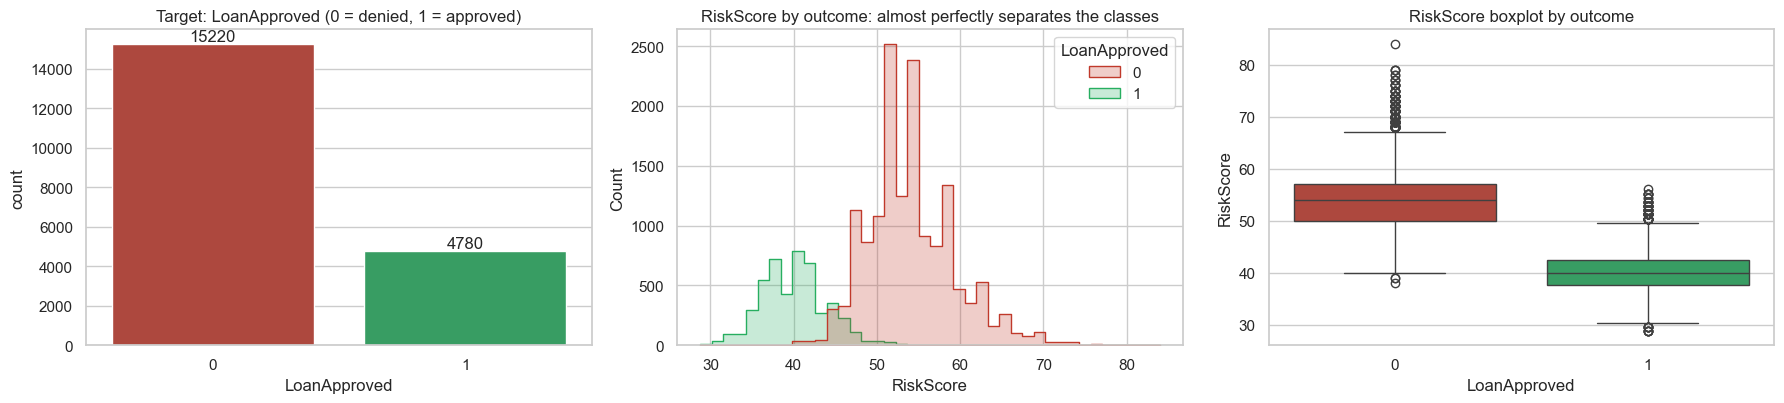

                 min    mean     max
LoanApproved                        
0            38.0000 54.1063 84.0000
1            28.8000 40.1334 56.0000
Point-biserial correlation RiskScore vs LoanApproved: -0.766
ROC-AUC of a one-feature model that only sees RiskScore: 0.9873
5-fold ROC-AUC WITHOUT RiskScore (legitimate)  : 0.9860
5-fold ROC-AUC WITH RiskScore (leaky)          : 0.9999


5-fold ROC-AUC WITH RiskScore (leaky)          : 0.9999


In [39]:
# ---- Target distribution ---------------------------------------------------------
vc = df[TARGET].value_counts().sort_index()
print(pd.DataFrame({"count": vc, "share": vc / len(df)}))
print(f"Imbalance ratio (denied : approved) = {vc[0] / vc[1]:.2f} : 1")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
sns.countplot(x=TARGET, data=df, ax=ax[0], palette=["#c0392b", "#27ae60"])
for c in ax[0].containers: ax[0].bar_label(c)
ax[0].set_title("Target: LoanApproved (0 = denied, 1 = approved)")

# ---- LEAKAGE CHECK: RiskScore vs. LoanApproved --------------------------------------
sns.histplot(data=df, x="RiskScore", hue=TARGET, bins=40, ax=ax[1], palette=["#c0392b", "#27ae60"], element="step")
ax[1].set_title("RiskScore by outcome: almost perfectly separates the classes")
sns.boxplot(data=df, x=TARGET, y="RiskScore", ax=ax[2], palette=["#c0392b", "#27ae60"])
ax[2].set_title("RiskScore boxplot by outcome")
plt.tight_layout(); plt.show()

print(df.groupby(TARGET)["RiskScore"].agg(["min", "mean", "max"]))
print("Point-biserial correlation RiskScore vs LoanApproved:", round(df["RiskScore"].corr(df[TARGET]), 3))

# Quick proof: a tiny model using ONLY RiskScore
from sklearn.model_selection import cross_val_score
auc_leak = cross_val_score(LogisticRegression(), df[["RiskScore"]], df[TARGET], cv=5, scoring="roc_auc").mean()
print(f"ROC-AUC of a one-feature model that only sees RiskScore: {auc_leak:.4f}")

# Does the leak matter when ALL the other numeric features are available too? (quick numeric-only baseline)
num_feats = [c for c in df.columns if df[c].dtype.kind in "if" and c not in (TARGET, "RiskScore")]   # all numeric columns except target/leak
quick = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("lr", LogisticRegression(max_iter=3000))])
for label, cols in [("WITHOUT RiskScore (legitimate)", num_feats), ("WITH RiskScore (leaky)", num_feats + LEAKY)]:
    auc = cross_val_score(quick, df[cols], df[TARGET], cv=5, scoring="roc_auc").mean()
    print(f"5-fold ROC-AUC {label:32s}: {auc:.4f}")

## What this code does: Shows the class balance and tests whether RiskScore leaks the target.

**What the code does.** Shows the class balance, then investigates the suspicious `RiskScore` column: histograms and boxplots per outcome, correlation with the target, and two quick models (RiskScore only; all numeric features with and without RiskScore).

**Why.** *Target leakage* (a feature that contains information about the label that would not exist at prediction time) produces models that look brilliant in the notebook and fail in production. The generator script in your archive shows `RiskScore` is multiplied by 0.8 *if the loan was approved*: it is computed **after** and **using** the decision.

**Interpretation of the output.**
* Class balance: 15,220 denied vs 4,780 approved: **76.1% / 23.9%, imbalance 3.18 : 1**. Accuracy will mislead; we will stratify splits and use PR-AUC and cost.
* `RiskScore` ranges 28.8 to 56 for approved and 38 to 84 for denied; correlation with the target is -0.77. **A model that sees only this one column reaches AUC 0.987.**
* Adding it to all other numeric features lifts AUC from **0.986 to 0.9999**: an almost perfect, and entirely fake, model.

**Decision.** **Exclude `RiskScore` from all features** (it is stored in the `LEAKY` list). We will use it only for one purpose later: as the regression *target* in the classification-versus-regression comparison. We will use stratified sampling because of the 3.2 : 1 imbalance.

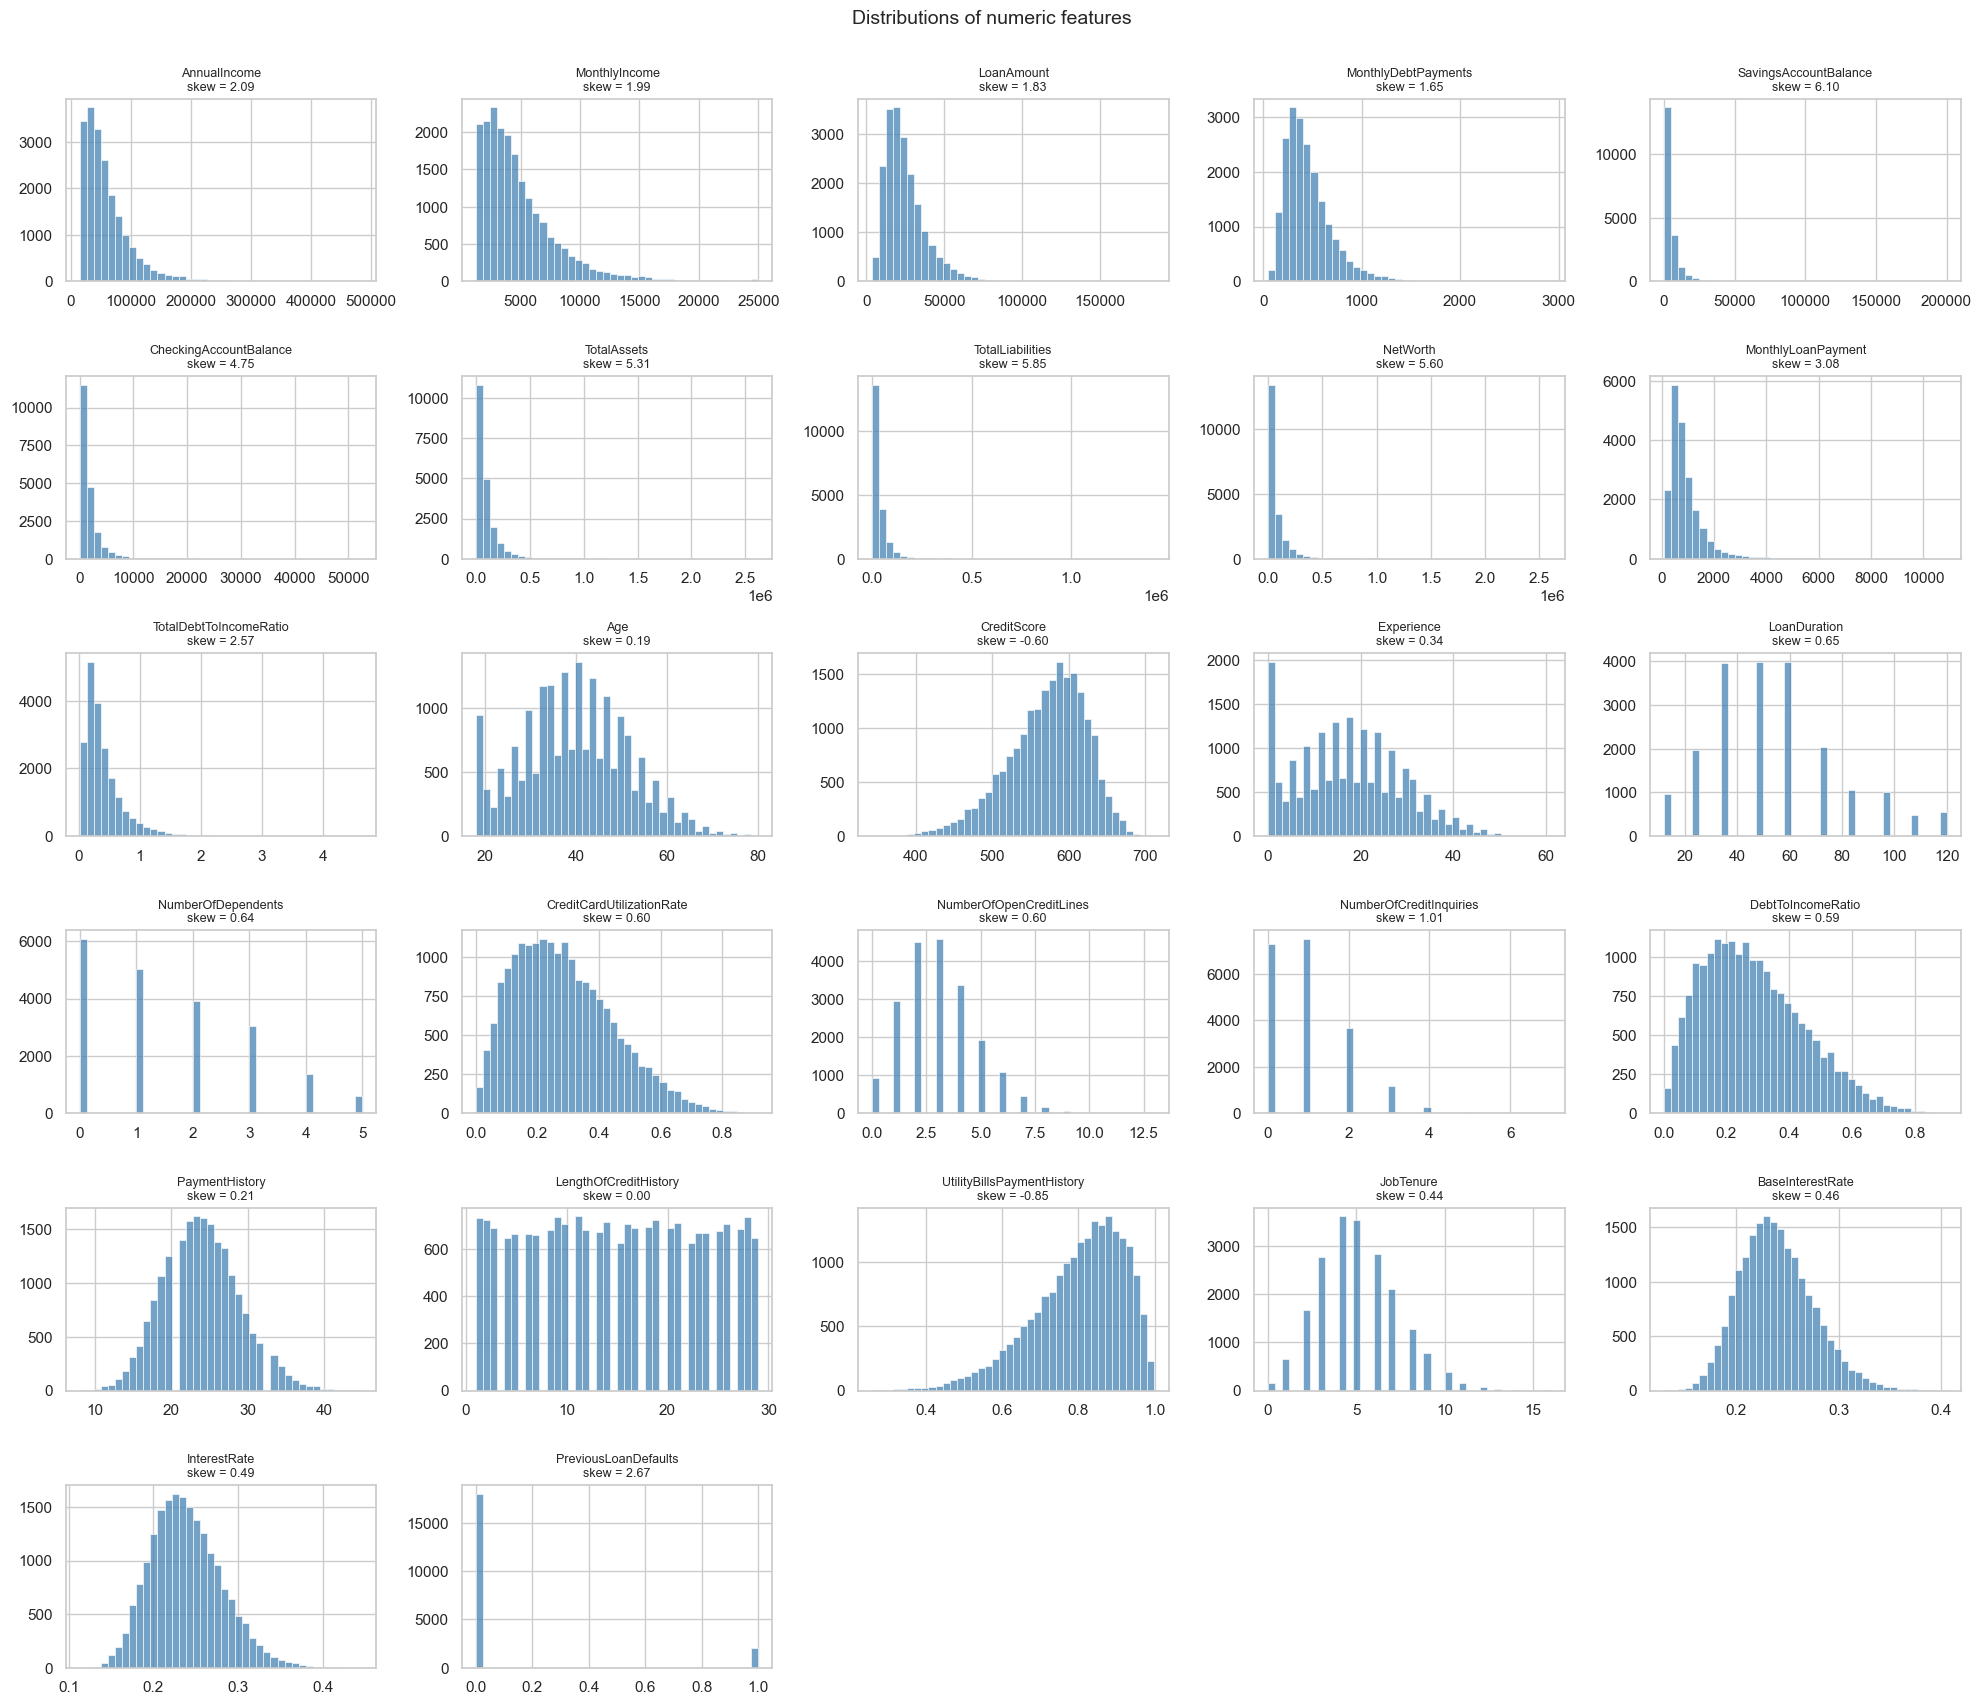

In [42]:
# ---- Histograms of ALL numeric features (+ skewness in the title) ---------------------
num_cols = NUMERIC_SKEWED + NUMERIC_OTHER + BINARY_NUMERIC
fig, axes = plt.subplots(6, 5, figsize=(20, 17))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col].dropna(), bins=40, kde=False, ax=ax, color="steelblue")
    ax.set_title(f"{col}\nskew = {df[col].skew():.2f}", fontsize=9); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.ravel()[len(num_cols):]: ax.axis("off")
plt.suptitle("Distributions of numeric features", y=1.002, fontsize=14); plt.tight_layout(); plt.show()

## What this code does: Plots a histogram, with skewness, for every numeric feature.

**What the code does.** Draws a histogram for each of the 27 numeric features with its skewness in the title.

**Why.** Distribution shape drives preprocessing: strongly skewed variables may need a transform, spikes reveal artificial values, and discrete variables are recognised.

**Interpretation.** Money variables (assets, liabilities, net worth, balances, income, loan amount) are heavily right-skewed with long tails. `CreditScore` is slightly left-skewed and capped near 712; `LoanDuration` takes only a handful of values (12 to 120 months); counts such as `NumberOfDependents` are discrete; most ratios (utilisation, DTI) look like Beta-shaped distributions bounded at 0 to 1. No variable shows impossible values (negative ages, etc.).

**Decision.** Group the money variables as "skewed" for the pipeline (and test log-scaling), standardise everything else, and keep discrete counts as numeric.

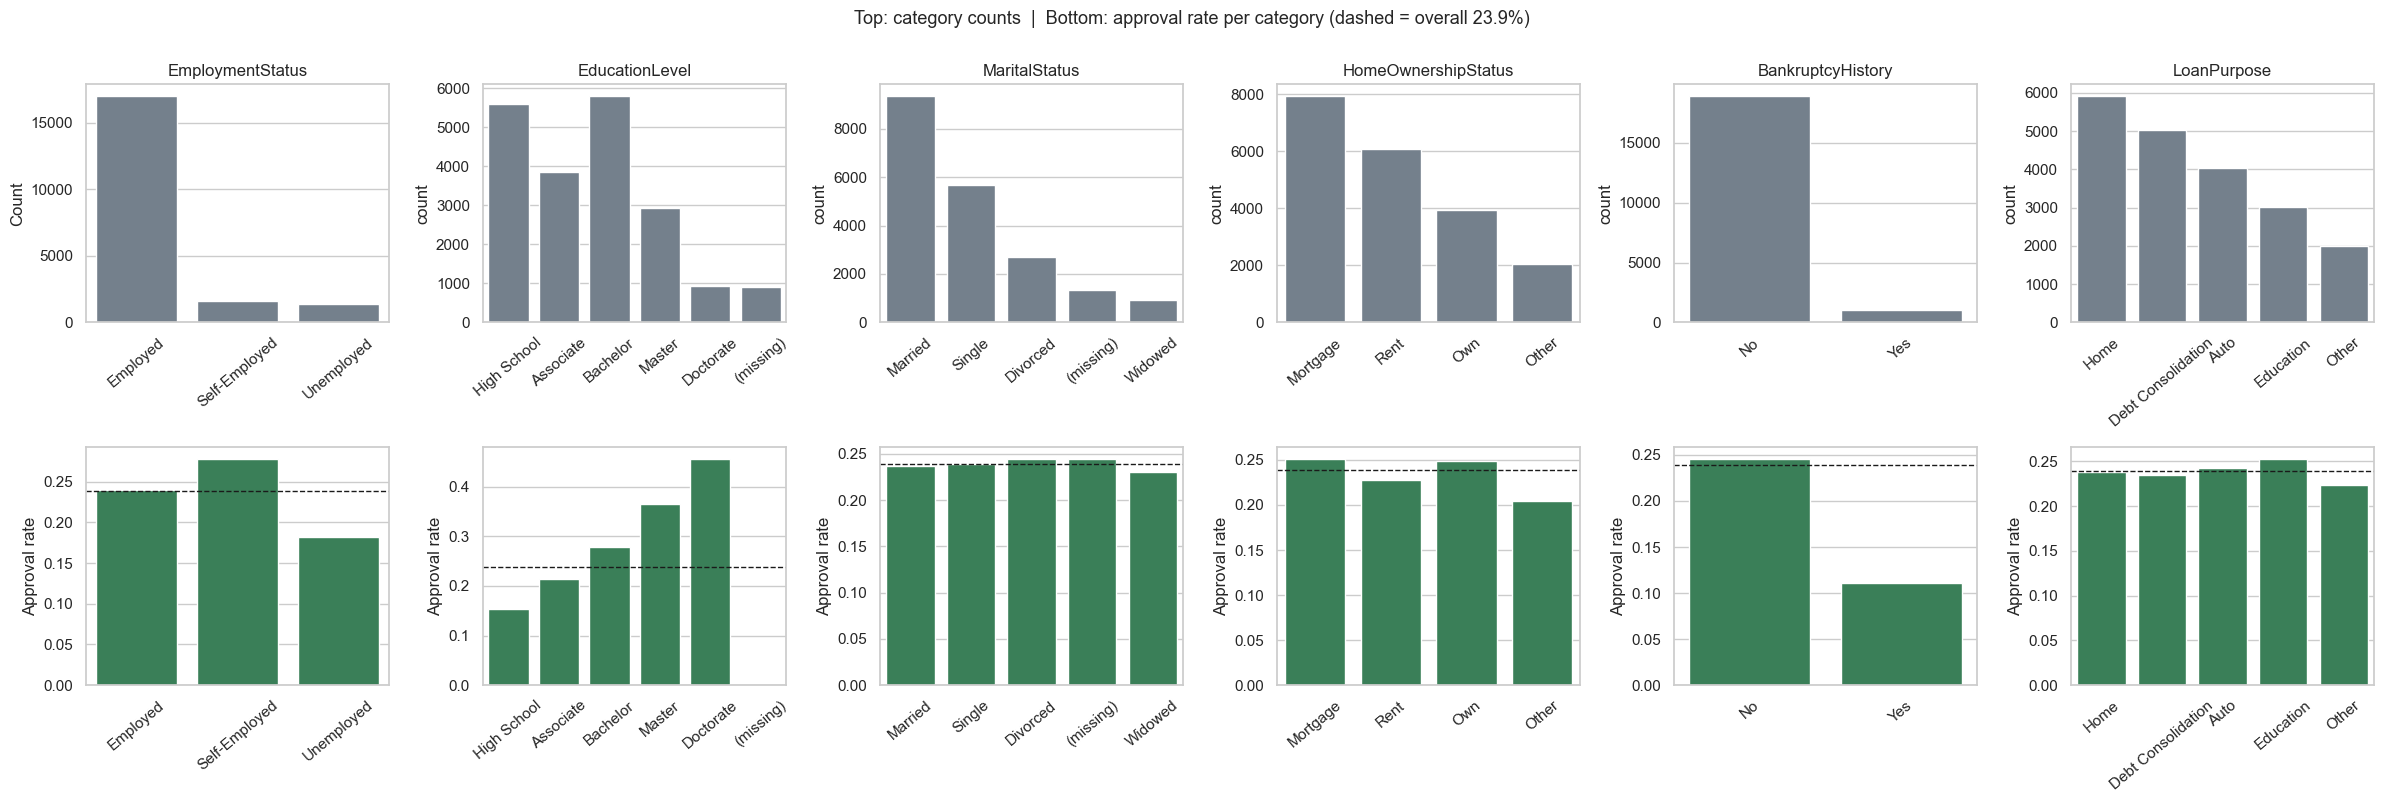

In [45]:
# ---- Categorical features: counts AND approval rate per category ---------------------
cat_cols = ["EmploymentStatus", "EducationLevel", "MaritalStatus", "HomeOwnershipStatus", "BankruptcyHistory", "LoanPurpose"]
fig, axes = plt.subplots(2, 6, figsize=(24, 8))
for j, col in enumerate(cat_cols):
    tmp = df[col].fillna("(missing)")
    order = EDU_ORDER + ["(missing)"] if col == "EducationLevel" else tmp.value_counts().index
    sns.countplot(x=tmp, order=order, ax=axes[0, j], color="slategray")
    axes[0, j].set_title(col); axes[0, j].tick_params(axis="x", rotation=40); axes[0, j].set_xlabel("")
    rate = df.assign(_c=tmp).groupby("_c")[TARGET].mean().reindex(order)
    sns.barplot(x=rate.index, y=rate.values, order=order, ax=axes[1, j], color="seagreen")
    axes[1, j].axhline(df[TARGET].mean(), color="k", ls="--", lw=1)
    axes[1, j].set_ylabel("Approval rate"); axes[1, j].tick_params(axis="x", rotation=40); axes[1, j].set_xlabel("")
axes[0, 0].set_ylabel("Count")
plt.suptitle("Top: category counts  |  Bottom: approval rate per category (dashed = overall 23.9%)", y=1.0, fontsize=13)
plt.tight_layout(); plt.show()

## What this code does: Plots category counts and the approval rate within each category.

**What the code does.** For six categorical variables, the top row shows how many applicants fall in each category and the bottom row the **approval rate per category** (dashed line = overall 23.9%).

**Why.** A category is useful only if it separates outcomes. Rare categories also need special attention in encoding.

**Interpretation.**
* **EducationLevel** shows a clear staircase (about 15% approval for High School up to about 45% for Doctorate), and the `(missing)` bar is **zero**.
* **BankruptcyHistory = Yes** drops approval to about 11% vs 25%.
* **Unemployed** applicants have lower approval (18%); self-employed slightly higher (28%).
* `HomeOwnershipStatus = Other` is lower (about 20%).
* **MaritalStatus and LoanPurpose** are almost flat around the average: they look uninformative.

**Decision.** Encode education as **ordinal** (the order is meaningful); one-hot encode the nominal variables; keep Yes/No bankruptcy as one binary column. Expect marital status and loan purpose to be weak predictors, which is confirmed statistically in Step 3.3 and acts as a hint for the compliance discussion.

#### 3.3 Investigate relationships between features
Boxplots by outcome, correlation matrix, pair plot, non-linear approval-rate curves, statistical tests and a multicollinearity check.

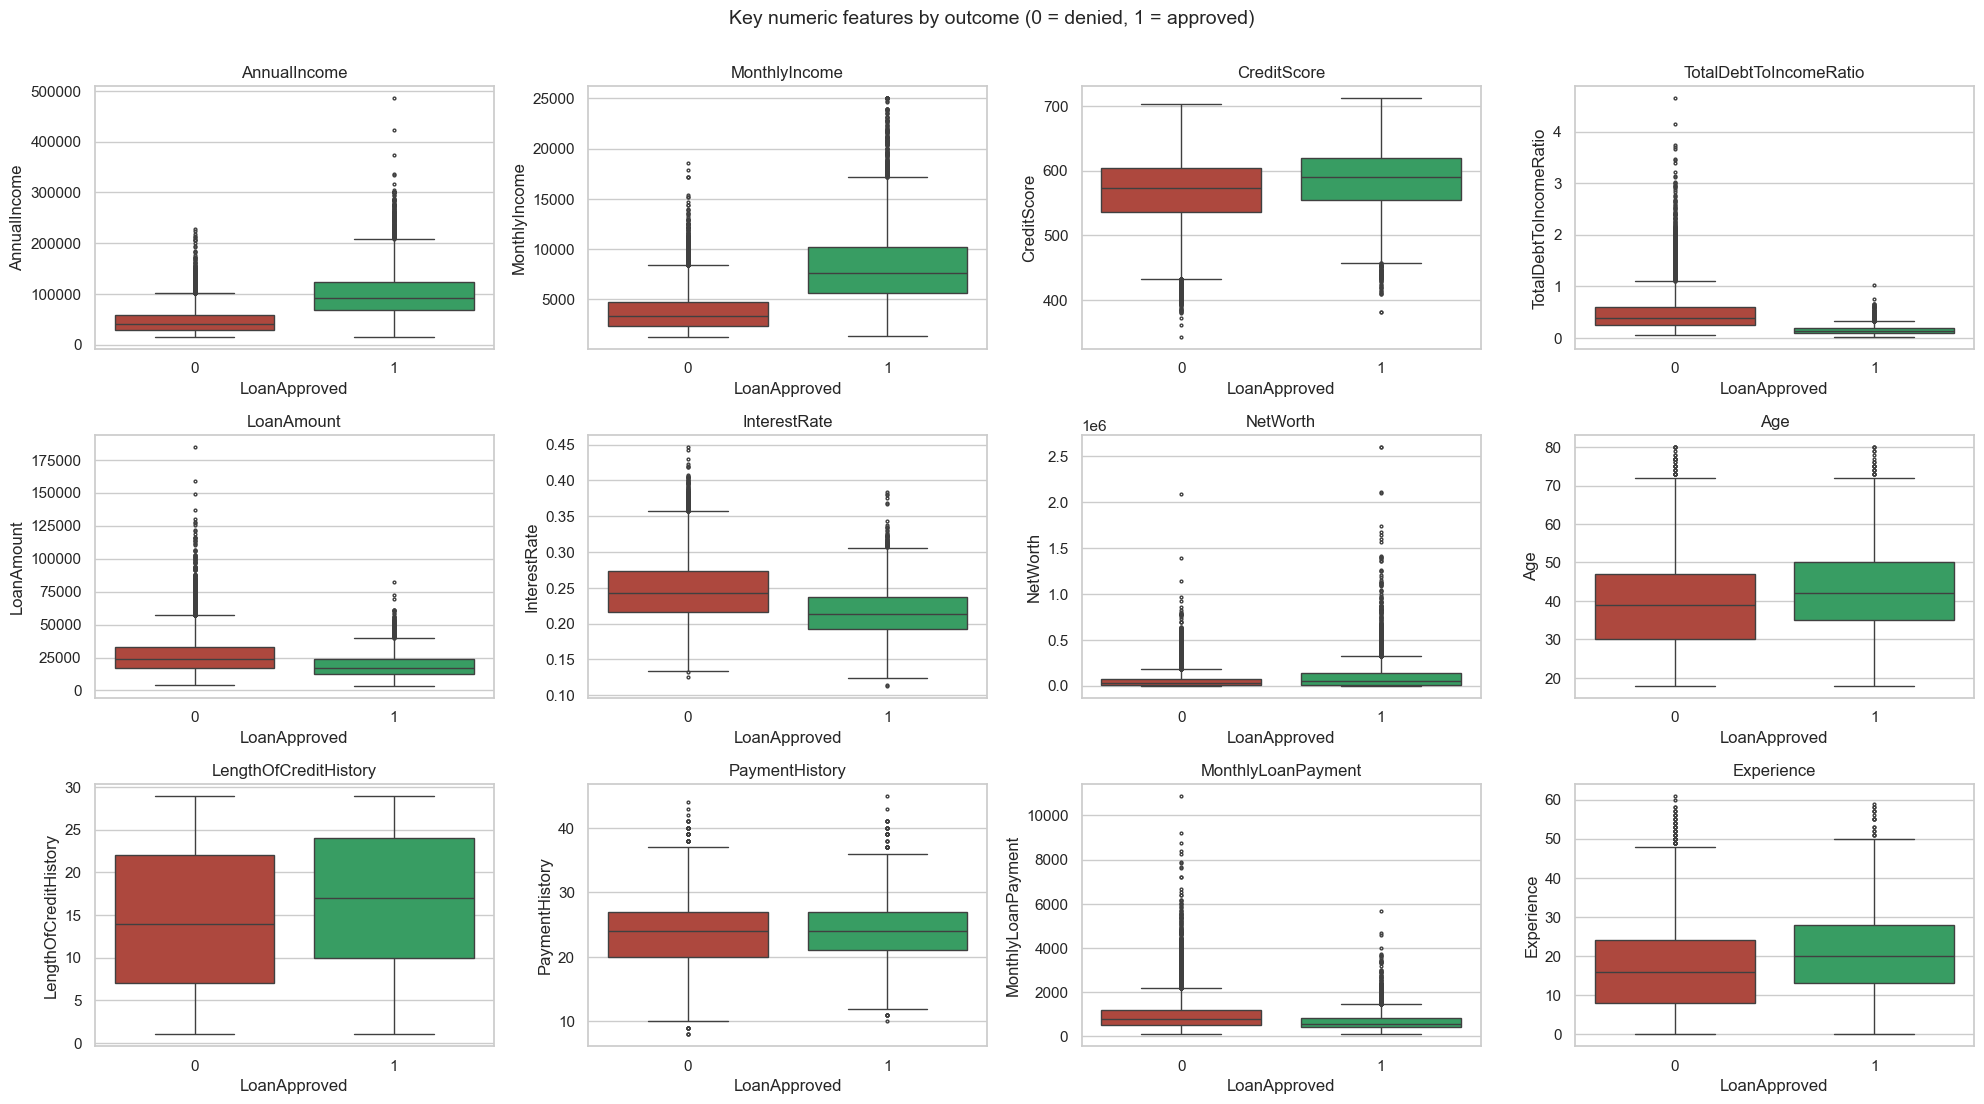

In [49]:
# ---- Boxplots of the most relevant numeric features, split by outcome --------------------
key_num = ["AnnualIncome", "MonthlyIncome", "CreditScore", "TotalDebtToIncomeRatio", "LoanAmount", "InterestRate",
           "NetWorth", "Age", "LengthOfCreditHistory", "PaymentHistory", "MonthlyLoanPayment", "Experience"]
fig, axes = plt.subplots(3, 4, figsize=(20, 11))
for ax, col in zip(axes.ravel(), key_num):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax, palette=["#c0392b", "#27ae60"], showfliers=True, fliersize=2)
    ax.set_title(col); ax.set_xlabel("LoanApproved")
plt.suptitle("Key numeric features by outcome (0 = denied, 1 = approved)", y=1.002, fontsize=14)
plt.tight_layout(); plt.show()

## What this code does: Compares key numeric features between approved and denied applicants using boxplots.

**What the code does.** Boxplots of 12 important numeric features, split by outcome (0 = denied, 1 = approved).

**Why.** Boxplots compare medians, spread and outliers between the two classes in one picture, showing which variables separate the outcome.

**Interpretation.** Approved applicants have visibly **higher income, lower total debt-to-income, lower interest rate and lower loan amount**, with little overlap between the boxes for the first two. `CreditScore`, `NetWorth`, `Age` and `LengthOfCreditHistory` shift in the expected direction but overlap more. Many dots beyond the whiskers on money variables confirm long right tails.

**Decision.** Income, debt-to-income and loan terms are likely to be the dominant signals. Outliers are *real* high values (rich or heavily indebted applicants), not errors, so we **keep** them rather than deleting rows; a scaler and a regularised linear model handle them.

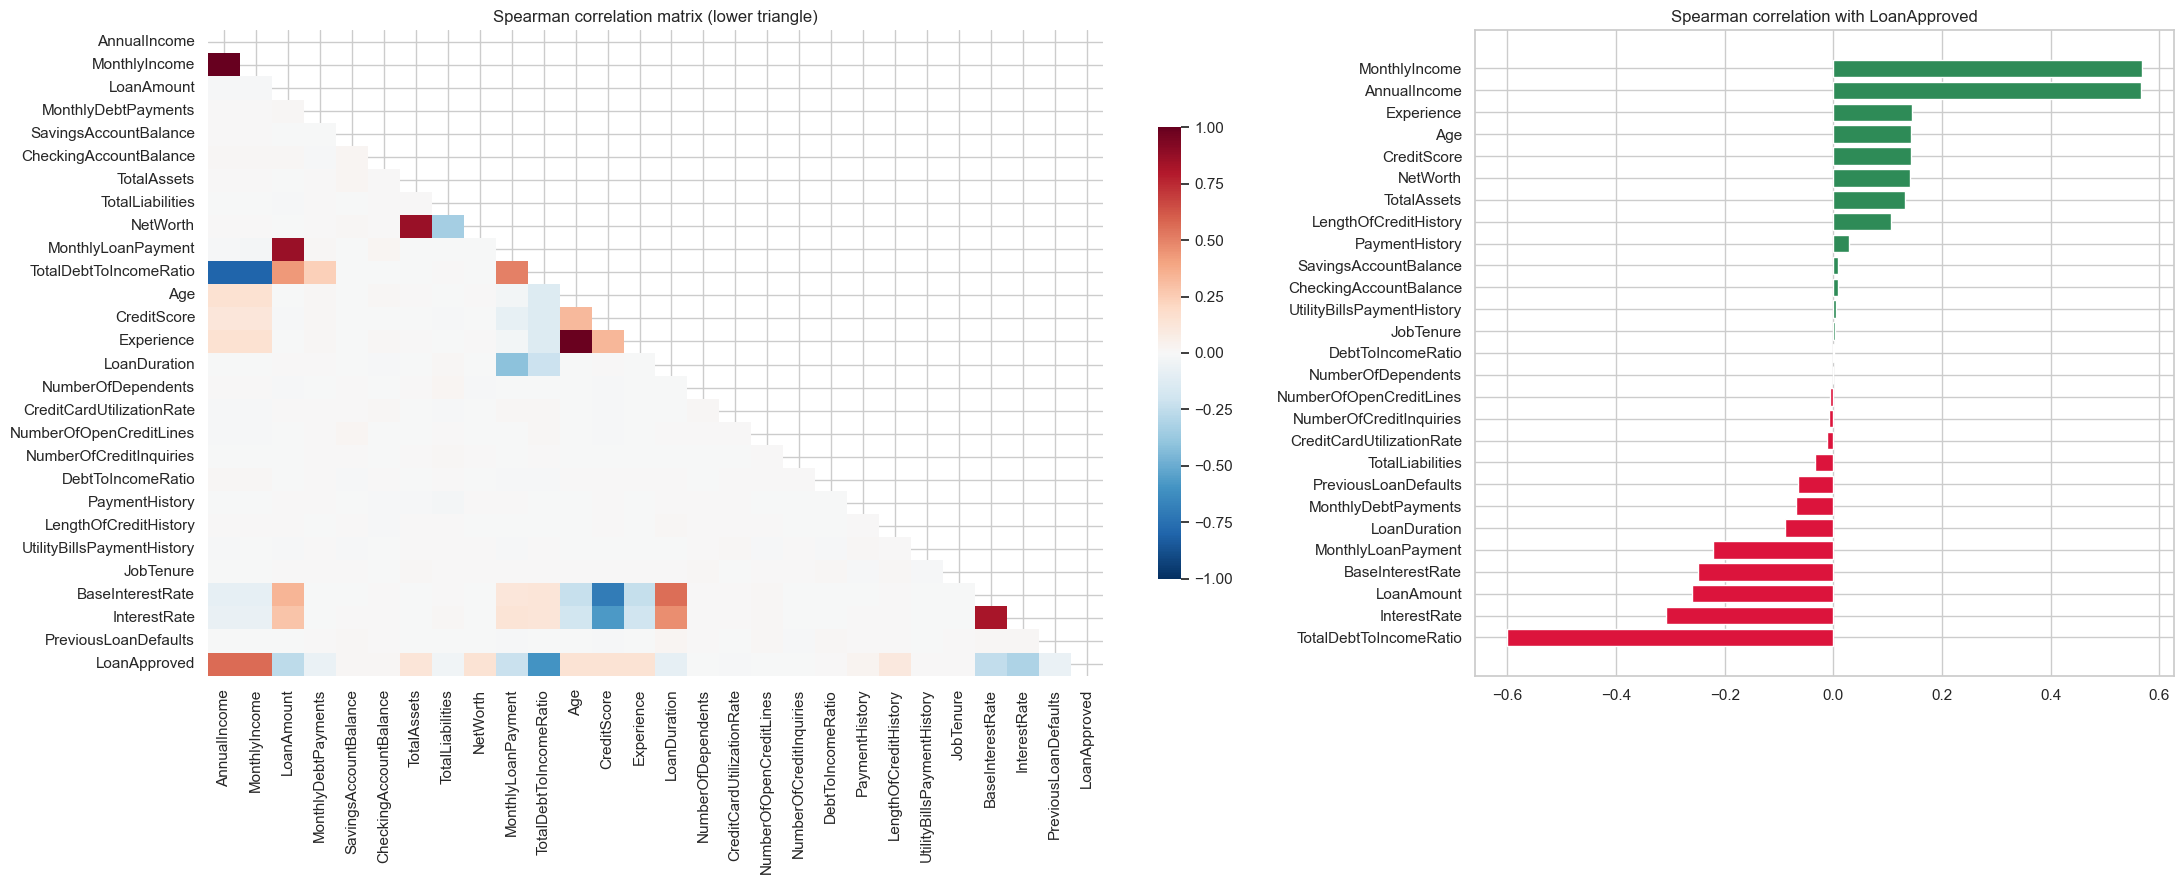

,feature_1,feature_2,rho
0,AnnualIncome,MonthlyIncome,0.9962
243,Age,Experience,0.9847
59,LoanAmount,MonthlyLoanPayment,0.8667
148,TotalAssets,NetWorth,0.8602
372,BaseInterestRate,InterestRate,0.8206
35,MonthlyIncome,TotalDebtToIncomeRatio,-0.8031
9,AnnualIncome,TotalDebtToIncomeRatio,-0.8001


In [52]:
# ---- Correlation matrix (Spearman is robust to the skew we saw) --------------------------
corr_cols = [c for c in NUMERIC_SKEWED + NUMERIC_OTHER + BINARY_NUMERIC] + [TARGET]
corr = df[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(1, 2, figsize=(22, 9), gridspec_kw={"width_ratios": [1.6, 1]})
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=False, ax=ax[0], cbar_kws={"shrink": .7})
ax[0].set_title("Spearman correlation matrix (lower triangle)")
tc = corr[TARGET].drop(TARGET).sort_values()
ax[1].barh(tc.index, tc.values, color=np.where(tc.values > 0, "seagreen", "crimson")); ax[1].set_title("Spearman correlation with LoanApproved")
plt.tight_layout(); plt.show()

# ---- Strongly collinear pairs (|rho| > 0.8) -------------------------------------------------
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("rho").reset_index()
            .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
display(pairs[pairs["rho"].abs() > 0.8].sort_values("rho", key=abs, ascending=False))

## What this code does: Draws the Spearman correlation heatmap and lists highly correlated feature pairs.

**What the code does.** Computes a **Spearman** correlation matrix (robust to skew and outliers), draws the heatmap, ranks every feature's correlation with the target, and lists feature pairs with |rho| > 0.8.

**Why.** Correlation with the target hints at predictive power; correlation *between* features reveals redundancy that destabilises linear-model coefficients.

**Interpretation.** Strongest links to approval are income (positive), total debt-to-income, interest rate and loan amount (negative). Highly collinear pairs (|rho| > 0.8): `AnnualIncome`-`MonthlyIncome` (0.996), `Age`-`Experience` (0.985), `LoanAmount`-`MonthlyLoanPayment` (0.87), `TotalAssets`-`NetWorth` (0.86), `BaseInterestRate`-`InterestRate` (0.82), and income with `TotalDebtToIncomeRatio` (about -0.80).

**Decision.** Redundancy is mostly *structural* (one variable is a function of another). Drop `AnnualIncome` (already decided), and rely on **L2 regularisation and L1 feature selection** in the pipeline instead of manually deleting the other pairs. `Age` vs `Experience` will matter again in the fairness discussion.

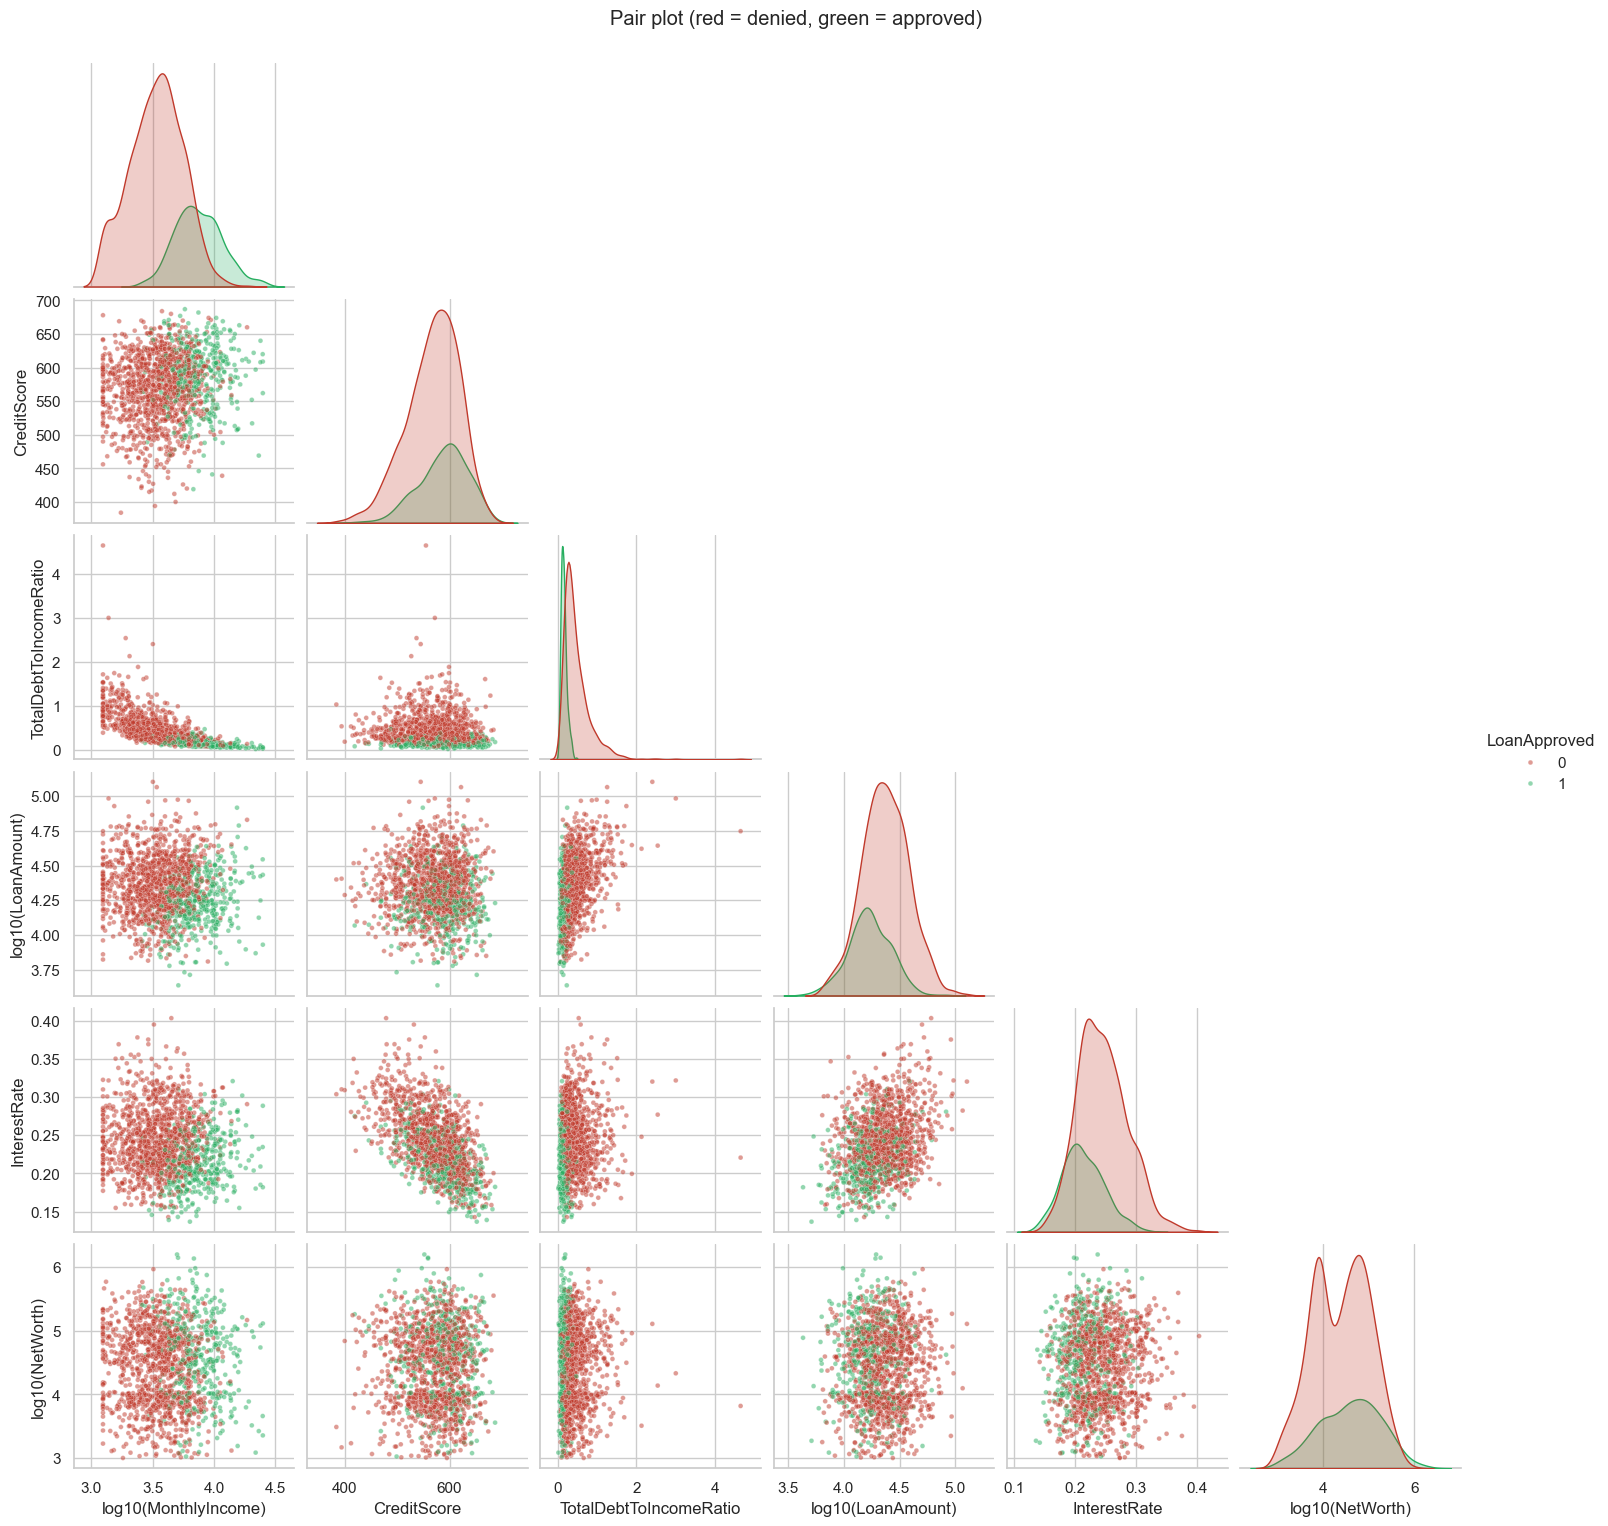

In [55]:
# ---- Pair plot of the most informative features (sample of 1,500 rows to keep it readable) -------
pp_cols = ["MonthlyIncome", "CreditScore", "TotalDebtToIncomeRatio", "LoanAmount", "InterestRate", "NetWorth"]
sample = df[pp_cols + [TARGET]].sample(1500, random_state=RANDOM_STATE).copy()
for c in ["MonthlyIncome", "LoanAmount", "NetWorth"]:
    sample[c] = np.log10(sample[c]); sample.rename(columns={c: f"log10({c})"}, inplace=True)
g = sns.pairplot(sample, hue=TARGET, palette={0: "#c0392b", 1: "#27ae60"}, corner=True, plot_kws={"s": 12, "alpha": .5}, diag_kind="kde")
g.fig.suptitle("Pair plot (red = denied, green = approved)", y=1.02); plt.show()

## What this code does: Plots pairwise relationships of six key features, coloured by outcome.

**What the code does.** A pair plot of six key features (money variables on log scale) coloured by outcome, on a 1,500-row sample.

**Why.** It shows two-way relationships and class separation at once, and whether a straight line could separate approved from denied.

**Interpretation.** In the plots combining income with debt-to-income and loan amount, approved (green) and denied (red) points occupy **largely separate regions**, with a mixed band along the border. This is what a roughly *linear* decision boundary looks like, which explains why a linear model will do so well. Interest rate relates strongly to credit score by construction.

**Decision.** Start with (and fully tune) a regularised linear model; non-linear models are challengers, not defaults.

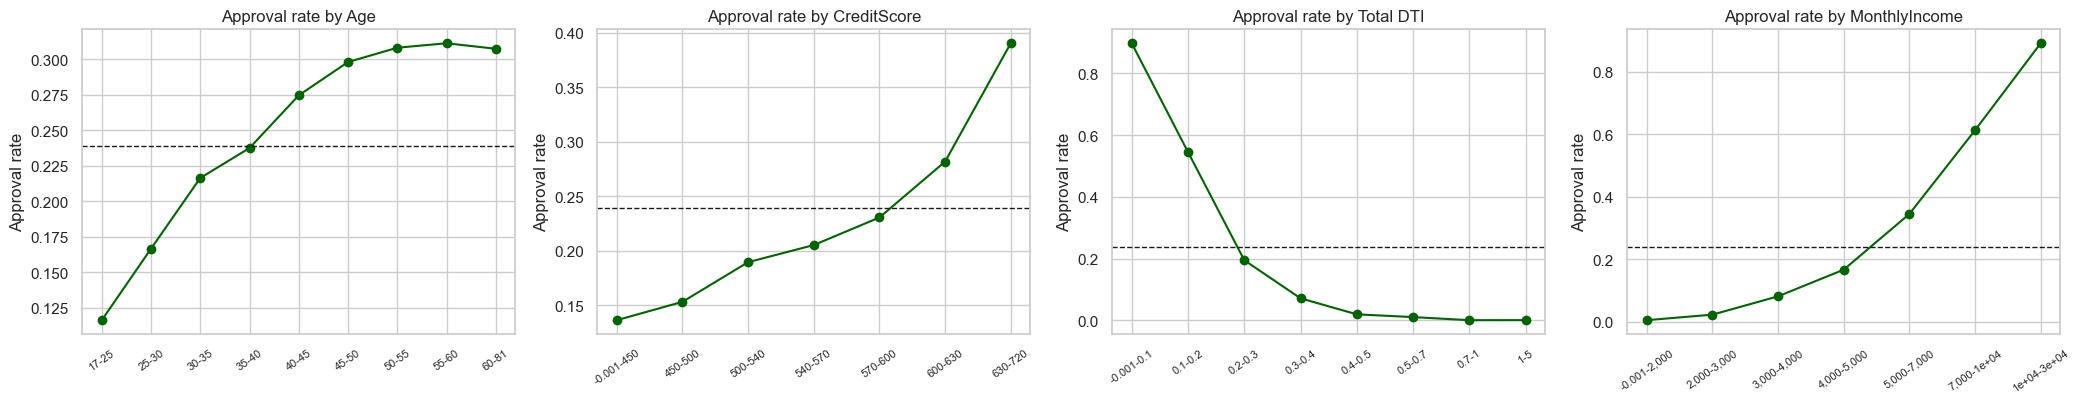

Spearman(Age, approved)       = 0.1434
Spearman(|Age-40|, approved)  = -0.0392


In [58]:
# ------------------------------------------------------------------------------
# Non-linear relationships: approval rate across bins of a feature
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
def rate_plot(ax, series, bins, title, labels=None):
    b = pd.cut(series, bins=bins, labels=labels, include_lowest=True)
    r = df.groupby(b, observed=True)[TARGET].agg(["mean", "size"])
    ax.plot(range(len(r)), r["mean"].values, marker="o", color="darkgreen")
    ax.set_xticks(range(len(r))); ax.set_xticklabels([f"{i.left:,.4g}-{i.right:,.4g}" for i in r.index], rotation=35, fontsize=8)
    ax.set_title(title); ax.set_ylabel("Approval rate"); ax.axhline(df[TARGET].mean(), color="k", ls="--", lw=1)
    return r
r_age = rate_plot(axes[0], df["Age"], [17, 25, 30, 35, 40, 45, 50, 55, 60, 81], "Approval rate by Age")
rate_plot(axes[1], df["CreditScore"], [0, 450, 500, 540, 570, 600, 630, 720], "Approval rate by CreditScore")
rate_plot(axes[2], df["TotalDebtToIncomeRatio"], [0, .1, .2, .3, .4, .5, .7, 1, 5], "Approval rate by Total DTI")
rate_plot(axes[3], df["MonthlyIncome"], [0, 2000, 3000, 4000, 5000, 7000, 10000, 30000], "Approval rate by MonthlyIncome")
plt.tight_layout(); plt.show()

# Does a "distance from age 40" feature carry marginal signal? (the plot above shows a plateau, NOT a clear inverted-U,
# so this idea must be judged by the ablation experiment in Step 5.7, not by this simple correlation)
df["_AgeDev"] = (df["Age"] - 40).abs()
print("Spearman(Age, approved)       =", round(df["Age"].corr(df[TARGET], method="spearman"), 4))
print("Spearman(|Age-40|, approved)  =", round(df["_AgeDev"].corr(df[TARGET], method="spearman"), 4))
df.drop(columns="_AgeDev", inplace=True)

## What this code does: Plots approval rate across bins of age, credit score, debt-to-income and income.

**What the code does.** Plots the approval rate across bins of Age, CreditScore, Total DTI and MonthlyIncome, then compares the correlation of `Age` and of `|Age - 40|` with approval.

**Why.** Correlation measures only straight-line relationships. Binning approval rates reveals curves and thresholds, which can suggest engineered features.

**Interpretation.**
* **Total DTI:** approval collapses from about 90% for DTI < 0.1 to nearly 0% above 0.4, a steep, non-linear relationship.
* **MonthlyIncome:** approval rises from about 0% under \$2,000 to about 90% above \$10,000.
* **CreditScore:** a steady rise, steeper above 600.
* **Age:** approval *rises* from about 12% (under 25) to about 31% (over 55) and then **plateaus**; it is not an inverted U. The idea of "distance from age 40" does *not* show up in the simple correlation (Spearman 0.14 for Age, -0.04 for |Age - 40|).

**Decision.** I will still create `AgeDeviation` as a *candidate* feature, because the age effect may only appear after controlling for income and experience, but I will keep it **only if the ablation experiment in Step 5.7 proves it helps**. Evidence, not intuition, decides.

In [61]:
# ------------------------------------------------------------------------------
# (a) Normality: justifies using non-parametric tests for numeric features
# ------------------------------------------------------------------------------
sample_for_norm = df.sample(5000, random_state=RANDOM_STATE)
norm = pd.Series({c: stats.normaltest(sample_for_norm[c].dropna())[1] for c in ["Age", "CreditScore", "MonthlyIncome", "LoanAmount", "TotalDebtToIncomeRatio"]})
print("D'Agostino normality test p-values (p < 0.05 => NOT normal):")
print(norm.apply(lambda v: f"{v:.2e}").to_string())

# ------------------------------------------------------------------------------
# (b) Numeric features vs target: Mann-Whitney U test + effect size.
#     Effect size = |AUC - 0.5| * 2 (a.k.a. Cliff's delta / rank-biserial correlation, range 0-1).
#     With n = 20,000 EVERY feature tends to be 'significant', so effect size is what matters.
# ------------------------------------------------------------------------------
rows = []
for c in NUMERIC_SKEWED + NUMERIC_OTHER + BINARY_NUMERIC:
    a1 = df.loc[df[TARGET] == 1, c].dropna(); a0 = df.loc[df[TARGET] == 0, c].dropna()
    u, p = stats.mannwhitneyu(a1, a0, alternative="two-sided")
    auc = u / (len(a1) * len(a0))
    rows.append((c, p, 2 * abs(auc - 0.5), "higher in approved" if auc > .5 else "lower in approved"))
mw = pd.DataFrame(rows, columns=["feature", "p_value", "effect_size", "direction"]).set_index("feature")
mw["p_bonferroni"] = (mw["p_value"] * len(mw)).clip(upper=1)         # multiple-comparison correction
mw["significant_0.05"] = mw["p_bonferroni"] < 0.05
display(mw.sort_values("effect_size", ascending=False))

# ------------------------------------------------------------------------------
# (c) Categorical features vs target: Chi-square test + Cramer's V (effect size, 0-1)
# ------------------------------------------------------------------------------
rows = []
for c in NOMINAL + BINARY_CAT + ORDINAL:
    tbl = pd.crosstab(df[c].fillna("(missing)"), df[TARGET])
    chi2, p, dof, _ = stats.chi2_contingency(tbl)
    v = np.sqrt(chi2 / (tbl.values.sum() * (min(tbl.shape) - 1)))
    rows.append((c, chi2, dof, p, v))
cv_tbl = pd.DataFrame(rows, columns=["feature", "chi2", "dof", "p_value", "cramers_V"]).set_index("feature")
display(cv_tbl.sort_values("cramers_V", ascending=False))

# ------------------------------------------------------------------------------
# (d) Is the income-floor group different? and is 'missing education' special?
# ------------------------------------------------------------------------------
tbl = pd.crosstab(df["EducationLevel"].isna(), df[TARGET]); print("\nEducation missing vs approval:\n", tbl)
print("Fisher exact p-value:", f"{stats.fisher_exact(tbl)[1]:.2e}")

D'Agostino normality test p-values (p < 0.05 => NOT normal):
Age                       5.18e-13
CreditScore               1.47e-50
MonthlyIncome             0.00e+00
LoanAmount                0.00e+00
TotalDebtToIncomeRatio    0.00e+00


,p_value,effect_size,direction,p_bonferroni,significant_0.05
feature,,,,,
TotalDebtToIncomeRatio,0.0000,0.8128,lower in approved,0.0000,True
MonthlyIncome,0.0000,0.7700,higher in approved,0.0000,True
AnnualIncome,0.0000,0.7674,higher in approved,0.0000,True
InterestRate,0.0000,0.4169,lower in approved,0.0000,True
LoanAmount,0.0000,0.3522,lower in approved,0.0000,True
BaseInterestRate,0.0000,0.3372,lower in approved,0.0000,True
MonthlyLoanPayment,0.0000,0.3008,lower in approved,0.0000,True
Experience,0.0000,0.1957,higher in approved,0.0000,True
Age,0.0000,0.1941,higher in approved,0.0000,True


,chi2,dof,p_value,cramers_V
feature,,,,
EducationLevel,"1,068.9276",5,0.0000,0.2312
BankruptcyHistory,99.3709,1,0.0000,0.0705
EmploymentStatus,38.5065,2,0.0000,0.0439
HomeOwnershipStatus,26.3288,3,0.0000,0.0363
LoanPurpose,6.6957,4,0.1529,0.0183
MaritalStatus,1.3740,4,0.8487,0.0083



Education missing vs approval:
 LoanApproved        0     1
EducationLevel             
False           14319  4780
True              901     0
Fisher exact p-value: 3.11e-110


## What this code does: Runs normality, Mann-Whitney, chi-square and Fisher tests with effect sizes.

**What the code does.** (a) D'Agostino normality tests. (b) For each numeric feature a **Mann-Whitney U test** (approved vs denied) with an **effect size** (|2 x AUC - 1|, range 0 to 1) and Bonferroni correction. (c) For each categorical feature a **chi-square test** with **Cramer's V**. (d) Fisher exact test for missing education.

**Why.** Plots can mislead; tests quantify whether differences are real. With 20,000 rows nearly everything is "significant", so **effect size** is the number to read. Non-parametric tests are used because the normality test rejects normality for every variable checked (all p < 1e-12).

**Interpretation of the output.**
* Largest numeric effects: **TotalDebtToIncomeRatio 0.81**, **MonthlyIncome 0.77**, `AnnualIncome` 0.77, **InterestRate 0.42**, `LoanAmount` 0.35, `BaseInterestRate` 0.34, `MonthlyLoanPayment` 0.30. Medium/small: Experience, Age, CreditScore, NetWorth (about 0.19).
* **Not significant after correction:** utilisation rate, savings and checking balances, inquiries, open credit lines, utility-bill history, job tenure, DTI (the other one), number of dependents (effect < 0.015).
* Categorical: **EducationLevel V = 0.23** (includes the missing group), bankruptcy 0.07, employment 0.04, home ownership 0.04. **MaritalStatus (p = 0.85) and LoanPurpose (p = 0.15) are not related to approval.**
* Missing education vs approval: Fisher p = 3e-110.

**Decision.** The dominant signals are debt burden, income and pricing. Several features carry no signal and can be removed automatically by feature selection. Marital status being irrelevant supports excluding it on compliance grounds.

In [64]:
# ------------------------------------------------------------------------------
# Multicollinearity: Variance Inflation Factor (VIF) for the numeric features
# VIF_j = 1 / (1 - R^2_j) where R^2_j is from regressing feature j on all the others.
# Rule of thumb: VIF > 10 = severe collinearity.
# ------------------------------------------------------------------------------
from sklearn.linear_model import LinearRegression
Xv = df[NUMERIC_SKEWED + NUMERIC_OTHER + BINARY_NUMERIC].copy()
Xv = Xv.fillna(Xv.median())
Xv = (Xv - Xv.mean()) / Xv.std()
vif = {}
for c in Xv.columns:
    others = Xv.drop(columns=c)
    r2 = LinearRegression().fit(others, Xv[c]).score(others, Xv[c])
    vif[c] = 1 / (1 - r2) if r2 < 1 else np.inf
vif = pd.Series(vif).sort_values(ascending=False).to_frame("VIF")
display(vif.head(12))

# What drives the high VIFs? Verify the exact accounting identities in the data.
print("NetWorth ~ TotalAssets - TotalLiabilities  (rows that match exactly):",
      (df["NetWorth"] == (df["TotalAssets"] - df["TotalLiabilities"]).clip(lower=1000)).mean().round(3))
print("MonthlyIncome == AnnualIncome/12           (rows that match):",
      (np.isclose(df["MonthlyIncome"], df["AnnualIncome"] / 12, atol=1)).mean().round(3))
print("Corr(InterestRate, BaseInterestRate):", round(df["InterestRate"].corr(df["BaseInterestRate"]), 3))

,VIF
LoanAmount,inf
BaseInterestRate,inf
LoanDuration,inf
CreditScore,inf
MonthlyIncome,50.6899
AnnualIncome,49.8486
NetWorth,40.4858
TotalAssets,39.8024
Experience,29.7634
Age,29.6514


NetWorth ~ TotalAssets - TotalLiabilities  (rows that match exactly): 0.76
MonthlyIncome == AnnualIncome/12           (rows that match): 0.99
Corr(InterestRate, BaseInterestRate): 0.835


## What this code does: Computes variance inflation factors to detect multicollinearity.

**What the code does.** Computes the **Variance Inflation Factor** (VIF) for each numeric feature (how well it is predicted by the others) and verifies the suspected accounting identities in the data.

**Why.** Severe multicollinearity makes linear-model coefficients unstable and hard to interpret, a problem for a model that must be explained to regulators. VIF > 10 is the usual alarm.

**Interpretation.** `LoanAmount`, `LoanDuration`, `CreditScore` and `BaseInterestRate` have **infinite VIF**: `BaseInterestRate` is an *exact* linear combination of the other three (as the generator confirms). `MonthlyIncome`/`AnnualIncome` (about 50), `NetWorth`/`TotalAssets` (about 40) and `Age`/`Experience` (about 30) are also severe. 99% of rows satisfy `MonthlyIncome = AnnualIncome / 12`; the 76% match for `NetWorth = Assets - Liabilities` is lower because net worth has a floor of 1,000.

**Decision.** Predictions are not harmed by collinearity, but *interpretation* is. We use **L2 regularisation** (stabilises coefficients), **L1-based selection** inside the pipeline (drops redundant columns, tested in tuning), and we interpret importance with **permutation importance** (robust to collinearity) alongside coefficients.

#### 3.4 Create visualizations to help aid in EDA
The EDA contains **more than 40 individual chart panels** in these figure sets (each followed by its interpretation):
1. Business-cost charts (expected cost vs probability, accuracy paradox, threshold sensitivity)
2. Missing-value percentages and approval rate when missing
3. Target distribution and the `RiskScore` leakage histogram/boxplot
4. Histograms of all 27 numeric features
5. Category counts and approval rate for six categorical features
6. Boxplots of 12 key features by outcome
7. Income-consistency scatter and income distribution
8. Spearman correlation heatmap with a ranked correlation-with-target bar chart
9. Pair plot of six key features
10. Approval-rate curves for age, credit score, debt-to-income and income

Statistical tests (Mann-Whitney U, chi-square / Cramer's V, Fisher exact, normality tests, VIF) are in Step 3.3.

#### 3.5 Document potential data quality issues and their implications
The outlier and consistency checks come first; the summary table of every issue follows.

,n_outliers,pct
NetWorth,1564,7.8200
SavingsAccountBalance,1547,7.7350
TotalLiabilities,1533,7.6650
CheckingAccountBalance,1522,7.6100
TotalAssets,1442,7.2100
TotalDebtToIncomeRatio,1152,5.7600
MonthlyLoanPayment,1089,5.4450
AnnualIncome,947,4.7350
MonthlyIncome,925,4.6250
LoanAmount,746,3.7300


AnnualIncome == $15,000 (floor): 584 rows (2.9%) | approval rate there: 0.0%
AnnualIncome == $300,000 (cap):  26 rows (0.13%) | approval rate there: 100.0%

Rows where AnnualIncome is > 1.3x (12 x MonthlyIncome): 195 (0.97%)
{'min': 1.5, 'mean': 1.767, 'max': 2.0}


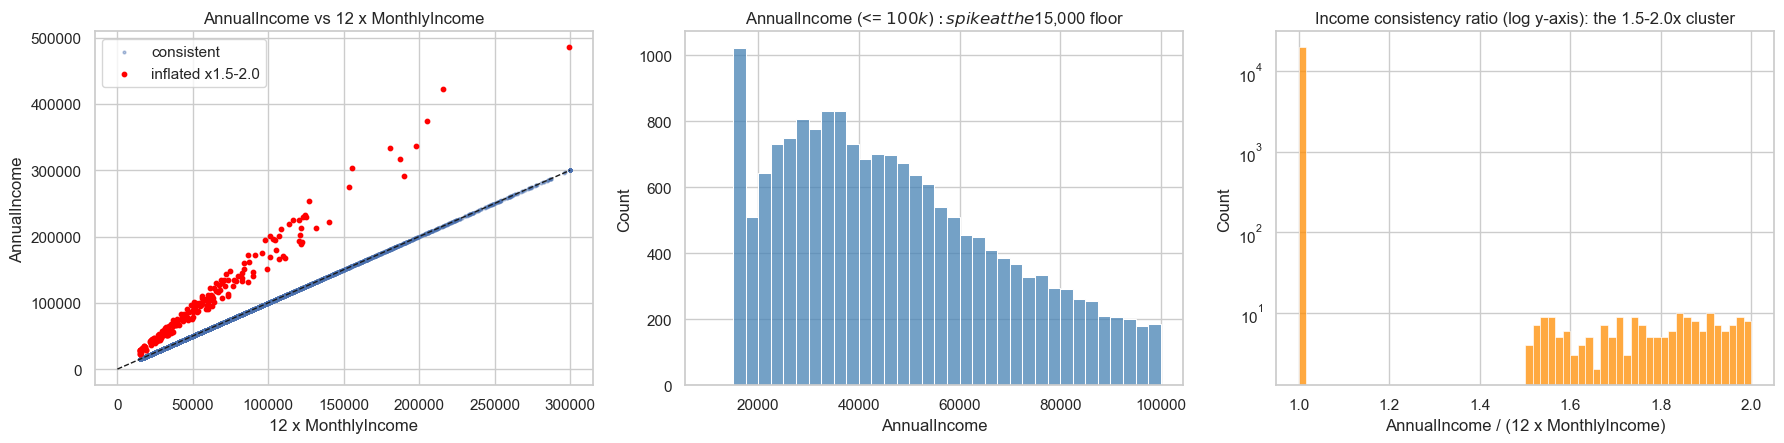

In [69]:
# ------------------------------------------------------------------------------
# Outlier detection (IQR rule: outside Q1-1.5*IQR .. Q3+1.5*IQR)
# ------------------------------------------------------------------------------
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = pd.DataFrame({"n_outliers": {c: iqr_outliers(df[c].dropna()) for c in NUMERIC_SKEWED + NUMERIC_OTHER}})
out["pct"] = out["n_outliers"] / len(df) * 100
display(out.sort_values("pct", ascending=False).head(12))

# ---- DATA-QUALITY ISSUE #2: AnnualIncome has an artificial floor and cap -------------------
n_floor = (df["AnnualIncome"] == 15_000).sum(); n_cap = (df["AnnualIncome"] == 300_000).sum()
print(f"AnnualIncome == $15,000 (floor): {n_floor} rows ({n_floor/len(df):.1%}) | approval rate there: {df.loc[df.AnnualIncome==15000, TARGET].mean():.1%}")
print(f"AnnualIncome == $300,000 (cap):  {n_cap} rows ({n_cap/len(df):.2%}) | approval rate there: {df.loc[df.AnnualIncome==300000, TARGET].mean():.1%}")

# ---- DATA-QUALITY ISSUE #3: AnnualIncome and MonthlyIncome should agree (x12) --------------
df["_income_ratio"] = df["AnnualIncome"] / (12 * df["MonthlyIncome"])
bad = df["_income_ratio"] > 1.3
print(f"\nRows where AnnualIncome is > 1.3x (12 x MonthlyIncome): {bad.sum()} ({bad.mean():.2%})")
print(df.loc[bad, "_income_ratio"].describe()[["min", "mean", "max"]].round(3).to_dict())

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ax[0].scatter(12 * df.loc[~bad, "MonthlyIncome"], df.loc[~bad, "AnnualIncome"], s=4, alpha=.4, label="consistent")
ax[0].scatter(12 * df.loc[bad, "MonthlyIncome"], df.loc[bad, "AnnualIncome"], s=10, color="red", label="inflated x1.5-2.0")
ax[0].plot([0, 3e5], [0, 3e5], "k--", lw=1); ax[0].set_xlabel("12 x MonthlyIncome"); ax[0].set_ylabel("AnnualIncome"); ax[0].legend()
ax[0].set_title("AnnualIncome vs 12 x MonthlyIncome")
sns.histplot(df.loc[df["AnnualIncome"] <= 100_000, "AnnualIncome"], bins=np.arange(10_000, 100_001, 2_500), ax=ax[1], color="steelblue"); ax[1].set_title("AnnualIncome (<= $100k): spike at the $15,000 floor")
sns.histplot(df["_income_ratio"].clip(upper=2.2), bins=60, ax=ax[2], color="darkorange"); ax[2].set_yscale("log"); ax[2].set_xlabel("AnnualIncome / (12 x MonthlyIncome)"); ax[2].set_title("Income consistency ratio (log y-axis): the 1.5-2.0x cluster")
plt.tight_layout(); plt.show()
df.drop(columns="_income_ratio", inplace=True)

## What this code does: Counts outliers and checks the income floor, cap, and annual-versus-monthly income mismatch.

**What the code does.** (1) Counts IQR-rule outliers for every numeric feature. (2) Examines the `AnnualIncome` floor and cap. (3) Compares `AnnualIncome` with `12 x MonthlyIncome`, which should be identical. Three plots show the consistency scatter, the income histogram and the ratio histogram.

**Why.** The brief says the data was *purposefully messed up*. Statistical outliers and logically inconsistent values are different problems and need different remedies.

**Interpretation of the output.**
* IQR outliers cluster in the money variables: `NetWorth` 7.8%, `SavingsAccountBalance` 7.7%, `TotalLiabilities` 7.7%. That is expected for skewed wealth data.
* **Floor:** 584 applicants (2.9%) have income of exactly **\$15,000**, and **none** was approved. **Cap:** 26 applicants at exactly **\$300,000**, **all approved**. These are clipped values, not real incomes.
* **Inconsistency:** 195 rows (0.97%) have `AnnualIncome` between **1.5x and 2.0x** of `12 x MonthlyIncome` (red points above the diagonal). Every other row matches almost exactly. Someone inflated `AnnualIncome` after the fact (the generator script shows exactly this) and `MonthlyIncome` retained the true value.

**Decision.**
* Treat `MonthlyIncome` as the trustworthy income measure and **drop `AnnualIncome`** from the model after using it to build two data-quality flags: `IncomeMismatchFlag` and `IncomeAtFloor` (Step 5.1).
* Do not remove statistical outliers; they are genuine.
* Recommend to the business: income floor/cap and the inflated rows are data-capture defects.

**Summary of data-quality issues found, and what each implies**

| # | Issue | Evidence | Implication / action |
|---|---|---|---|
| 1 | `AnnualIncome` stored as text (`"$39,948.00"`) | dtype `object` | Cannot be used until cleaned; parsed to float (Step 3.1) |
| 2 | **`RiskScore` leaks the label** | AUC 0.987 alone; 0.9999 with other features | Excluded from all features; used only as a regression target (Step 6.1) |
| 3 | Missing `EducationLevel` is a perfect denial signal | 901 of 901 denied (Fisher p = 3e-110) | Keep a "was missing" flag; ask the business why (Step 4.3) |
| 4 | Artificial income floor / cap | 584 rows at exactly \$15,000 (0% approved); 26 at \$300,000 (100% approved) | Clipped values, not real incomes; flag with `IncomeAtFloor` |
| 5 | Corrupted `AnnualIncome` | 195 rows (0.97%) inflated 1.5-2x vs `12 x MonthlyIncome` | `AnnualIncome` dropped; `MonthlyIncome` used |
| 6 | Structural collinearity | `BaseInterestRate` is an exact function of three columns (VIF = infinity) | Regularisation and feature selection; interpret with permutation importance |
| 7 | Heavy right-skew in money variables | skewness up to 6 | Tested log transform: it hurt (Step 5.1), so not used |
| 8 | Class imbalance | 76.1% / 23.9% | Stratified splits, PR-AUC, cost-based decisions |
| 9 | Missing `MaritalStatus` (6.7%), `SavingsAccountBalance` (2.9%) | Missingness statistically random (p > 0.05) | Simple imputation (Step 5.4) |

### 4. Develop feature understanding:

#### 4.1 Categorize features by type (numerical, categorical, ordinal)

In [75]:
# ------------------------------------------------------------------------------
# Feature catalogue check: every column is assigned to exactly ONE role (the groups were defined in the cell
# 'Feature groups' near the top of the notebook, because several EDA cells need them).
# ------------------------------------------------------------------------------
# Safety net: no column forgotten, none duplicated
all_assigned = NUMERIC_SKEWED + NUMERIC_OTHER + BINARY_NUMERIC + NOMINAL + BINARY_CAT + ORDINAL + [TARGET] + LEAKY
assert sorted(all_assigned) == sorted(df.columns), set(df.columns) ^ set(all_assigned)

# Skewness of the continuous variables justifies the 'skewed' group
sk = df[NUMERIC_SKEWED + NUMERIC_OTHER].skew().sort_values(ascending=False).to_frame("skewness")
sk["assigned_group"] = ["skewed (log1p)" if c in NUMERIC_SKEWED else "other numeric" for c in sk.index]
display(sk)

catalogue = pd.DataFrame({
    "Group": ["Numeric - skewed money/ratio", "Numeric - other", "Binary numeric", "Nominal categorical",
              "Binary categorical", "Ordinal categorical", "Target", "Excluded (leakage)"],
    "n": [len(NUMERIC_SKEWED), len(NUMERIC_OTHER), len(BINARY_NUMERIC), len(NOMINAL), len(BINARY_CAT), len(ORDINAL), 1, len(LEAKY)],
    "Columns": [", ".join(g) for g in [NUMERIC_SKEWED, NUMERIC_OTHER, BINARY_NUMERIC, NOMINAL, BINARY_CAT, ORDINAL, [TARGET], LEAKY]],
})
display(catalogue.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

,skewness,assigned_group
SavingsAccountBalance,6.0961,skewed (log1p)
TotalLiabilities,5.8489,skewed (log1p)
NetWorth,5.5998,skewed (log1p)
TotalAssets,5.3113,skewed (log1p)
CheckingAccountBalance,4.7461,skewed (log1p)
MonthlyLoanPayment,3.0818,skewed (log1p)
TotalDebtToIncomeRatio,2.5745,skewed (log1p)
AnnualIncome,2.0889,skewed (log1p)
MonthlyIncome,1.9929,skewed (log1p)
LoanAmount,1.8337,skewed (log1p)


,Group,n,Columns
0,Numeric - skewed money/ratio,11,"AnnualIncome, MonthlyIncome, LoanAmount, MonthlyDebtPayments, SavingsAccountBalance, CheckingAccountBalance, TotalAssets, TotalLiabilities, NetWorth, MonthlyLoanPayment, TotalDebtToIncomeRatio"
1,Numeric - other,15,"Age, CreditScore, Experience, LoanDuration, NumberOfDependents, CreditCardUtilizationRate, NumberOfOpenCreditLines, NumberOfCreditInquiries, DebtToIncomeRatio, PaymentHistory, LengthOfCreditHistory, UtilityBillsPaymentHistory, JobTenure, BaseInterestRate, InterestRate"
2,Binary numeric,1,PreviousLoanDefaults
3,Nominal categorical,4,"MaritalStatus, HomeOwnershipStatus, EmploymentStatus, LoanPurpose"
4,Binary categorical,1,BankruptcyHistory
5,Ordinal categorical,1,EducationLevel
6,Target,1,LoanApproved
7,Excluded (leakage),1,RiskScore


## What this code does: Checks every column belongs to exactly one feature group and summarises skewness.

**What the code does.** Assigns every column to exactly one role (skewed numeric, other numeric, binary numeric, nominal, binary categorical, ordinal, target, excluded), asserts nothing was forgotten, computes skewness, and prints a catalogue table.

**Why.** Different feature types need different preprocessing (scaling numerics, one-hot encoding nominals, ordered encoding for education). The `assert` makes it impossible to silently drop a column.

**Interpretation.** 35 columns: 11 skewed money/ratio variables (skewness 1.7 to 6.1, e.g. `SavingsAccountBalance` 6.1, `NetWorth` 5.6), 15 other numeric, 1 binary numeric (`PreviousLoanDefaults`), 4 nominal, 1 binary categorical (`BankruptcyHistory`), 1 ordinal (`EducationLevel`: High School < Associate < Bachelor < Master < Doctorate), the target and the leaky column. Count variables (dependents, credit lines, inquiries) are treated as plain numerics.

**Decision.** These groups become the branches of the `ColumnTransformer`. The "skewed" group is the candidate for a log transform, a hypothesis we will **test** rather than assume.

#### 4.2 Identify features requiring special preprocessing
| Feature(s) | Special treatment | Reason |
|---|---|---|
| `AnnualIncome` | Parse text to number, then drop after building flags | Text format; partly corrupted; duplicated by `MonthlyIncome` |
| `RiskScore` | Exclude | Target leakage |
| `EducationLevel` | **Ordinal** encoding + "was missing" flag (FeatureUnion) | Natural order; missingness is informative |
| `MaritalStatus` | Missing becomes its own category, one-hot | Nominal, 6.7% missing |
| `SavingsAccountBalance` | Impute (median) + missing indicator | 2.9% missing |
| `BankruptcyHistory` | Binary encoding | Yes/No |
| Money and ratio variables (11) | Standardise (log tested and rejected) | Different scales; linear model needs comparable inputs |
| `BaseInterestRate`, `NetWorth`, `TotalAssets`, `Age`/`Experience` | Regularisation / L1 selection | Severe collinearity (VIF up to infinity) |

#### 4.3 Document missing value patterns and their potential meanings

,n_missing,pct_missing,approval_rate_if_missing,approval_rate_if_present
EducationLevel,901,4.5050,0.0000,0.2503
MaritalStatus,1331,6.6550,0.2449,0.2386
SavingsAccountBalance,572,2.8600,0.2640,0.2383


EducationLevel         Fisher exact p-value = 3.11e-110
MaritalStatus          Fisher exact p-value = 5.95e-01
SavingsAccountBalance  Fisher exact p-value = 1.64e-01


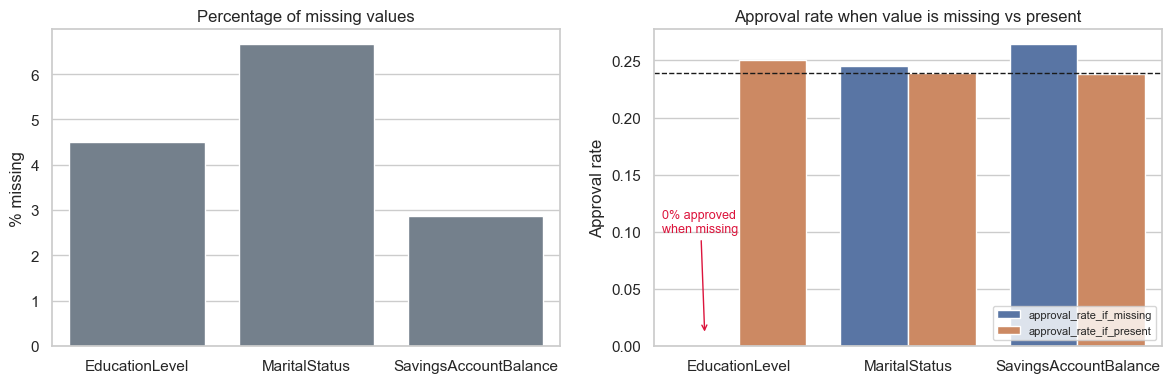

In [80]:
# ------------------------------------------------------------------------------
# Missing-value audit: how many, where, and is the missingness related to the outcome?
# ------------------------------------------------------------------------------
miss = df.isna().sum()
miss = miss[miss > 0].to_frame("n_missing")
miss["pct_missing"] = miss["n_missing"] / len(df) * 100

# approval rate among rows where the value IS vs IS NOT missing
for col in miss.index:
    miss.loc[col, "approval_rate_if_missing"] = df.loc[df[col].isna(), TARGET].mean()
    miss.loc[col, "approval_rate_if_present"] = df.loc[df[col].notna(), TARGET].mean()
display(miss)

# Is the difference statistically significant? (Fisher exact test on a 2x2 table)
for col in miss.index:
    tbl = pd.crosstab(df[col].isna(), df[TARGET])
    odds, pval = stats.fisher_exact(tbl)
    print(f"{col:22s} Fisher exact p-value = {pval:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=miss.index, y=miss["pct_missing"], ax=ax[0], color="slategray")
ax[0].set_title("Percentage of missing values"); ax[0].set_ylabel("% missing"); ax[0].set_xlabel("")
plot_df = miss[["approval_rate_if_missing", "approval_rate_if_present"]].reset_index().melt(id_vars="index")
sns.barplot(data=plot_df, x="index", y="value", hue="variable", ax=ax[1])
ax[1].axhline(df[TARGET].mean(), color="k", ls="--", lw=1); ax[1].set_ylabel("Approval rate"); ax[1].set_xlabel("")
ax[1].set_title("Approval rate when value is missing vs present"); ax[1].legend(fontsize=8, loc="lower right")
ax[1].annotate("0% approved\nwhen missing", xy=(-0.2, 0.01), xytext=(-0.45, 0.10), fontsize=9, color="crimson", arrowprops=dict(arrowstyle="->", color="crimson"))
plt.tight_layout(); plt.show()

## What this code does: Audits missing values and tests whether missingness relates to approval.

**What the code does.** Counts missing values per column, and for each affected column compares the **approval rate when the value is missing vs when it is present**. A Fisher exact test checks whether the difference is statistically real. Two bar charts summarise it.

**Why.** Missing data is only harmless when it is *random*. If missingness itself carries information (e.g. applicants hide something), then filling the gap and forgetting it throws away a signal. This is the "missing value patterns and their potential meaning" requirement.

**Interpretation of the output.**
| Column | Missing | Approval if missing | Approval if present | Fisher p |
|---|---|---|---|---|
| EducationLevel | 901 (4.5%) | **0.0%** | 25.0% | **3e-110** |
| MaritalStatus | 1,331 (6.7%) | 24.5% | 23.9% | 0.60 |
| SavingsAccountBalance | 572 (2.9%) | 26.4% | 23.8% | 0.16 |

Missing **education is not random**: *none* of the 901 applicants was approved. Missing marital status and savings are statistically indistinguishable from random (p > 0.05).

**Decision.**
* `EducationLevel`: impute for the ordinal feature but **add an explicit "was missing" indicator** (Step 5.5). It is possibly a data-collection or process artefact (e.g. incomplete files are rejected), which we flag for the business.
* `MaritalStatus`: missing becomes its own category `"Missing"`.
* `SavingsAccountBalance`: median imputation (plus an indicator, tested in Step 5.7).

#### 4.4 Note potential feature engineering opportunities
| Candidate feature | Idea | Evidence |
|---|---|---|
| `AgeDeviation = |Age - 40|` | Non-linear age effect | Weak marginal signal; **tested in Step 5.7** |
| `LoanToIncome` | Size of loan relative to yearly income | Affordability proxy; tested in Step 5.7 |
| `IncomeMismatchFlag`, `IncomeAtFloor` | Flag corrupted or clipped incomes | Data-quality findings in Step 3.5 |
| `AssetToLiability` | Balance-sheet leverage | Tested in Step 5.7 |
| "Was missing" indicators | Keep informative missingness | Education: 0% approval when missing |
| Log of money variables | Tame skew | **Tested and rejected** in Step 5.1 |

## Part 3: Pipeline Development Phase (Data Preparation)

### 5. Design your preprocessing strategy:

#### Train/test split (done BEFORE any learning step)
The test set is locked away now and is touched **only once**, in Step 8. Every imputer, scaler and encoder is fitted *inside* the pipeline on training folds only, so no information leaks from validation or test data.

In [87]:
# Features = everything except the target and the leaky RiskScore. We keep the CLEANED dataframe (AnnualIncome numeric).
X = df.drop(columns=[TARGET] + LEAKY)
y = df[TARGET].astype(int)

# stratify=y keeps the 23.9% approval rate identical in train and test (important with imbalance)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape}  | Test: {X_test.shape}")
print(f"Approval rate -> full: {y.mean():.4f} | train: {y_train.mean():.4f} | test: {y_test.mean():.4f}")

# One cross-validation splitter used by EVERY experiment so all comparisons are like-for-like
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (16000, 33)  | Test: (4000, 33)
Approval rate -> full: 0.2390 | train: 0.2390 | test: 0.2390


## What this code does: Splits the data 80/20 with stratification and sets up the shared 5-fold cross-validation.

**What the code does.** Builds `X` (all columns except the target and `RiskScore`), splits 80/20 with **stratification**, prints the class balance in each part, and creates one 5-fold stratified cross-validation splitter `CV` used by every experiment.

**Why.** The test set must simulate "future applicants": it is locked away now and touched once at the end. Stratification keeps 23.9% approvals in each part. Using one shared `CV` object makes comparisons like-for-like.

**Interpretation.** Train 16,000 x 33, test 4,000 x 33, approval rate 0.2390 in full data, train and test (identical).

**Decision.** All fitting happens on `X_train`. Imputers, scalers and encoders are fitted *inside* pipelines, so they only ever learn from training folds: no leakage.

#### 5.1 Create separate preprocessing flows for different feature types
| Branch | Columns | Steps | Reason |
|---|---|---|---|
| (custom) feature engineering | raw frame | `LoanFeatureEngineer`: build features, drop `AnnualIncome` | Same logic in train, test and production; stateless so it cannot leak |
| skewed | money and ratio variables | impute (+missing indicator) -> optional log1p -> StandardScaler | handles `SavingsAccountBalance` gaps; log tested |
| numeric | other numerics | impute -> StandardScaler | linear model needs comparable scales |
| binary | `PreviousLoanDefaults`, flags | pass through | already 0/1 |
| nominal | marital, home, employment, purpose | impute `"Missing"` -> OneHotEncoder | no natural order |
| binary_cat | bankruptcy | OneHotEncoder (drop if binary) | one 0/1 column |
| ordinal | education | **FeatureUnion**: ordinal code + missing flag | keeps order *and* the missing signal |

First the custom transformer, then the preprocessor, then a small toolkit plus **Experiment A**, which tests the EDA hypothesis that skewed money variables should be log-transformed.

In [91]:
class LoanFeatureEngineer(BaseEstimator, TransformerMixin):
    """Creates domain features from the raw columns. Stateless (nothing to learn), so it can never leak.

    features            : which engineered columns to create (lets us run ablation studies)
    drop_annual_income  : AnnualIncome is partly corrupted (see EDA); MonthlyIncome x 12 is the clean twin.
    """
    ALL = ("AgeDeviation", "LoanToIncome", "IncomeMismatchFlag", "IncomeAtFloor", "AssetToLiability")

    def __init__(self, features=ALL, drop_annual_income=True):
        self.features = features
        self.drop_annual_income = drop_annual_income

    def fit(self, X, y=None):
        self.columns_out_ = list(self.transform(X.iloc[:2]).columns)   # remember output names (needed by get_feature_names_out)
        return self                                   # nothing else to learn

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns_out_, dtype=object)

    def transform(self, X):
        X = X.copy()
        if "AgeDeviation" in self.features:           # distance from age 40: a NON-LINEAR age effect (value judged by ablation, Step 5.7)
            X["AgeDeviation"] = (X["Age"] - 40).abs()
        if "LoanToIncome" in self.features:           # how large is the loan relative to yearly income?
            X["LoanToIncome"] = X["LoanAmount"] / (12 * X["MonthlyIncome"])
        if "IncomeMismatchFlag" in self.features:     # flags the ~1% rows where AnnualIncome was inflated 1.5-2x
            X["IncomeMismatchFlag"] = (X["AnnualIncome"] / (12 * X["MonthlyIncome"]) > 1.3).astype(int)
        if "IncomeAtFloor" in self.features:          # flags the artificial $15,000 floor
            X["IncomeAtFloor"] = (X["AnnualIncome"] <= 15_000).astype(int)
        if "AssetToLiability" in self.features:       # leverage of the household balance sheet
            X["AssetToLiability"] = X["TotalAssets"] / X["TotalLiabilities"]
        if self.drop_annual_income:
            X = X.drop(columns="AnnualIncome")
        return X

# Quick unit test on 3 rows so we can SEE what the transformer does
demo = LoanFeatureEngineer().fit_transform(X_train.head(3))
display(demo[["Age", "AgeDeviation", "LoanAmount", "MonthlyIncome", "LoanToIncome", "IncomeMismatchFlag", "IncomeAtFloor", "AssetToLiability"]])
print("'AnnualIncome' still present after transform?", "AnnualIncome" in demo.columns)

,Age,AgeDeviation,LoanAmount,MonthlyIncome,LoanToIncome,IncomeMismatchFlag,IncomeAtFloor,AssetToLiability
15234,50,10,16368,"2,866.8333",0.4758,0,0,4.2256
15766,39,1,24926,"4,296.7500",0.4834,0,0,1.4140
16912,23,17,28380,"9,958.0833",0.2375,0,0,11.8117


'AnnualIncome' still present after transform? False


## What this code does: Defines a custom transformer that creates the engineered features inside the pipeline.

**What the code does.** Defines `LoanFeatureEngineer`, a **custom scikit-learn transformer**. It creates five features (`AgeDeviation`, `LoanToIncome`, `IncomeMismatchFlag`, `IncomeAtFloor`, `AssetToLiability`) and drops `AnnualIncome`. A three-row demo prints the result.

**Why.** Putting feature engineering *inside* the pipeline means exactly the same logic runs on training, validation, test and future data. It is stateless (`fit` learns nothing), so it cannot leak. The `features` and `drop_annual_income` parameters let us switch pieces on and off for ablation studies and tuning. `get_feature_names_out` lets us read coefficients by name later.

**Interpretation.** For the first demo row (age 50): `AgeDeviation = 10`; `LoanToIncome = 0.48` (loan is about half a year's income); flags are 0; `AssetToLiability = 4.2`. After the transform `AnnualIncome` is gone.

**Decision.** Keep the transformer, but **each feature must earn its place** in Step 5.7.

In [94]:
# ------------------------------------------------------------------------------
# make_preprocessor(): builds a ColumnTransformer with one branch per feature type
# make_pipeline_()   : FE -> preprocessing -> (optional feature selection) -> model
# They are functions so that we can switch components on/off for ablation studies and tuning.
# ------------------------------------------------------------------------------
ENG_SKEWED  = ["LoanToIncome", "AssetToLiability"]
ENG_NUMERIC = ["AgeDeviation"]
ENG_BINARY  = ["IncomeMismatchFlag", "IncomeAtFloor"]

def make_preprocessor(features=LoanFeatureEngineer.ALL, drop_annual_income=True, num_strategy="median",
                      use_log=True, edu_indicator=True, exclude=()):
    """exclude = raw columns the model must NOT see (used for the fairness/compliance ablation)."""
    keep = lambda cols: [c for c in cols if c not in exclude]

    skewed = [c for c in NUMERIC_SKEWED if not (drop_annual_income and c == "AnnualIncome")] + [c for c in ENG_SKEWED if c in features]
    other  = NUMERIC_OTHER + [c for c in ENG_NUMERIC if c in features]
    binary = BINARY_NUMERIC + [c for c in ENG_BINARY if c in features]
    if "Age" in exclude:                     # engineered age feature must disappear too
        other = [c for c in other if c != "AgeDeviation"]

    # --- Branch 1: skewed money/ratio features -> impute -> log1p -> standardise
    #     add_indicator=True adds a 0/1 column telling the model "this value was imputed" (SavingsAccountBalance)
    skewed_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy=num_strategy, add_indicator=True)),
        ("log",     FunctionTransformer(np.log1p, feature_names_out="one-to-one") if use_log else "passthrough"),
        ("scale",   StandardScaler()),
    ])
    # --- Branch 2: other numeric features -> impute -> standardise
    other_pipe = Pipeline([("imputer", SimpleImputer(strategy=num_strategy)), ("scale", StandardScaler())])
    # --- Branch 3: binary 0/1 columns are already well-behaved -> pass through untouched
    # --- Branch 4: nominal categoricals -> missing becomes its own category 'Missing' -> one-hot
    nominal_pipe = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
                             ("onehot",  OneHotEncoder(handle_unknown="ignore"))])
    # --- Branch 5: binary categorical (Yes/No) -> one column
    binary_cat_pipe = OneHotEncoder(drop="if_binary", handle_unknown="ignore")
    # --- Branch 6: ORDINAL Education -> FeatureUnion of two views of the same column:
    #       (a) ordinal integer 0..4 (missing filled with the mode so the ORDER stays meaningful)
    #       (b) a 'was missing' flag (missing education has a 0% approval rate, so it must be kept as a signal!)
    edu_parts = [("ordinal", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                       ("encode",  OrdinalEncoder(categories=[EDU_ORDER], handle_unknown="use_encoded_value", unknown_value=-1))]))]
    if edu_indicator:
        edu_parts.append(("was_missing", MissingIndicator(features="all")))
    edu_pipe = FeatureUnion(edu_parts)

    transformers = [
        ("skewed",     skewed_pipe,     keep(skewed)),
        ("numeric",    other_pipe,      keep(other)),
        ("binary",     "passthrough",   keep(binary)),
        ("nominal",    nominal_pipe,    keep(NOMINAL)),
        ("binary_cat", binary_cat_pipe, keep(BINARY_CAT)),
        ("ordinal",    edu_pipe,        keep(ORDINAL)),
    ]
    transformers = [t for t in transformers if len(t[2]) > 0]
    return ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=True)

# Global defaults for preprocessing options. 'use_log' starts as True = the hypothesis from EDA (skewed -> log).
# Experiment A below TESTS that hypothesis and updates this dictionary according to the evidence.
PREP_DEFAULTS = {"use_log": True}

def make_pipeline_(model, features=LoanFeatureEngineer.ALL, drop_annual_income=True, **prep_kw):
    prep_kw = {**PREP_DEFAULTS, **prep_kw}
    return Pipeline([
        ("fe",     LoanFeatureEngineer(features=features, drop_annual_income=drop_annual_income)),
        ("pre",    make_preprocessor(features, drop_annual_income, **prep_kw)),
        ("select", "passthrough"),                       # placeholder: tuned later (feature selection)
        ("model",  model),
    ])

# ---- Build, fit on TRAIN only and inspect ------------------------------------
demo_pipe = make_pipeline_(LogisticRegression(max_iter=2000))
demo_pipe  # displays the pipeline diagram

Pipeline(steps=[('fe', LoanFeatureEngineer()),
                ('pre',
                 ColumnTransformer(transformers=[('skewed',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('log',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['MonthlyIncome',
                                                   'LoanAmount',
                                                   'MonthlyDebtPayments',
                                                   'SavingsAccount...
                                                                                  Pipeline(steps=[('imputer',
                                                                                                   SimpleImputer(strategy='most_frequent')),
                                                                                                  ('encode',
                                                                                                   OrdinalEncoder(categories=[['High '
                                                                                                                               'School',
                                                                                                                               'Associate',
                                                                                                                               'Bachelor',
                                                                                                                               'Master',
                                                                                                                               'Doctorate']],
                                                                                                                  handle_unknown='use_encoded_value',
                                                                                                                  unknown_value=-1))])),
                                                                                 ('was_missing',
                                                                                  MissingIndicator(features='all'))]),
                                                  ['EducationLevel'])])),
                ('select', 'passthrough'),
                ('model', LogisticRegression(max_iter=2000))])

## What this code does: Builds the ColumnTransformer (one branch per feature type) and the full pipeline.

**What the code does.** Defines `make_preprocessor()` (a `ColumnTransformer` with six branches) and `make_pipeline_()` (FE -> preprocessing -> optional selection -> model), then shows the pipeline diagram.

| Branch | Columns | Steps | Reason |
|---|---|---|---|
| skewed | money and ratio variables | impute (+missing indicator) -> optional log1p -> StandardScaler | handle `SavingsAccountBalance` gaps; compare raw vs log scale |
| numeric | other numerics | impute -> StandardScaler | the linear model needs comparable scales |
| binary | `PreviousLoanDefaults`, flags | pass through | already 0/1 |
| nominal | marital, home, employment, purpose | impute `"Missing"` -> OneHotEncoder | no natural order |
| binary_cat | bankruptcy | OneHotEncoder(drop if binary) | one 0/1 column |
| ordinal | education | **FeatureUnion**: ordinal code (mode-imputed) + `MissingIndicator` | keeps order *and* the "missing = denied" signal |

**Why.** One flow per feature type is the lab requirement and good practice: scaling a one-hot column or one-hot encoding an ordered variable would waste information. `handle_unknown="ignore"` prevents crashes if a new category appears in production. `PREP_DEFAULTS` is a tiny global switch; it starts with `use_log=True` (my EDA hypothesis), and Experiment A below updates it based on evidence.

**Interpretation.** The diagram shows the nested structure: `fe` -> `pre` (six branches) -> `select` (placeholder) -> `model`. Every piece is a named step, so hyper-parameters can later be addressed as `pre__skewed__log`, `model__C`, etc.

**Decision.** This single object (`Pipeline`) is the unit we cross-validate, tune, evaluate and would deploy.

In [97]:
# ------------------------------------------------------------------------------
# oof_report(): honest, leak-free performance of a pipeline using out-of-fold predictions
# ------------------------------------------------------------------------------
THRESHOLDS = np.round(np.arange(0.20, 0.99, 0.01), 2)

def oof_report(pipe, Xd=None, yd=None, name=""):
    Xd = X_train if Xd is None else Xd
    yd = y_train if yd is None else yd
    oof = cross_val_predict(clone(pipe), Xd, yd, cv=CV, method="predict_proba")[:, 1]
    costs = np.array([cost_at_threshold(yd, oof, t) for t in THRESHOLDS])
    return {"Variant": name,
            "ROC-AUC": roc_auc_score(yd, oof),
            "PR-AUC": average_precision_score(yd, oof),
            "Cost @ break-even ($)": cost_at_threshold(yd, oof, BREAK_EVEN),
            "Best cost ($)": costs.min(),
            "Best threshold": THRESHOLDS[costs.argmin()]}

LR = lambda **kw: LogisticRegression(max_iter=3000, **kw)      # quick Logistic Regression factory for experiments
FMT = {"ROC-AUC": "{:.4f}", "PR-AUC": "{:.4f}", "Cost @ break-even ($)": "{:,.0f}", "Best cost ($)": "{:,.0f}", "Best threshold": "{:.2f}"}

# ---- Experiment A: should the skewed money features be log-transformed? (the EDA hypothesis) ----------
t0 = time.time()
resLog = pd.DataFrame([
    oof_report(make_pipeline_(LR(), use_log=True),  name="log1p ON  (EDA hypothesis)"),
    oof_report(make_pipeline_(LR(), use_log=False), name="log1p OFF (raw scale, standardised only)"),
]).set_index("Variant")
display(resLog.style.format(FMT).background_gradient(subset=["Best cost ($)"], cmap="RdYlGn_r"))

# ---- Let the EVIDENCE set the default for every later experiment ------------------------------------
PREP_DEFAULTS["use_log"] = bool(resLog.iloc[0]["Best cost ($)"] <= resLog.iloc[1]["Best cost ($)"])
print(f"\n=> PREP_DEFAULTS['use_log'] is now {PREP_DEFAULTS['use_log']}   ({time.time()-t0:.0f}s)")

,ROC-AUC,PR-AUC,Cost @ break-even ($),Best cost ($),Best threshold
Variant,,,,,
log1p ON (EDA hypothesis),0.9897,0.9734,639,612,0.82
"log1p OFF (raw scale, standardised only)",0.9961,0.9882,456,450,0.85



=> PREP_DEFAULTS['use_log'] is now False   (5s)


## What this code does: Defines the out-of-fold evaluation helper and tests whether log-transforming skewed features helps.

**What the code does.** Defines `oof_report()`: it produces **out-of-fold predicted probabilities** for the training set with 5-fold CV (every row is predicted by a model that never saw it) and summarises ROC-AUC, PR-AUC, cost at the break-even threshold, and the *best achievable* cost across thresholds 0.20 to 0.98. It then runs **Experiment A**: log-transform on vs off for the skewed money features.

**Why.** Out-of-fold predictions give an honest estimate on training data without touching the test set. Testing the log transform answers a concrete question that EDA could only pose: "skewed distributions *should* be logged; is that true here?"

**Interpretation of the output.**
| Variant | ROC-AUC | Best cost / applicant |
|---|---|---|
| log1p ON | 0.9897 | \$612 |
| **log1p OFF** | **0.9961** | **\$450** |

The "textbook" log transform **hurts**, by about 27% in cost. Logistic regression is linear in its inputs; here the true decision rule is linear in the *raw* dollar amounts (approval depends on income, net worth and debt in raw units), and a log compresses exactly the high-value differences that matter.

**Decision.** The code automatically sets `PREP_DEFAULTS["use_log"] = False`. Lesson: **EDA suggests, experiments decide**. (The tuning stage still re-tests it as a hyper-parameter.)

#### 5.2 Must utilize ColumnTransformer and Pipeline
Both were built in Step 5.1 (`make_preprocessor` returns the `ColumnTransformer`; `make_pipeline_` wraps it in a `Pipeline`). Here we fit them on the training data and inspect what the model actually receives.

In [101]:
# Fit only the FE + preprocessing part on the training data and look at what the model will actually receive
prep_only = demo_pipe[:-2]                         # steps 'fe' and 'pre'
Xt = prep_only.fit_transform(X_train)
feat_names = prep_only.get_feature_names_out()

print("Raw columns going in :", X_train.shape[1])
print("Model-ready columns  :", Xt.shape[1])
print("Any NaN left?        :", bool(np.isnan(Xt).any()))
print("Feature names (first 12 / last 12):")
print(list(feat_names[:12])); print(list(feat_names[-12:]))

# The test set goes through the SAME fitted transformers (no re-fitting!)
Xt_test = prep_only.transform(X_test)
print("\nTransformed test shape:", Xt_test.shape, "| NaN left:", bool(np.isnan(Xt_test).any()))

# Standardised branches should have mean ~0, std ~1 on TRAIN
sk_idx = [i for i, n in enumerate(feat_names) if n.startswith("skewed__") and "missingindicator" not in n][:5]
print("\nScaled 'skewed' columns on train -> mean / std:")
print(pd.DataFrame(Xt[:, sk_idx], columns=feat_names[sk_idx]).agg(["mean", "std"]).round(3))

Raw columns going in : 33
Model-ready columns  : 52
Any NaN left?        : False
Feature names (first 12 / last 12):
['skewed__MonthlyIncome', 'skewed__LoanAmount', 'skewed__MonthlyDebtPayments', 'skewed__SavingsAccountBalance', 'skewed__CheckingAccountBalance', 'skewed__TotalAssets', 'skewed__TotalLiabilities', 'skewed__NetWorth', 'skewed__MonthlyLoanPayment', 'skewed__TotalDebtToIncomeRatio', 'skewed__LoanToIncome', 'skewed__AssetToLiability']
['nominal__HomeOwnershipStatus_Rent', 'nominal__EmploymentStatus_Employed', 'nominal__EmploymentStatus_Self-Employed', 'nominal__EmploymentStatus_Unemployed', 'nominal__LoanPurpose_Auto', 'nominal__LoanPurpose_Debt Consolidation', 'nominal__LoanPurpose_Education', 'nominal__LoanPurpose_Home', 'nominal__LoanPurpose_Other', 'binary_cat__BankruptcyHistory_Yes', 'ordinal__ordinal__EducationLevel', 'ordinal__was_missing__missingindicator_EducationLevel']

Transformed test shape: (4000, 52) | NaN left: False

Scaled 'skewed' columns on train -> mean 

## What this code does: Fits the preprocessing alone and checks the model-ready columns, leftover NaNs and scaling.

**What the code does.** Fits only the FE + preprocessing steps on the training data, shows the resulting number of columns and their names, checks for leftover NaNs, applies the *fitted* transformers to the test set, and verifies that scaled columns have mean 0 and standard deviation 1.

**Why.** A pipeline you have not inspected is a black box. This is the sanity check that preprocessing does what we think.

**Interpretation.** 33 raw columns become **52 model-ready columns**; **no NaN remains** in train or test; scaled columns have mean 0.000 and std 1.000 on the training set (so the scaler was fitted on train only); one-hot names such as `nominal__EmploymentStatus_Unemployed` and the education names (`ordinal__ordinal__EducationLevel` plus the missing flag) look right.

**Decision.** The preprocessing is correct and safe to use in every later experiment.

#### 5.3 Consider using FeatureUnion as well
The education branch is a `FeatureUnion`: one column is turned into two complementary inputs (an ordinal code and a "was missing" flag). The cell below shows it on real rows.

In [105]:
# ------------------------------------------------------------------------------
# FeatureUnion in action: ONE column (EducationLevel) becomes TWO model inputs
#   (a) an ordinal code 0..4   (b) a 0/1 flag 'was this value missing?'
# ------------------------------------------------------------------------------
edu_union = prep_only.named_steps["pre"].named_transformers_["ordinal"]          # the fitted FeatureUnion
rows = pd.concat([X_train[X_train["EducationLevel"].isna()].head(3),
                  X_train.dropna(subset=["EducationLevel"]).groupby("EducationLevel").head(1)])[["EducationLevel"]]
union_out = np.asarray(edu_union.transform(rows))
display(pd.DataFrame(union_out, columns=["ordinal code (0=High School ... 4=Doctorate)", "was_missing flag"],
                     index=rows["EducationLevel"].fillna("(missing)").values))
print("Ordinal order used:", {lvl: k for k, lvl in enumerate(EDU_ORDER)})
print("FeatureUnion output columns:", list(edu_union.get_feature_names_out()))

,ordinal code (0=High School ... 4=Doctorate),was_missing flag
(missing),2.0000,1.0000
(missing),2.0000,1.0000
(missing),2.0000,1.0000
High School,0.0000,0.0000
Associate,1.0000,0.0000
Master,3.0000,0.0000
Bachelor,2.0000,0.0000
Doctorate,4.0000,0.0000


Ordinal order used: {'High School': 0, 'Associate': 1, 'Bachelor': 2, 'Master': 3, 'Doctorate': 4}
FeatureUnion output columns: ['ordinal__EducationLevel', 'was_missing__missingindicator_EducationLevel']


## What this code does: Shows the FeatureUnion turning education into an ordinal code plus a missing flag.

**What the code does.** Takes the fitted education `FeatureUnion` from the pipeline and applies it to a handful of real rows: three applicants with missing education and one example of each education level.

**Why.** A `FeatureUnion` runs several transformers on the *same* input and places their outputs side by side. Seeing it on concrete rows makes the mechanism clear: one column in, two columns out.

**Interpretation of the output.** Each education level maps to its ordinal code (High School 0, Associate 1, Bachelor 2, Master 3, Doctorate 4) with `was_missing = 0`. The rows with missing education receive the most frequent level's code (Bachelor = 2, so the order stays meaningful) **and** `was_missing = 1`. The model can therefore learn two separate things: "how educated?" and "was it blank?".

**Decision.** Keep the `FeatureUnion`. Without the second column, a blank education field would silently look like a Bachelor degree, which is exactly the wrong reading for a group that was never approved.

#### 5.4 Handle missing values appropriately for each feature
| Feature | Strategy |
|---|---|
| `SavingsAccountBalance` (2.9%, random) | imputer + missing indicator; **Experiment B** compares median, mean, KNN and iterative imputation |
| `MaritalStatus` (6.7%, random) | constant `"Missing"` category |
| `EducationLevel` (4.5%, informative) | mode for the ordinal code **plus** an explicit flag (Step 5.5) |

In [109]:
# ---- Experiment B: comparing IMPUTATION strategies for SavingsAccountBalance (572 missing = 2.9%) -----
# Only the 'skewed' branch contains a column with missing values, so we swap the imputer inside it.
t0 = time.time()
imputers = {
    "Median (+indicator)":              SimpleImputer(strategy="median", add_indicator=True),
    "Mean (+indicator)":                SimpleImputer(strategy="mean", add_indicator=True),
    "Median (NO indicator)":            SimpleImputer(strategy="median", add_indicator=False),
    "KNN, k=5 (+indicator)":            KNNImputer(n_neighbors=5, add_indicator=True),
    "Iterative / MICE-style (+indic.)": IterativeImputer(max_iter=10, random_state=RANDOM_STATE, add_indicator=True),
}
rows = []
for name, imp in imputers.items():
    pipe = make_pipeline_(LR()).set_params(pre__skewed__imputer=imp)
    rows.append(oof_report(pipe, name=name))
resC = pd.DataFrame(rows).set_index("Variant")
display(resC.style.format({"ROC-AUC": "{:.5f}", "PR-AUC": "{:.5f}", "Cost @ break-even ($)": "{:,.0f}", "Best cost ($)": "{:,.1f}"}))
print(f"({time.time()-t0:.0f}s)")

# Does the imputed value distribution make sense? Compare real vs imputed Savings balances
sv = X_train["SavingsAccountBalance"]
print("\nSavings balance: median of observed =", f"{sv.median():,.0f}", "| imputed value (median strategy) =", f"{sv.median():,.0f}")
print("Approval rate when Savings missing:", round(y_train[sv.isna()].mean(), 3), "| when present:", round(y_train[sv.notna()].mean(), 3))

,ROC-AUC,PR-AUC,Cost @ break-even ($),Best cost ($),Best threshold
Variant,,,,,
Median (+indicator),0.99608,0.98816,456,450.2,0.850000
Mean (+indicator),0.99608,0.98816,457,450.8,0.850000
Median (NO indicator),0.99608,0.98816,450,446.0,0.840000
"KNN, k=5 (+indicator)",0.99607,0.98814,458,449.6,0.840000
Iterative / MICE-style (+indic.),0.99608,0.98815,457,448.1,0.850000


(15s)

Savings balance: median of observed = 2,986 | imputed value (median strategy) = 2,986
Approval rate when Savings missing: 0.261 | when present: 0.238


## What this code does: Compares five imputation strategies for SavingsAccountBalance.

**What the code does.** **Experiment B**: swaps the imputer that fills `SavingsAccountBalance` (572 gaps) and compares five strategies: median, mean, KNN (k=5), iterative (MICE-style) imputation, and median without the missing-indicator column.

**Why.** The lab asks for multiple imputation strategies with comparative analysis. Sophisticated imputers are slower and more complex, so they must justify themselves.

**Interpretation of the output.** All five strategies give **ROC-AUC 0.99607 to 0.99608** and best cost \$446 to \$451: **identical for practical purposes**. Only 2.9% of rows are affected, savings balance has almost no relationship with approval (effect size 0.012), and the missingness is random (p = 0.16).

**Decision.** Use the **simplest option, median imputation (with indicator)**. It is fast, stable and easy to explain; complexity would add nothing here. Where missingness is informative (education) we model it explicitly; where it is random (savings) a simple imputer suffices. The tuning stage still treats `median` vs `mean` as a parameter.

#### 5.5 Handle Categorical and Ordinal data appropriately
Nominal variables use one-hot encoding (with `handle_unknown="ignore"`), Yes/No bankruptcy uses a single binary column, and education uses an **ordered** encoding. **Experiment C** checks whether the extra "missing" flag for education is worth keeping.

In [113]:
# ---- Experiment C: is the 'education missing' flag worth keeping? --------------------------------------
t0 = time.time()
resB = pd.DataFrame([
    oof_report(make_pipeline_(LR(), edu_indicator=True),  name="Education: ordinal + missing-flag (final design)"),
    oof_report(make_pipeline_(LR(), edu_indicator=False), name="Education: ordinal only (mode imputation, no flag)"),
]).set_index("Variant")
display(resB.style.format(FMT).background_gradient(subset=["Best cost ($)"], cmap="RdYlGn_r"))
print(f"({time.time()-t0:.0f}s)")

,ROC-AUC,PR-AUC,Cost @ break-even ($),Best cost ($),Best threshold
Variant,,,,,
Education: ordinal + missing-flag (final design),0.9961,0.9882,456,450,0.85
"Education: ordinal only (mode imputation, no flag)",0.9957,0.9871,470,461,0.84


(5s)


## What this code does: Tests whether keeping the education "was missing" flag improves the model.

**What the code does.** **Experiment C**: compares the education branch with and without the "was missing" flag.

**Why.** EDA showed missing education is a perfect denial signal; we verify the flag really improves the model rather than assuming.

**Interpretation of the output.** With the flag: AUC 0.9961, best cost **\$450**; without it (mode-imputed only): AUC 0.9957, cost **\$461**. The flag helps (about 2.4% lower cost, or \$11 per applicant). The gain is modest because those applicants are already denied for other reasons (e.g. low income) and mode imputation maps them to "Bachelor", which is a mild positive.

**Decision.** Keep the `FeatureUnion` with the missing-indicator. It is the right modelling of a documented pattern, costs one column, and protects against a hidden failure mode in which missing education would otherwise look like a Bachelor degree.

#### 5.6 Scale numeric values if model requires it (linear model)
Logistic Regression is sensitive to feature scale (regularisation penalises large-scale features more), so every continuous branch ends in a `StandardScaler`, fitted on training folds only. Tree-based models do not need scaling but are unaffected by it, which lets one pipeline serve all nine models. **Experiment A** (Step 5.1) tested an additional log transform for skewed variables; it made the linear model worse, so the final pipeline scales the raw values.

#### 5.7 Document your reasoning for each preprocessing decision
| Decision | Evidence | Outcome |
|---|---|---|
| Do **not** log-transform money variables | Experiment A: AUC 0.9961 (raw) vs 0.9897 (log) | Raw values, standardised |
| Drop `AnnualIncome` | Experiment D: no loss when dropped | Corrupted duplicate removed |
| Add `AgeDeviation` | Experiment D: cost falls about 16% | Kept |
| Income flags, ratio features | Experiment D: no gain | Kept as cheap safeguards; L1 selection prunes them if useless |
| Education missing flag | Experiment C: about 2.4% lower cost | Kept |
| Simple median imputation for savings | Experiment B: all strategies identical | Simplest option |

**Experiment D** below is the feature-engineering ablation that supports the table.

In [118]:
# ---- Experiment D: which engineered features help? (same CV folds; log setting taken from Experiment A) ------
t0 = time.time()
experiments = [
    ("No feature engineering (keep AnnualIncome)", dict(features=(), drop_annual_income=False)),
    ("No FE, drop AnnualIncome",                    dict(features=(), drop_annual_income=True)),
    ("+ AgeDeviation",                              dict(features=("AgeDeviation",))),
    ("+ Income flags (mismatch, floor)",            dict(features=("IncomeMismatchFlag", "IncomeAtFloor"))),
    ("+ LoanToIncome, AssetToLiability",            dict(features=("LoanToIncome", "AssetToLiability"))),
    ("+ ALL engineered features",                   dict(features=LoanFeatureEngineer.ALL)),
]
resA = pd.DataFrame([oof_report(make_pipeline_(LR(), **kw), name=n) for n, kw in experiments]).set_index("Variant")
display(resA.style.format(FMT).background_gradient(subset=["Best cost ($)"], cmap="RdYlGn_r"))
print(f"({time.time()-t0:.0f}s)")

,ROC-AUC,PR-AUC,Cost @ break-even ($),Best cost ($),Best threshold
Variant,,,,,
No feature engineering (keep AnnualIncome),0.9950,0.9849,530,523,0.85
"No FE, drop AnnualIncome",0.9950,0.9849,537,522,0.83
+ AgeDeviation,0.9961,0.9883,458,440,0.81
"+ Income flags (mismatch, floor)",0.9950,0.9849,542,525,0.83
"+ LoanToIncome, AssetToLiability",0.9949,0.9848,529,509,0.84
+ ALL engineered features,0.9961,0.9882,456,450,0.85


(13s)


## What this code does: Tests which engineered features actually improve the model.

**What the code does.** **Experiment D**: starting from the plain pipeline, adds engineered features one group at a time (and also tests keeping vs dropping `AnnualIncome`) using the same CV folds.

**Why.** An ablation study isolates the contribution of each idea. It converts "I think this feature helps" into evidence.

**Interpretation of the output.**
| Variant | ROC-AUC | Best cost |
|---|---|---|
| No FE, keep AnnualIncome | 0.9950 | \$523 |
| No FE, drop AnnualIncome | 0.9950 | \$522 |
| **+ AgeDeviation** | **0.9961** | **\$440** |
| + Income flags | 0.9950 | \$525 |
| + LoanToIncome, AssetToLiability | 0.9949 | \$509 |
| + ALL | 0.9961 | \$450 |

* Dropping `AnnualIncome` costs nothing (it duplicates `MonthlyIncome`), so removing the corrupted column is free.
* **`AgeDeviation` is the only feature with a real effect** (about -\$83 per applicant, about -16%), even though simple correlation did not show it, because the effect appears *after controlling for income and experience*.
* The two income flags do not help the model: the 195 inflated rows are only 1% of the data and, once `AnnualIncome` is dropped, the clean `MonthlyIncome` already carries the correct value.
* The ratio features add nothing (and slightly hurt).

**Decision.** Keep `AgeDeviation` (clearly useful). I keep the full feature set as the default because the L1 feature-selection stage in the tuning will prune useless columns automatically, and the flags are cheap data-quality safeguards for production; the cost difference between "+AgeDeviation" and "+ALL" (\$440 vs \$450) is within noise. Note that `AgeDeviation` uses *age*, a sensitive attribute: we audit it in Step 8.2.

## Part 4: Iterative Modeling Phase

### 6. Implement your modeling approach:

#### 6.1 Choose appropriate model algorithms based on your problem definition
First the **problem definition** is tested: classification versus regression. `RiskScore` cannot be a *feature* (leakage), but it can be a regression *target* to emulate the "risk score for loan officers" approach. We predict it, convert the predicted score into a decision, and compare.

Then nine classification candidates are compared in Step 6.4:

| Algorithm | Why it is included |
|---|---|
| Dummy (prior) | The "know-nothing" baseline every model must beat |
| **Logistic Regression** | Interpretable, regulator-friendly; EDA suggested a near-linear boundary |
| KNN | Distance-based; tests local structure |
| Decision Tree (unpruned / depth 5) | Interpretable non-linear; shows over- vs under-fitting |
| Random Forest | Bagging ensemble to reduce tree variance |
| Gradient Boosting, Hist Gradient Boosting | Boosting ensembles, typically strong on tabular data |
| Voting ensemble (LR + HGB + RF) | Tests whether combining model families helps |

  File "C:\Users\USER\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\USER\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\USER\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\USER\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


,R2 (RiskScore),MAE (points),ROC-AUC (as classifier),PR-AUC,Best cost / applicant ($)
Approach,,,,,
REGRESSION: Ridge regression,0.786971,2.815460,0.888979,0.772617,"1,544"
REGRESSION: Hist Gradient Boosting Regressor,0.908123,1.503065,0.928796,0.849524,"1,384"
CLASSIFICATION: Logistic Regression,nan,nan,0.996083,0.988160,450


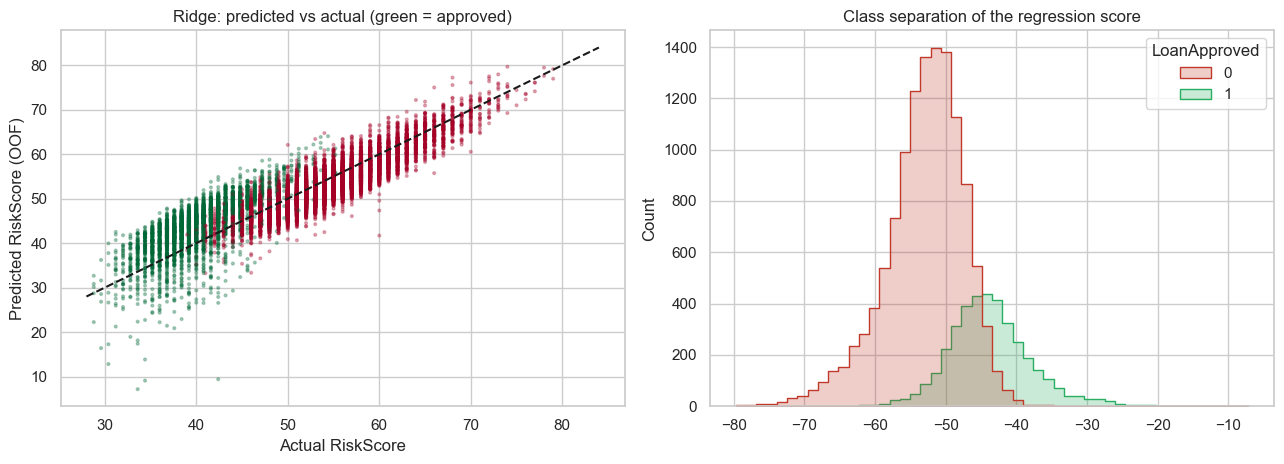

In [124]:
# ------------------------------------------------------------------------------
# Regression path: predict RiskScore from the same features, then approve if predicted score is LOW
# ------------------------------------------------------------------------------
CV_REG = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # plain KFold: a continuous target cannot be stratified
risk_train = df.loc[X_train.index, "RiskScore"]; risk_test = df.loc[X_test.index, "RiskScore"]   # (target only)

def reg_pipeline(reg):
    p = make_pipeline_(LR())                       # reuse the identical FE + preprocessing
    return p.set_params(model=reg)

reg_rows = []
for name, reg in {"Ridge regression": Ridge(alpha=1.0), "Hist Gradient Boosting Regressor": HistGradientBoostingRegressor(random_state=RANDOM_STATE)}.items():
    pred = cross_val_predict(reg_pipeline(reg), X_train, risk_train, cv=CV_REG)
    # convert to a decision: approve if predicted risk < cutoff; choose the cutoff that minimises $ cost (OOF)
    cutoffs = np.quantile(pred, np.linspace(0.05, 0.60, 111))
    costs = [business_cost(y_train, (pred < c).astype(int)) for c in cutoffs]
    reg_rows.append({"Approach": f"REGRESSION: {name}", "R2 (RiskScore)": r2_score(risk_train, pred), "MAE (points)": mean_absolute_error(risk_train, pred),
                     "ROC-AUC (as classifier)": roc_auc_score(y_train, -pred), "PR-AUC": average_precision_score(y_train, -pred),
                     "Best cost / applicant ($)": min(costs)})

oof_lr = cross_val_predict(make_pipeline_(LR()), X_train, y_train, cv=CV, method="predict_proba")[:, 1]
c_lr = min(cost_at_threshold(y_train, oof_lr, t) for t in THRESHOLDS)
reg_rows.append({"Approach": "CLASSIFICATION: Logistic Regression", "R2 (RiskScore)": np.nan, "MAE (points)": np.nan,
                 "ROC-AUC (as classifier)": roc_auc_score(y_train, oof_lr), "PR-AUC": average_precision_score(y_train, oof_lr),
                 "Best cost / applicant ($)": c_lr})
reg_cmp = pd.DataFrame(reg_rows).set_index("Approach"); display(reg_cmp.style.format("{:.4f}", na_rep="-").format({"Best cost / applicant ($)": "{:,.0f}"}))

# Visual: predicted vs actual RiskScore (regression sanity check)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
pred_ridge = cross_val_predict(reg_pipeline(Ridge(alpha=1.0)), X_train, risk_train, cv=CV_REG)
ax[0].scatter(risk_train, pred_ridge, s=4, alpha=.3, c=y_train, cmap="RdYlGn"); ax[0].plot([28, 84], [28, 84], "k--")
ax[0].set_xlabel("Actual RiskScore"); ax[0].set_ylabel("Predicted RiskScore (OOF)"); ax[0].set_title("Ridge: predicted vs actual (green = approved)")
sns.histplot(x=-pred_ridge, hue=y_train, bins=50, ax=ax[1], palette=["#c0392b", "#27ae60"], element="step"); ax[1].set_title("Class separation of the regression score")
plt.tight_layout(); plt.show()

## What this code does: Tests the regression alternative: predicts RiskScore and converts it into approve/deny decisions.

**What the code does.** Tests the regression alternative. Uses the same preprocessing to predict `RiskScore` (Ridge and Hist Gradient Boosting Regressor, with plain 5-fold CV because a continuous target cannot be stratified), converts the predicted score into a decision (approve if predicted risk is below a cut-off chosen to minimise cost), and compares with classification. Scatter and histogram plots show predicted vs actual.

**Why.** The brief explicitly allows either approach; I should justify, not assume. `RiskScore` can serve as a *target* (never a feature) here.

**Interpretation of the output.**
| Approach | R2 | MAE | AUC as classifier | Best cost / applicant |
|---|---|---|---|---|
| Ridge regression | 0.79 | 2.8 pts | 0.889 | \$1,544 |
| HGB regressor | 0.91 | 1.5 pts | 0.929 | \$1,384 |
| **Logistic Regression (classification)** | n/a | n/a | **0.996** | **\$450** |

The regressors predict the score reasonably (R2 up to 0.91), but this is the wrong target: the score is a *blend* of many factors, and small errors in it matter enormously near the cut-off. The result is far worse decisions (cost about 3x higher). The scatter shows overlapping classes along the diagonal.

**Decision.** **Classification wins**: more accurate, much cheaper and directly optimisable for the \$8k/\$50k trade-off. A probability from the classifier can still be shown to officers as a risk score (1 - P(approve)).

#### 6.2 Set up validation strategy with chosen metrics
* **5-fold stratified cross-validation** on the training set for every comparison and every search.
* **Metrics** (Step 2): ROC-AUC, PR-AUC, F1, recall, and the custom dollar-cost scorer (`SCORING`).
* **Baseline**: `DummyClassifier(strategy="prior")`.
* Training scores are also recorded (`return_train_score=True`) so the **train-validation gap** exposes overfitting.

#### 6.3 Use a train test split and cross validation
The stratified 80/20 split (16,000 / 4,000 rows) was made in Step 5 and the same 5-fold `CV` object is reused everywhere, so every model sees identical folds. The test set stays untouched until Step 8.

#### 6.4 Create complete pipeline including any preprocessing and model
Every candidate is wrapped by `make_pipeline_()`, i.e. *feature engineering -> ColumnTransformer -> (selection) -> model*, so preprocessing is re-fitted inside every fold.

In [130]:
# ------------------------------------------------------------------------------
# Compare 9 model configurations with identical preprocessing and identical folds
# ------------------------------------------------------------------------------
models = {
    "Dummy (baseline)":            DummyClassifier(strategy="prior"),
    "Logistic Regression":         LR(),
    "KNN (k=25)":                  KNeighborsClassifier(n_neighbors=25),
    "Decision Tree (unpruned)":    DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Decision Tree (depth 5)":     DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest":               RandomForestClassifier(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting":           GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Hist Gradient Boosting":      HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "Voting Ensemble (LR+HGB+RF)": VotingClassifier([("lr", LR()),
                                                     ("hgb", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
                                                     ("rf", RandomForestClassifier(n_estimators=100, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE))],
                                                    voting="soft", weights=[2, 1, 1]),
}
cv_results, t_all = {}, time.time()
for name, mdl in models.items():
    t0 = time.time()
    res = cross_validate(make_pipeline_(mdl), X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True, n_jobs=1)
    cv_results[name] = res
    print(f"{name:30s} done in {time.time()-t0:5.1f}s")
print(f"Total: {time.time()-t_all:.0f}s")

summary = pd.DataFrame({
    name: {
        "ROC-AUC (val)":     r["test_roc_auc"].mean(),     "ROC-AUC std": r["test_roc_auc"].std(),
        "ROC-AUC (train)":   r["train_roc_auc"].mean(),
        "PR-AUC (val)":      r["test_pr_auc"].mean(),
        "F1 @0.5 (val)":     r["test_f1"].mean(),
        "Recall @0.5 (val)": r["test_recall"].mean(),
        "Cost/applicant @break-even ($)": -r["test_neg_cost"].mean(),
        "Train-Val AUC gap": r["train_roc_auc"].mean() - r["test_roc_auc"].mean(),
        "Fit time / fold (s)": r["fit_time"].mean(),
    } for name, r in cv_results.items()}).T.sort_values("Cost/applicant @break-even ($)")
display(summary.style.format("{:.4f}").format({"Cost/applicant @break-even ($)": "{:,.0f}", "Fit time / fold (s)": "{:.2f}"})
        .background_gradient(subset=["Cost/applicant @break-even ($)"], cmap="RdYlGn_r")
        .background_gradient(subset=["ROC-AUC (val)"], cmap="RdYlGn"))

Dummy (baseline)               done in   2.4s
Logistic Regression            done in   4.3s
KNN (k=25)                     done in  16.8s
Decision Tree (unpruned)       done in   7.8s
Decision Tree (depth 5)        done in   4.3s
Random Forest                  done in  23.4s
Gradient Boosting              done in  85.8s
Hist Gradient Boosting         done in  19.2s
Voting Ensemble (LR+HGB+RF)    done in  28.3s
Total: 192s


,ROC-AUC (val),ROC-AUC std,ROC-AUC (train),PR-AUC (val),F1 @0.5 (val),Recall @0.5 (val),Cost/applicant @break-even ($),Train-Val AUC gap,Fit time / fold (s)
Logistic Regression,0.996092,0.000461,0.996431,0.988183,0.935339,0.930698,456,0.000339,0.36
Voting Ensemble (LR+HGB+RF),0.994932,0.001041,0.999263,0.984871,0.926469,0.914743,695,0.004330,4.65
Hist Gradient Boosting,0.990570,0.002066,0.999458,0.972156,0.901375,0.890424,712,0.008888,2.67
Gradient Boosting,0.986188,0.002776,0.992791,0.961313,0.881770,0.859565,899,0.006603,16.62
Random Forest,0.976626,0.003864,0.999805,0.934413,0.840076,0.805432,"1,314",0.023178,3.77
Decision Tree (depth 5),0.942630,0.008212,0.954166,0.832820,0.784634,0.760717,"1,612",0.011536,0.54
KNN (k=25),0.952771,0.003023,0.965955,0.866491,0.686705,0.544711,"1,719",0.013183,0.23
Dummy (baseline),0.500000,0.000000,0.500000,0.239000,0.000000,0.000000,"1,912",0.000000,0.18
Decision Tree (unpruned),0.843052,0.006378,1.000000,0.638131,0.761935,0.759937,"3,268",0.156948,1.16


Decision Tree (depth 5)        done in   2.9s


Random Forest                  done in  40.8s


Gradient Boosting              done in  50.9s


Hist Gradient Boosting         done in   9.3s


Voting Ensemble (LR+HGB+RF)    done in  27.4s
Total: 157s


,ROC-AUC (val),ROC-AUC std,ROC-AUC (train),PR-AUC (val),F1 @0.5 (val),Recall @0.5 (val),Cost/applicant @break-even ($),Train-Val AUC gap,Fit time / fold (s)
Logistic Regression,0.996092,0.000461,0.996431,0.988183,0.935339,0.930698,456,0.000339,0.17
Voting Ensemble (LR+HGB+RF),0.994932,0.001041,0.999263,0.984871,0.926469,0.914743,695,0.004330,4.78
Hist Gradient Boosting,0.990570,0.002066,0.999458,0.972156,0.901375,0.890424,712,0.008888,1.26
Gradient Boosting,0.986188,0.002776,0.992791,0.961313,0.881770,0.859565,899,0.006603,9.83
Random Forest,0.976626,0.003864,0.999805,0.934413,0.840076,0.805432,"1,314",0.023178,7.28
Decision Tree (depth 5),0.942630,0.008212,0.954166,0.832820,0.784634,0.760717,"1,612",0.011536,0.33
KNN (k=25),0.952771,0.003023,0.965955,0.866491,0.686705,0.544711,"1,719",0.013183,0.09
Dummy (baseline),0.500000,0.000000,0.500000,0.239000,0.000000,0.000000,"1,912",0.000000,0.08
Decision Tree (unpruned),0.843052,0.006378,1.000000,0.638131,0.761935,0.759937,"3,268",0.156948,0.46


## What this code does: Cross-validates nine models with identical preprocessing and compares them.

**What the code does.** Cross-validates nine configurations with *identical* preprocessing and folds: a Dummy baseline, Logistic Regression, KNN, two Decision Trees (unpruned and depth 5), Random Forest, Gradient Boosting, Hist Gradient Boosting, and a soft-voting ensemble (LR + HGB + RF). For each it records validation and training scores, the train-validation gap (overfitting), and fit time.

**Why.** The rubric asks for several algorithms with a justified comparison. Models differ in assumptions (linear vs trees vs distance-based vs ensembles), interpretability and cost.

**Interpretation of the output** (sorted by dollar cost):
| Model | Val AUC | Cost @0.862 | Train-Val gap | Comment |
|---|---|---|---|---|
| **Logistic Regression** | **0.9961** | **\$456** | 0.0003 | best, no overfitting, 0.16 s/fold |
| Voting ensemble | 0.9949 | \$695 | 0.004 | slower, no gain |
| Hist Gradient Boosting | 0.9906 | \$712 | 0.009 | some overfitting |
| Gradient Boosting | 0.9862 | \$899 | 0.007 | slowest |
| Random Forest | 0.9766 | \$1,314 | 0.023 | overfits |
| Decision Tree depth 5 | 0.9426 | \$1,612 | 0.012 | too simple |
| KNN | 0.9528 | \$1,719 | 0.013 | suffers in 52 dimensions |
| Dummy | 0.5000 | \$1,912 | 0 | baseline |
| Decision Tree unpruned | 0.8431 | \$3,268 | **0.157** | memorises training data |

The data is dominated by **roughly linear effects of income, debt and loan size**, which a linear model captures with almost no variance. Tree ensembles must approximate smooth straight-line boundaries with piecewise steps, so they need far more data to match it. The unpruned tree shows textbook overfitting (training AUC 1.00 vs validation 0.84). Only Logistic Regression, the voting ensemble, Hist Gradient Boosting and Gradient Boosting beat the \$956 "half of deny-all" target (\$456, \$695, \$712, \$899); LR is the only one under the \$478 stretch target.

**Decision.** Logistic Regression is the front-runner; it is also the most **interpretable**, which regulators require. Hist Gradient Boosting is retained as the tuned non-linear challenger in Stage 1b.

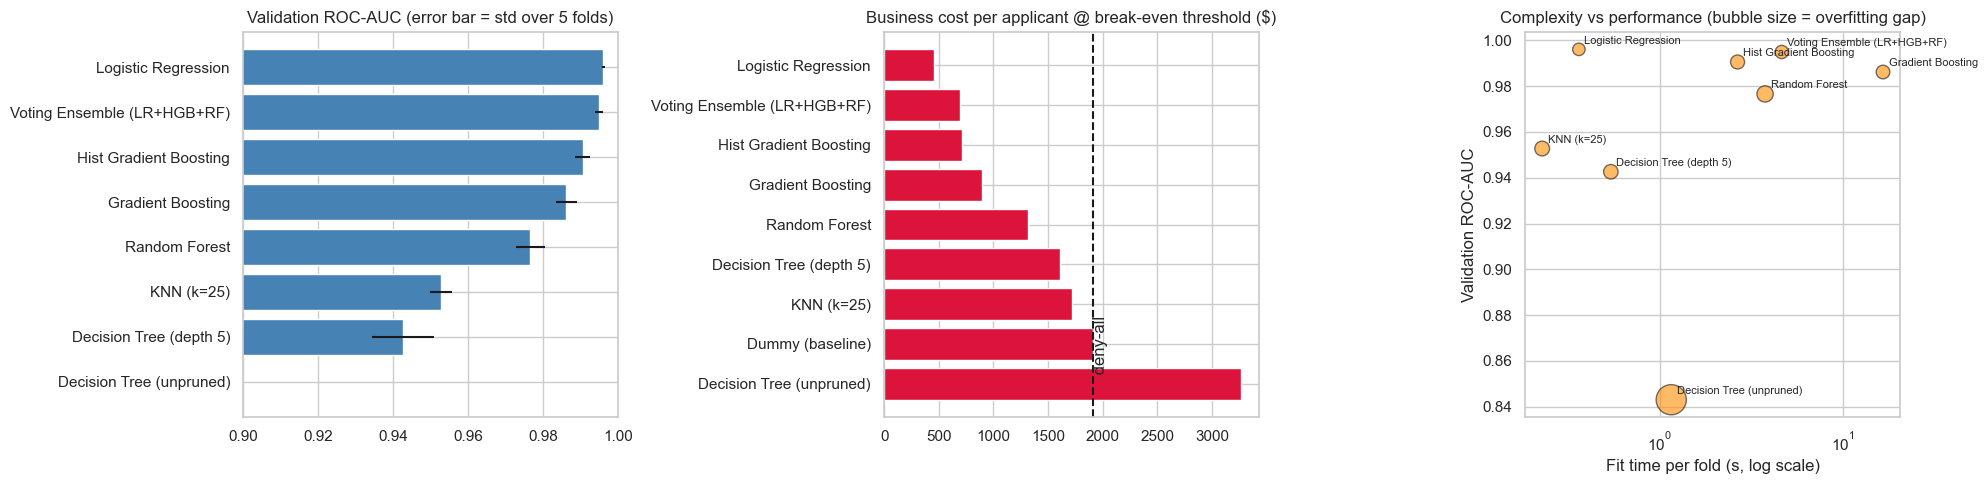

In [133]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
s = summary.drop(index="Dummy (baseline)")
order = s.sort_values("ROC-AUC (val)").index
ax[0].barh(order, s.loc[order, "ROC-AUC (val)"], xerr=s.loc[order, "ROC-AUC std"], color="steelblue")
ax[0].set_xlim(0.9, 1.0); ax[0].set_title("Validation ROC-AUC (error bar = std over 5 folds)")

order = summary.sort_values("Cost/applicant @break-even ($)", ascending=False).index
ax[1].barh(order, summary.loc[order, "Cost/applicant @break-even ($)"], color="crimson")
ax[1].set_title("Business cost per applicant @ break-even threshold ($)"); ax[1].axvline(prev * FN_COST, color="k", ls="--"); ax[1].text(prev*FN_COST, 0.2, " deny-all", rotation=90)

ax[2].scatter(s["Fit time / fold (s)"], s["ROC-AUC (val)"], s=80 + 2500 * s["Train-Val AUC gap"], alpha=.6, color="darkorange", edgecolor="k")
for n, r in s.iterrows(): ax[2].annotate(n, (r["Fit time / fold (s)"], r["ROC-AUC (val)"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax[2].set_xscale("log"); ax[2].set_xlabel("Fit time per fold (s, log scale)"); ax[2].set_ylabel("Validation ROC-AUC")
ax[2].set_title("Complexity vs performance (bubble size = overfitting gap)")
plt.tight_layout(); plt.show()

## What this code does: Charts accuracy, cost, and complexity versus performance for the nine models.

**What the code does.** Three charts: validation AUC with fold-to-fold standard deviation, cost per applicant (with the deny-all line), and a complexity-vs-performance bubble chart (x = fit time on log scale, y = AUC, bubble size = overfitting gap).

**Why.** Visual comparison makes the *trade-off* between complexity and performance obvious, which is a rubric item.

**Interpretation.** Logistic Regression is top-left in the bubble chart: highest AUC, fastest fit and a tiny bubble (no overfitting). Moving right (more expensive models) does not move up. Random Forest, the shallow tree and KNN barely beat the \$1,912 deny-all line, and the unpruned tree is **worse than lending to nobody** (\$3,268). The fold-to-fold standard deviation is small for LR (0.0005), so its lead is not luck.

**Decision.** More complexity bought nothing here, so we tune **LR as the primary model** and a boosted model as challenger.

#### 6.5 Document your reasoning for each modeling decision
| Decision | Reasoning / evidence |
|---|---|
| Classification, not regression | Step 6.1: regression on `RiskScore` costs about 3x more per applicant |
| Logistic Regression as front-runner | Best CV AUC and cost, no overfitting (train-val gap 0.0003), fastest, interpretable |
| Tree ensembles are challengers, not defaults | They must approximate a smooth, near-linear boundary with steps and need more data |
| Unpruned tree rejected | Train AUC 1.00 vs validation 0.84: textbook overfitting |
| Voting ensemble rejected | Slower, less interpretable, no gain over LR |
| Hist Gradient Boosting retained as the tuned challenger | Strongest non-linear family; gets a fair tuning budget in Step 7.5 |

### 7. Optimize your model:

#### 7.1 Define parameter grid based on your understanding of the algorithms
> **NOTE: Be mindful of time considerations: showcase "how to tune".** The searches below are deliberately small (about 5 minutes in total on one CPU core).

| Stage | Tool | Purpose |
|---|---|---|
| 1 | `RandomizedSearchCV` on the **Logistic Regression** pipeline (model *and* preprocessing parameters) | cheap, wide exploration |
| 2 | `GridSearchCV` in a narrow window around the Stage-1 winner | fine-tuning, with the one-standard-error rule |
| 1b | `RandomizedSearchCV` on **Hist Gradient Boosting** | fair challenge from the best non-linear model |
| 3 | Threshold search on out-of-fold predictions | convert probabilities to dollar-optimal decisions |

Search space for Logistic Regression: `C` (log scale 0.01 to 100), penalty (L1 / L2), class weighting, log transform on/off, imputation strategy, and three feature-selection options. Reasoning: `C` controls the bias-variance trade-off; L1 can zero out useless features; class weights test the imbalance remedy; the remaining items tune the **preprocessing** itself.

#### 7.2 Implement GridSearchCV and/or RandomizedSearchCV with chosen metrics
Both are used, with **5 folds** and all five metrics tracked (`scoring=SCORING`), refitting on ROC-AUC.

In [140]:
# ------------------------------------------------------------------------------
# STAGE 1: RandomizedSearchCV over model + preprocessing + feature-selection parameters
# ------------------------------------------------------------------------------
lr_pipe = make_pipeline_(LogisticRegression(solver="liblinear", max_iter=3000))   # liblinear supports both L1 and L2

lr_space = {
    "model__C":            loguniform(1e-2, 1e2),                 # inverse regularisation strength (log scale!)
    "model__penalty":      ["l1", "l2"],                          # L1 can zero-out useless features
    "model__class_weight": [None, "balanced"],                    # does re-weighting the minority class help?
    "pre__skewed__log":    [FunctionTransformer(np.log1p, feature_names_out="one-to-one"), "passthrough"],      # tune a PREPROCESSING step
    "pre__skewed__imputer__strategy": ["median", "mean"],
    "select":              ["passthrough",                         # tune FEATURE SELECTION inside the pipeline
                            SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", C=0.05)),
                            SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", C=0.5))],
}
t0 = time.time()
rs_lr = RandomizedSearchCV(lr_pipe, lr_space, n_iter=40, cv=CV, scoring=SCORING, refit="roc_auc",
                           random_state=RANDOM_STATE, n_jobs=1, return_train_score=True)
rs_lr.fit(X_train, y_train)
print(f"Stage 1 (LR) finished in {time.time()-t0:.0f}s  |  40 candidates x 5 folds = 200 fits")
print("Best CV ROC-AUC:", round(rs_lr.best_score_, 5))
print("Best params:")
for k, v in rs_lr.best_params_.items():
    print("   ", k, "=", (type(v).__name__ + (f"(L1, C={v.estimator.C})" if hasattr(v, "estimator") else "")) if hasattr(v, "get_params") else v)

def tidy(cv_res):
    r = pd.DataFrame(cv_res)
    out = pd.DataFrame({
        "C": r["param_model__C"].astype(float) if "param_model__C" in r else np.nan,
        "penalty": r.get("param_model__penalty"), "class_weight": r.get("param_model__class_weight").apply(lambda v: "balanced" if v == "balanced" else "None"),
        "log1p": r.get("param_pre__skewed__log").apply(lambda v: "off" if isinstance(v, str) else "on"),
        "selection": r.get("param_select").apply(lambda v: "none" if isinstance(v, str) else f"L1 C={v.estimator.C}"),
        "AUC": r["mean_test_roc_auc"], "AUC_train": r["mean_train_roc_auc"], "PR_AUC": r["mean_test_pr_auc"],
        "F1": r["mean_test_f1"], "Cost($)": -r["mean_test_neg_cost"], "rank_AUC": r["rank_test_roc_auc"]})
    return out
res1 = tidy(rs_lr.cv_results_).sort_values("rank_AUC")
display(res1.head(10).style.format({"C": "{:.3f}", "AUC": "{:.5f}", "AUC_train": "{:.5f}", "PR_AUC": "{:.5f}", "F1": "{:.4f}", "Cost($)": "{:,.0f}"}))

Stage 1 (LR) finished in 420s  |  40 candidates x 5 folds = 200 fits
Best CV ROC-AUC: 0.99625
Best params:
    model__C = 75.56810141274431
    model__class_weight = balanced
    model__penalty = l2
    pre__skewed__imputer__strategy = mean
    pre__skewed__log = passthrough
    select = SelectFromModel(L1, C=0.05)


,C,penalty,class_weight,log1p,selection,AUC,AUC_train,PR_AUC,F1,Cost($),rank_AUC
14,75.568,l2,balanced,off,L1 C=0.05,0.99625,0.99647,0.98862,0.9299,639,1
15,50.890,l2,None,off,L1 C=0.05,0.99625,0.99647,0.98862,0.9359,461,2
12,43.379,l2,balanced,off,L1 C=0.05,0.99625,0.99647,0.98862,0.9297,633,3
31,3.144,l1,balanced,off,L1 C=0.05,0.99625,0.99647,0.98861,0.9298,623,4
26,0.944,l1,None,off,L1 C=0.05,0.99624,0.99646,0.98858,0.9362,444,5
37,0.412,l1,balanced,off,L1 C=0.05,0.99623,0.99645,0.98857,0.9284,574,6
0,0.315,l1,None,off,none,0.99622,0.99648,0.98853,0.9367,466,7
29,2.616,l1,None,off,none,0.99621,0.99655,0.98851,0.9361,458,8
22,25.128,l2,balanced,off,L1 C=0.5,0.99620,0.99653,0.98846,0.9292,646,9
32,34.129,l2,balanced,off,none,0.99619,0.99653,0.98843,0.9280,641,10


## What this code does: Runs a randomized search over model and preprocessing settings for Logistic Regression.

**What the code does.** **Stage 1** of tuning: a `RandomizedSearchCV` with 40 random candidates x 5 folds = 200 fits on the whole pipeline. It searches *model* parameters (`C` on a log scale, L1/L2 penalty, class weighting) **and preprocessing parameters** (log transform on/off, mean vs median imputation, three feature-selection options: none, L1 C=0.05, L1 C=0.5). All five metrics are tracked; the best model is chosen by ROC-AUC. A `tidy()` helper makes the results readable.

**Why.** A random search covers a wide space cheaply (grid search would need 2 x 2 x 2 x 2 x 3 x many C values). Tuning preprocessing together with the model matches how the pipeline really behaves.

**Interpretation of the output.** Best CV AUC **0.99625**. Top ten candidates are almost identical in AUC (0.9962 to 0.9963), which says the score is already on a **plateau**. Clear patterns in the table: every top candidate has `log1p = off` (confirming Experiment A) and most use the L1 feature selector; large `C` (weak regularisation) is not needed. `class_weight="balanced"` has the same AUC as `None` but a **much higher dollar cost at 0.862** (about \$640 vs about \$460): re-weighting the minority class inflates probabilities, so the 0.862 break-even no longer applies.

**Decision.** Fix `log1p = off`, keep the L1 selector, treat `class_weight=None` as preferable for cost-based decisions, and refine `C` in Stage 2.

In [ ]:
# ------------------------------------------------------------------------------
# STAGE 2: GridSearchCV in a narrow window around the Stage-1 winner (grid is BUILT from stage-1 results)
# Refit rule: the ONE-STANDARD-ERROR rule. Among candidates whose CV-AUC is within 1 standard error of the best,
# pick the SIMPLEST (smallest C = strongest regularisation, no class re-weighting). Same accuracy, lower overfitting risk.
# ------------------------------------------------------------------------------
best1 = rs_lr.best_params_
C0 = best1["model__C"]
grid = {
    "model__C":            sorted(set(np.round(C0 * np.array([0.1, 0.25, 0.5, 1, 2, 4]), 3)) | {0.3, 1.0, 3.0, 10.0}),
    "model__penalty":      [best1["model__penalty"]],
    "model__class_weight": [None, "balanced"],
    "pre__skewed__log":    [best1["pre__skewed__log"]],
    "pre__skewed__imputer__strategy": [best1["pre__skewed__imputer__strategy"]],
    "select":              [best1["select"]],
}

def one_se_refit(cv_results):
    auc = np.asarray(cv_results["mean_test_roc_auc"]); se = np.asarray(cv_results["std_test_roc_auc"]) / np.sqrt(CV.get_n_splits())
    best = auc.argmax(); ok = np.where(auc >= auc[best] - se[best])[0]            # statistically-tied candidates
    Cs = np.array([cv_results["params"][i]["model__C"] for i in ok])
    reweighted = np.array([cv_results["params"][i]["model__class_weight"] is not None for i in ok])
    return int(ok[np.lexsort((reweighted, Cs))[0]])                              # smallest C first, then prefer no re-weighting

t0 = time.time()
gs_lr = GridSearchCV(lr_pipe, grid, cv=CV, scoring=SCORING, refit=one_se_refit, n_jobs=1, return_train_score=True)
gs_lr.fit(X_train, y_train)
print(f"Stage 2 (LR grid) finished in {time.time()-t0:.0f}s  | {len(gs_lr.cv_results_['params'])} candidates x 5 folds")

res2 = tidy(gs_lr.cv_results_)
res2["chosen"] = res2.index == gs_lr.best_index_
best_auc_row = res2.loc[res2["AUC"].idxmax()]; chosen_row = res2.loc[gs_lr.best_index_]
print(f"Highest-AUC candidate : C = {best_auc_row.C:.3f}, class_weight = {best_auc_row.class_weight}, AUC = {best_auc_row.AUC:.5f}")
print(f"1-SE (chosen) model   : C = {chosen_row.C:.3f}, class_weight = {chosen_row.class_weight}, AUC = {chosen_row.AUC:.5f}")
display(res2.sort_values("C").style.format({"C": "{:.3f}", "AUC": "{:.5f}", "AUC_train": "{:.5f}", "PR_AUC": "{:.5f}", "F1": "{:.4f}", "Cost($)": "{:,.0f}"})
        .apply(lambda r: ["background-color: #d5f5e3" if r["chosen"] else "" for _ in r], axis=1))

# ---- Visual: the AUC plateau that motivates the 1-SE rule -----------------------------------------------
plt.figure(figsize=(8, 4.2))
for cw, g in res2.groupby("class_weight"): plt.plot(g.sort_values("C")["C"], g.sort_values("C")["AUC"], marker="o", label=f"class_weight={cw}")
plt.scatter([chosen_row.C], [chosen_row.AUC], s=250, facecolors="none", edgecolors="k", linewidths=2, label="chosen (1-SE rule)")
plt.xscale("log"); plt.xlabel("C (inverse regularisation strength)"); plt.ylabel("CV ROC-AUC"); plt.title("Stage 2: performance plateaus once C is large enough"); plt.legend(); plt.tight_layout(); plt.show()

# Overfitting check: train vs validation AUC for the chosen configuration
print(f"\nChosen model: train AUC = {chosen_row.AUC_train:.5f} vs validation AUC = {chosen_row.AUC:.5f}  (gap = {chosen_row.AUC_train - chosen_row.AUC:.5f})")

## What this code does: Runs a grid search around the Stage 1 winner and picks the simplest model tied for best.

**What the code does.** **Stage 2**: a `GridSearchCV` in a narrow window around the Stage-1 winner (grid built automatically from stage-1 results, plus C = 0.3, 1, 3, 10), 20 candidates x 5 folds. Instead of simply taking the highest AUC, it uses the **one-standard-error rule**: among candidates statistically tied with the best, choose the simplest (smallest C, no class re-weighting). A plot shows the plateau, and train vs validation AUC is compared.

**Why.** "Justification of final parameter choices with respect to overfitting risks": the best AUC is C = 302 (essentially *no* regularisation), but C = 1 is statistically indistinguishable and much more stable. A lower `C` shrinks coefficients, which protects against collinearity (VIF up to infinity) and gives more trustworthy coefficients for explanation.

**Interpretation of the output.**
* Highest-AUC candidate: C = 302, AUC 0.99626. **Chosen: C = 1.0, AUC 0.99613**; the difference is 0.00013, smaller than one standard error.
* AUC rises from 0.99582 at C = 0.3 to 0.99622 at C = 3 and then does not move.
* **Train AUC 0.99638 vs validation 0.99613, a gap of only 0.00026**: no overfitting.
* At the 0.862 threshold the chosen model's cost is \$464 per applicant.

**Decision.** Final LR configuration: **L2, C = 1, no class weights, no log transform, L1 feature selection (C = 0.05)**, selected by the 1-SE rule.

#### 7.3 Consider tuning preprocessing steps
Preprocessing is tuned **inside** the same search: the Stage-1 space contains `pre__skewed__log` (log transform on/off), `pre__skewed__imputer__strategy` (median/mean) and `select` (no selection or two L1 selectors). The next cell shows how much each of those choices mattered.

#### 7.4 Track and document the impact of different parameter combinations
All candidates are stored in `cv_results_` and turned into tidy tables; the charts and group averages below show the effect of each parameter.

In [ ]:
# ---- How much did each tuned choice matter? (average over all 40 candidates) --------------
fig, ax = plt.subplots(1, 4, figsize=(21, 4.5))
sns.scatterplot(data=res1, x="C", y="AUC", hue="penalty", style="class_weight", s=70, ax=ax[0]); ax[0].set_xscale("log"); ax[0].set_title("AUC vs C (regularisation)")
for a, col, ttl in zip(ax[1:], ["log1p", "selection", "class_weight"], ["Effect of log1p", "Effect of feature selection", "Effect of class_weight"]):
    sns.boxplot(data=res1, x=col, y="Cost($)", ax=a, color="lightsteelblue"); sns.stripplot(data=res1, x=col, y="Cost($)", ax=a, color="k", size=3)
    a.set_title(ttl + " (cost @ break-even)")
plt.tight_layout(); plt.show()

print("Mean metric by option (lower cost = better):")
for col in ["penalty", "log1p", "selection", "class_weight"]:
    display(res1.groupby(col)[["AUC", "PR_AUC", "Cost($)"]].mean().round(4))

## What this code does: Shows how each tuned option affected AUC and cost.

**What the code does.** Scatter of AUC against `C` and boxplots of cost for each tuned option, plus tables of the mean metrics per option across all 40 candidates.

**Why.** "Track and document the impact of different parameter combinations": this shows which choices *mattered* and which did not.

**Interpretation.** Averaged over all candidates:
* **log1p off: mean AUC 0.9954 vs 0.9879 and mean cost \$602 vs \$786**: by far the most influential choice.
* **Feature selection**: no selection gives lowest average cost (\$617), L1 C=0.05 is similar (\$697), the stricter L1 C=0.5 selection is worse (\$762 in cost terms, but fewer features). The best single candidates use the C=0.05 selector, so it prunes noise without hurting.
* **Penalty**: L2 is slightly better than L1 on average (AUC 0.9927 vs 0.9908).
* **C**: AUC rises steeply up to about C=1 and is flat beyond.

**Decision.** Move on with **L2 + L1-based selection (C=0.05) + no log + median/mean imputation**; the remaining uncertainty is the exact `C`.

#### 7.5 Consider the trade-offs between different model configurations
Two trade-offs are examined: **model family** (tuned Logistic Regression vs tuned gradient boosting: accuracy, overfitting, interpretability) and **decision threshold** (precision vs recall, in dollars).

In [ ]:
# ------------------------------------------------------------------------------
# STAGE 1b: challenge from a tuned non-linear model (Hist Gradient Boosting) - same folds, same metrics
# ------------------------------------------------------------------------------
hgb_pipe = make_pipeline_(HistGradientBoostingClassifier(random_state=RANDOM_STATE))
hgb_space = {
    "model__learning_rate":     [0.03, 0.05, 0.1],
    "model__max_iter":          [100, 200, 300],
    "model__max_leaf_nodes":    [8, 15, 31],
    "model__min_samples_leaf":  [20, 50, 100],
    "model__l2_regularization": [0.0, 1.0, 10.0],
}
t0 = time.time()
rs_hgb = RandomizedSearchCV(hgb_pipe, hgb_space, n_iter=10, cv=CV, scoring=SCORING, refit="roc_auc",
                            random_state=RANDOM_STATE, n_jobs=1, return_train_score=True)
rs_hgb.fit(X_train, y_train)
print(f"Stage 1b (HGB) finished in {time.time()-t0:.0f}s | 10 candidates x 5 folds")
r = pd.DataFrame(rs_hgb.cv_results_).sort_values("rank_test_roc_auc")
cols = [c for c in r.columns if c.startswith("param_model__")] + ["mean_test_roc_auc", "mean_train_roc_auc", "mean_test_pr_auc", "mean_test_neg_cost"]
disp = r[cols].head(6).rename(columns=lambda c: c.replace("param_model__", "")).copy(); disp["mean_test_neg_cost"] = -disp["mean_test_neg_cost"]
display(disp.rename(columns={"mean_test_neg_cost": "cost($)"}).style.format({"mean_test_roc_auc": "{:.5f}", "mean_train_roc_auc": "{:.5f}", "mean_test_pr_auc": "{:.5f}", "cost($)": "{:,.0f}"}))

# ---- Head-to-head of the tuned candidates ------------------------------------------------
h2h = pd.DataFrame({
    "Tuned Logistic Regression": [gs_lr.cv_results_["mean_test_roc_auc"][gs_lr.best_index_], gs_lr.cv_results_["mean_test_pr_auc"][gs_lr.best_index_],
                                  -gs_lr.cv_results_["mean_test_neg_cost"][gs_lr.best_index_], gs_lr.cv_results_["mean_train_roc_auc"][gs_lr.best_index_]],
    "Tuned Hist Gradient Boosting": [rs_hgb.cv_results_["mean_test_roc_auc"][rs_hgb.best_index_], rs_hgb.cv_results_["mean_test_pr_auc"][rs_hgb.best_index_],
                                     -rs_hgb.cv_results_["mean_test_neg_cost"][rs_hgb.best_index_], rs_hgb.cv_results_["mean_train_roc_auc"][rs_hgb.best_index_]],
}, index=["CV ROC-AUC", "CV PR-AUC", "CV cost/applicant ($)", "Train ROC-AUC"]).T
display(h2h.style.format({"CV ROC-AUC": "{:.5f}", "CV PR-AUC": "{:.5f}", "CV cost/applicant ($)": "{:,.0f}", "Train ROC-AUC": "{:.5f}"}))
FINAL_NAME = "Logistic Regression" if h2h.loc["Tuned Logistic Regression", "CV ROC-AUC"] >= h2h.loc["Tuned Hist Gradient Boosting", "CV ROC-AUC"] else "Hist Gradient Boosting"
final_search = gs_lr if FINAL_NAME == "Logistic Regression" else rs_hgb
print("Selected final model family:", FINAL_NAME)

## What this code does: Tunes Hist Gradient Boosting and compares it head-to-head with Logistic Regression.

**What the code does.** **Stage 1b**: gives the best non-linear family a fair chance: 10 random combinations of learning rate, iterations, leaf size and regularisation for Hist Gradient Boosting, 5-fold CV. Then it compares tuned LR and tuned HGB head-to-head and picks the final model family automatically by CV AUC.

**Why.** If the comparison in 4.1 used default HGB settings, one could argue LR won only because HGB was untuned. This closes that loophole.

**Interpretation of the output.**
| | CV ROC-AUC | CV PR-AUC | CV cost @0.862 | Train AUC |
|---|---|---|---|---|
| **Tuned Logistic Regression** | **0.99613** | **0.98827** | **\$464** | 0.99638 |
| Tuned Hist Gradient Boosting | 0.99216 | 0.97695 | \$636 | **0.99946** |

Tuning improved HGB (0.9906 to 0.9922) but the gap to LR remains. HGB also shows overfitting (train 0.9995 vs validation 0.9922). The best settings were small trees with strong L2 regularisation, i.e. HGB was trying to behave like a smoother, simpler model.

**Decision.** **Final model: tuned Logistic Regression.** It is more accurate, cheaper, interpretable and faster.

In [ ]:
# ------------------------------------------------------------------------------
# STAGE 3: choose the decision THRESHOLD on out-of-fold predictions (never on the test set)
# ------------------------------------------------------------------------------
final_pipe_unfit = clone(final_search.best_estimator_)
oof = cross_val_predict(final_pipe_unfit, X_train, y_train, cv=CV, method="predict_proba")[:, 1]

grid_t = np.round(np.arange(0.05, 0.995, 0.005), 3)
rows = []
for t in grid_t:
    pred = (oof >= t).astype(int)
    rows.append({"threshold": t, "cost": business_cost(y_train, pred), "precision": precision_score(y_train, pred, zero_division=0),
                 "recall": recall_score(y_train, pred), "f1": f1_score(y_train, pred), "approval_rate": pred.mean()})
tcurve = pd.DataFrame(rows).set_index("threshold")

min_cost = tcurve["cost"].min()
near_opt = tcurve.index[tcurve["cost"] <= min_cost * 1.02]                 # all thresholds within 2% of the best
THRESHOLD = float(near_opt[np.argmin(np.abs(near_opt.values - np.median(near_opt.values)))])   # grid value closest to the centre of the flat optimum
print(f"Cost-minimising threshold (argmin)         : {tcurve['cost'].idxmin():.3f} -> ${min_cost:,.0f} per applicant")
print(f"Thresholds within 2% of the minimum        : {near_opt.min():.3f} .. {near_opt.max():.3f}")
print(f"CHOSEN threshold (centre of the flat zone) : {THRESHOLD:.3f} -> ${tcurve.loc[THRESHOLD, 'cost']:,.0f} per applicant")
print(f"Theoretical break-even threshold           : {BREAK_EVEN:.3f} -> ${tcurve.loc[min(grid_t, key=lambda v: abs(v-BREAK_EVEN)), 'cost']:,.0f} per applicant")
print(f"Default 0.50 threshold                     : ${tcurve.loc[0.5, 'cost']:,.0f} per applicant")

fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
ax[0].plot(tcurve.index, tcurve["cost"], color="crimson", lw=2); ax[0].axvline(THRESHOLD, color="k", ls="--", label=f"chosen = {THRESHOLD:.2f}")
ax[0].axvline(BREAK_EVEN, color="purple", ls=":", label=f"theory = {BREAK_EVEN:.2f}"); ax[0].axvline(0.5, color="gray", ls=":", label="default 0.50")
ax[0].axhline(prev * FN_COST, color="gray", ls="--", lw=1); ax[0].text(0.06, prev * FN_COST + 30, "deny-all baseline")
ax[0].set_ylim(0, prev * FN_COST * 1.4); ax[0].set_xlabel("Threshold"); ax[0].set_ylabel("Cost per applicant ($)"); ax[0].set_title("Business cost vs threshold (OOF)"); ax[0].legend()
for col, c in zip(["precision", "recall", "f1", "approval_rate"], ["tab:blue", "tab:green", "tab:orange", "tab:gray"]):
    ax[1].plot(tcurve.index, tcurve[col], label=col, color=c)
ax[1].axvline(THRESHOLD, color="k", ls="--"); ax[1].set_xlabel("Threshold"); ax[1].set_title("Metric trade-offs: precision vs recall vs F1"); ax[1].legend()
obs_rate, mean_pred = calibration_curve(y_train, oof, n_bins=10, strategy="quantile")
ax[2].plot(mean_pred, obs_rate, marker="o", label="model"); ax[2].plot([0, 1], [0, 1], "k--", label="perfect calibration")
ax[2].set_xlabel("Mean predicted probability"); ax[2].set_ylabel("Observed approval rate"); ax[2].set_title("Calibration (OOF)"); ax[2].legend()
plt.tight_layout(); plt.show()

# ---- Sensitivity: how does the best threshold move if the business costs are mis-estimated? -----
sens = []
for fp_c in [30_000, 40_000, 50_000, 60_000, 80_000]:
    cs = [business_cost(y_train, (oof >= t).astype(int), fp_cost=fp_c) for t in grid_t]
    sens.append({"Default loss ($)": fp_c, "Theoretical threshold": fp_c / (fp_c + FN_COST), "Empirical best threshold": grid_t[int(np.argmin(cs))],
                 "Min cost / applicant ($)": min(cs), "Cost if we KEEP our chosen threshold ($)": business_cost(y_train, (oof >= THRESHOLD).astype(int), fp_cost=fp_c)})
display(pd.DataFrame(sens).set_index("Default loss ($)").style.format({"Theoretical threshold": "{:.3f}", "Empirical best threshold": "{:.3f}", "Min cost / applicant ($)": "{:,.0f}", "Cost if we KEEP our chosen threshold ($)": "{:,.0f}"}))

## What this code does: Chooses the approval threshold on out-of-fold predictions and tests sensitivity to cost assumptions.

**What the code does.** **Stage 3**: produces out-of-fold probabilities for the final pipeline, scans thresholds 0.05 to 0.99, and computes cost, precision, recall, F1 and approval rate at each. It chooses the **centre of the flat optimum** (thresholds within 2% of the minimum cost), draws three charts (cost curve, precision/recall/F1 trade-off, calibration), and runs a **sensitivity analysis** of the best threshold to the assumed default loss.

**Why.** The threshold is a business decision, not a model parameter. It must be chosen on training data (out-of-fold), never on the test set. The calibration chart tells us whether probabilities can be trusted as probabilities.

**Interpretation of the output.**
| Threshold rule | Threshold | Cost / applicant |
|---|---|---|
| Default | 0.50 | \$850 |
| Theory (break-even) | 0.862 | \$459 |
| Empirical minimum | 0.815 | \$440 |
| **Chosen (centre of flat zone 0.80 to 0.82)** | **0.81** | **\$443** |

* The cost curve is U-shaped with a flat bottom: anywhere from about 0.78 to 0.87 costs within about 5% of the best, so the result is **robust to small threshold errors**.
* The default 0.50 threshold costs almost **twice** as much (\$850).
* The empirical optimum (0.81) is slightly *below* the theoretical 0.862 because the cost curve is flat near its minimum and the model's probabilities are not perfectly calibrated (compare the calibration chart with the diagonal), so the exact minimum shifts a little with the sample.
* Precision/recall chart: precision climbs to about 0.98 while recall falls from about 0.93 (at 0.5) to about 0.84 (at 0.81). We accept lower recall (missing some \$8k profits) to buy high precision (avoiding \$50k defaults).
* Sensitivity: if defaults cost \$30k the best threshold is about 0.77; at \$80k it is about 0.86. Keeping 0.81 costs at most about \$14 per applicant more than the optimum in any scenario shown.

**Decision.** **Use threshold = 0.81** (re-tune when cost assumptions change).

## Part 5: Model Evaluation and Conclusion Phase

### 8. Conduct thorough evaluation of final model:

#### 8.1 Assess models test data performance using your defined metrics
The test set (4,000 applicants, never seen in preprocessing, tuning or threshold selection) is used **once**. Dollar impact follows the metrics.

In [ ]:
# ------------------------------------------------------------------------------
# Fit the final pipeline on the FULL training set, then score the untouched test set
# ------------------------------------------------------------------------------
final_pipe = clone(final_search.best_estimator_).fit(X_train, y_train)
proba_test = final_pipe.predict_proba(X_test)[:, 1]

def metrics_at(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"Threshold": thr, "Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred), "ROC-AUC": roc_auc_score(y_true, proba),
            "PR-AUC": average_precision_score(y_true, proba), "FP (bad loans approved)": fp, "FN (good loans denied)": fn,
            "Cost / applicant ($)": business_cost(y_true, pred), "Total cost ($)": business_cost(y_true, pred, per_applicant=False)}

final_tbl = pd.DataFrame({
    f"Tuned model @ chosen thr ({THRESHOLD:.2f})": metrics_at(y_test, proba_test, THRESHOLD),
    f"Tuned model @ break-even ({BREAK_EVEN:.3f})": metrics_at(y_test, proba_test, BREAK_EVEN),
    "Tuned model @ default 0.50":                  metrics_at(y_test, proba_test, 0.50),
    "Deny everyone":                               metrics_at(y_test, np.zeros(len(y_test)), 0.5),
    "Approve everyone":                            metrics_at(y_test, np.ones(len(y_test)), 0.5),
}).T
display(final_tbl.style.format({"Threshold": "{:.3f}", "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}", "ROC-AUC": "{:.4f}", "PR-AUC": "{:.4f}",
                                "FP (bad loans approved)": "{:.0f}", "FN (good loans denied)": "{:.0f}", "Cost / applicant ($)": "{:,.0f}", "Total cost ($)": "{:,.0f}"}))

# ---- Bootstrap 95% confidence intervals (1,000 resamples of the test set) ----------------------
rng = np.random.default_rng(RANDOM_STATE); yt = y_test.values; boots = []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    boots.append((roc_auc_score(yt[idx], proba_test[idx]), average_precision_score(yt[idx], proba_test[idx]), cost_at_threshold(yt[idx], proba_test[idx], THRESHOLD)))
boots = np.array(boots); ci = np.percentile(boots, [2.5, 97.5], axis=0)
print("95% bootstrap confidence intervals on the TEST set:")
for i, nm in enumerate(["ROC-AUC", "PR-AUC", "Cost per applicant ($)"]):
    print(f"   {nm:24s} {boots[:, i].mean():>10,.4f}   [{ci[0, i]:,.4f}, {ci[1, i]:,.4f}]")

## What this code does: Fits the final model, scores the untouched test set, and computes bootstrap confidence intervals.

**What the code does.** Fits the final pipeline on the full training set and evaluates it **once** on the 4,000 held-out applications at three thresholds (chosen, break-even, default 0.5) and two naive strategies. Then computes 95% bootstrap confidence intervals from 1,000 resamples.

**Why.** The test set is the only unbiased estimate of future performance. Confidence intervals tell us how much of the number is luck.

**Interpretation of the output** (test set):
* **ROC-AUC 0.9963 [0.9952, 0.9972]**, **PR-AUC 0.9888 [0.9855, 0.9916]**: matches cross-validation (0.9961), so there is no sign of overfitting or optimistic tuning.
* At threshold **0.81**: precision 0.984, recall 0.842, F1 0.908, **13 false approvals and 151 missed good loans**, cost **\$464 per applicant [\$378, \$560]**. Total cost \$1.86M vs \$7.65M for deny-everyone.
* At the default 0.50: F1 is higher (0.939) but there are 57 false approvals and cost doubles to \$832: **a better F1 is a worse business outcome**.
* At the theoretical 0.862: 7 false approvals but 192 missed loans, \$472.
* Approve everyone: \$38,050 per applicant (152M total).

All targets from Step 2.4 are met (AUC > 0.97, PR-AUC > 0.93, cost < \$478 stretch, recall 0.84, slightly under the 0.85 stretch target).

**Decision.** The chosen setting is the best of the thresholds tried. The wide cost interval warns that dollar results rest on only 13 expensive errors, so the \$ estimate will fluctuate.

In [ ]:
# ------------------------------------------------------------------------------
# Dollar-value impact (uses the $8,000 / $50,000 business figures)
# Net profit view:   +$8,000 for each good loan approved (TP), -$50,000 for each bad loan approved (FP), $0 otherwise
# (Equivalent to the cost view: minimising FP*50k + FN*8k  <=>  maximising 8k*TP - 50k*FP)
# ------------------------------------------------------------------------------
def net_profit(y_true, pred):
    y_true, pred = np.asarray(y_true), np.asarray(pred)
    tp = ((pred == 1) & (y_true == 1)).sum(); fp = ((pred == 1) & (y_true == 0)).sum()
    return FN_COST * tp - FP_COST * fp

scenarios = {
    "Deny everyone (no lending)":              np.zeros(len(y_test), dtype=int),
    "Approve everyone":                        np.ones(len(y_test), dtype=int),
    "Model @ default 0.50":                    (proba_test >= 0.50).astype(int),
    f"Model @ break-even {BREAK_EVEN:.2f}":    (proba_test >= BREAK_EVEN).astype(int),
    f"Model @ chosen {THRESHOLD:.2f}":         (proba_test >= THRESHOLD).astype(int),
    "Perfect foresight (upper bound)":         y_test.values,
}
scale = 20_000 / len(y_test)         # project test-set results onto a 20,000-application portfolio
dollars = pd.DataFrame({
    "Approved (%)":           {k: v.mean() * 100 for k, v in scenarios.items()},
    "Error cost, test set ($)": {k: business_cost(y_test, v, per_applicant=False) for k, v in scenarios.items()},
    "Net profit, test set ($)": {k: net_profit(y_test, v) for k, v in scenarios.items()},
})
dollars["Net profit per 20,000 apps ($M)"] = dollars["Net profit, test set ($)"] * scale / 1e6
dollars["Error cost per 20,000 apps ($M)"] = dollars["Error cost, test set ($)"] * scale / 1e6
display(dollars.style.format({"Approved (%)": "{:.1f}", "Error cost, test set ($)": "{:,.0f}", "Net profit, test set ($)": "{:,.0f}",
                              "Net profit per 20,000 apps ($M)": "{:,.2f}", "Error cost per 20,000 apps ($M)": "{:,.2f}"}))

best_row = dollars.loc[f"Model @ chosen {THRESHOLD:.2f}"]; deny_row = dollars.loc["Deny everyone (no lending)"]; perfect = dollars.loc["Perfect foresight (upper bound)"]
print(f"Share of the achievable profit captured by the model: {best_row['Net profit, test set ($)'] / perfect['Net profit, test set ($)']:.1%}")
print(f"Error cost removed vs 'deny everyone': ${(deny_row['Error cost per 20,000 apps ($M)'] - best_row['Error cost per 20,000 apps ($M)']):.2f}M per 20,000 applications "
      f"({1 - best_row['Error cost, test set ($)'] / deny_row['Error cost, test set ($)']:.0%} lower)")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
d = dollars.drop(index="Approve everyone")
ax[0].barh(d.index, d["Net profit per 20,000 apps ($M)"], color=["gray", "#e67e22", "#2980b9", "#27ae60", "#f1c40f"]); ax[0].set_xlabel("Net profit per 20,000 applications ($M)"); ax[0].set_title("Profit by strategy (approve-everyone omitted: large loss)")
ax[1].bar(["Approve everyone", "Deny everyone", "Model @0.50", "Model chosen"], [dollars.loc["Approve everyone", "Error cost per 20,000 apps ($M)"], deny_row["Error cost per 20,000 apps ($M)"],
          dollars.loc["Model @ default 0.50", "Error cost per 20,000 apps ($M)"], best_row["Error cost per 20,000 apps ($M)"]], color=["#c0392b", "gray", "#2980b9", "#27ae60"])
ax[1].set_ylabel("Error cost per 20,000 applications ($M)"); ax[1].set_title("Cost of wrong decisions"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()

## What this code does: Converts test results into dollar profit and error cost for each strategy.

**What the code does.** Computes the **net profit** (+\$8,000 per good loan approved, -\$50,000 per bad loan approved) and the error cost for six strategies, scales them to 20,000 applications, and charts them.

**Why.** The rubric asks for dollar-value impact based on the \$8,000 / \$50,000 figures. Minimising cost and maximising profit are mathematically equivalent, because the profit from all creditworthy loans is a constant; showing both makes the result easy to communicate.

**Interpretation of the output.**
| Strategy | Approved | Net profit / 20,000 apps | Error cost / 20,000 apps |
|---|---|---|---|
| Deny everyone | 0% | \$0 | \$38.2M |
| Approve everyone | 100% | **-\$722.8M** | \$761.0M |
| Model @ 0.50 | 23.8% | \$21.6M | \$16.7M |
| Model @ 0.862 | 19.3% | \$28.8M | \$9.4M |
| **Model @ 0.81 (chosen)** | **20.4%** | **\$28.9M** | **\$9.3M** |
| Perfect foresight | 23.9% | \$38.2M | \$0 |

The model captures **75.7%** of the profit available under perfect foresight, and removes **\$28.95M (76%)** of the error cost relative to denying everyone. Choosing 0.81 instead of 0.50 is worth about **\$7.4M** per 20,000 applications.

**Decision.** Recommend deploying with the cost-optimised threshold. The remaining \$9.3M of error cost is mostly irreducible noise near the boundary (see error analysis).

#### 8.2 Analyze performance across different data segments

In [ ]:
# ------------------------------------------------------------------------------
# Segment analysis on the TEST set. For each group we report:
#   n, true approval rate, model approval rate, AUC, recall (TPR), false-positive rate, $ cost per applicant
# ------------------------------------------------------------------------------
test_df = X_test.copy()
test_df["y"] = y_test.values; test_df["proba"] = proba_test; test_df["pred"] = (proba_test >= THRESHOLD).astype(int)
test_df["AgeBand"]    = pd.cut(test_df["Age"], [17, 29, 39, 49, 59, 81], labels=["18-29", "30-39", "40-49", "50-59", "60+"])
test_df["IncomeBand"] = pd.qcut(test_df["MonthlyIncome"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
test_df["CreditBand"] = pd.cut(test_df["CreditScore"], [0, 520, 560, 600, 720], labels=["<520", "520-559", "560-599", "600+"])
test_df["EducationLevel"] = test_df["EducationLevel"].fillna("(missing)")
test_df["MaritalStatus"]  = test_df["MaritalStatus"].fillna("(missing)")

def segment_table(col):
    rows = []
    for g, d in test_df.groupby(col, observed=True):
        yt_, pr_ = d["y"], d["pred"]
        rows.append({"segment": g, "n": len(d), "actual approval": yt_.mean(), "model approval": pr_.mean(),
                     "AUC": roc_auc_score(yt_, d["proba"]) if yt_.nunique() > 1 else np.nan,
                     "recall (TPR)": ((pr_ == 1) & (yt_ == 1)).sum() / max((yt_ == 1).sum(), 1) if (yt_ == 1).any() else np.nan,
                     "FPR": ((pr_ == 1) & (yt_ == 0)).sum() / max((yt_ == 0).sum(), 1),
                     "cost / applicant ($)": business_cost(yt_, pr_)})
    return pd.DataFrame(rows).set_index("segment")

seg_cols = ["EmploymentStatus", "EducationLevel", "MaritalStatus", "HomeOwnershipStatus", "LoanPurpose", "AgeBand", "IncomeBand", "CreditBand"]
seg_tables = {c: segment_table(c) for c in seg_cols}
fmt = {"actual approval": "{:.1%}", "model approval": "{:.1%}", "AUC": "{:.3f}", "recall (TPR)": "{:.3f}", "FPR": "{:.4f}", "cost / applicant ($)": "{:,.0f}"}
for c in seg_cols:
    print(f"\n=== {c} ==="); display(seg_tables[c].style.format(fmt, na_rep="n/a"))

# ---- Visual: cost per applicant and approval-rate gap for every segment -------------------------------
allseg = pd.concat({c: t for c, t in seg_tables.items()}, names=["feature", "segment"]).reset_index()
allseg["label"] = allseg["feature"] + ": " + allseg["segment"].astype(str)
fig, ax = plt.subplots(1, 2, figsize=(18, 8))
d = allseg.sort_values("cost / applicant ($)")
ax[0].barh(d["label"], d["cost / applicant ($)"], color=np.where(d["cost / applicant ($)"] > final_tbl.iloc[0]["Cost / applicant ($)"] * 1.5, "crimson", "steelblue"))
ax[0].axvline(final_tbl.iloc[0]["Cost / applicant ($)"], color="k", ls="--", label="overall"); ax[0].set_title("Business cost per applicant by segment"); ax[0].legend(); ax[0].tick_params(axis="y", labelsize=8)
d = allseg.assign(gap=allseg["model approval"] - allseg["actual approval"]).sort_values("gap")
ax[1].barh(d["label"], d["gap"] * 100, color=np.where(d["gap"] < 0, "darkorange", "seagreen")); ax[1].axvline(0, color="k")
ax[1].set_title("Model approval rate minus actual approval rate (pp)"); ax[1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

## What this code does: Reports performance and cost for each applicant segment on the test set.

**What the code does.** For eight segmentations (employment, education, marital status, home ownership, loan purpose, age band, income quartile, credit-score band) it reports on the test set: group size, actual vs model approval rate, AUC, recall, false-positive rate and cost per applicant. Two charts rank segments by cost and show the gap between model and actual approval rate.

**Why.** An excellent *average* can hide a segment where the model fails or is unfair.

**Interpretation of the output.**
* **Discrimination is uniformly high**: segment AUCs are all 0.989 to 0.998, so no group is badly mis-ranked.
* **The model approves slightly less than the historical rate in nearly every segment** (e.g. employed 20.8% vs 24.2%; overall 20.4% vs 23.9%): the direct result of the conservative cost-based threshold.
* **Higher-cost segments:** Doctorate (\$1,103), unemployed (\$711) and the top-income quartile (\$718), the group with the most good loans at stake and highest false-positive rate (0.85%). Mid-income Q3 also costs \$664. Lowest costs: ages 18 to 29 (\$176) and high-school (\$320).
* **Recall varies**: 0.74 for unemployed and the middle income quartiles vs 0.89 for high-income and 60+. Unemployed good applicants are missed more often.
* **Missing education (n = 193)** has no approvals at all, no AUC is computable, and cost is \$0 (all denied, all correct).
* Small groups (Doctorate 156, widowed 164, 60+ 198) have noisy numbers; one false approval swings their cost a lot.

**Decision.** No segment requires a separate model, but the recall gap for unemployed applicants and the high cost in the top-income segment should be monitored in production.

#### 8.3 Identify potential biases or limitations
Fairness diagnostics and a compliance ablation first, then an error analysis of the costly mistakes. The broader list of limitations is in Step 10.4.

In [ ]:
# ------------------------------------------------------------------------------
# Fairness diagnostics on attributes that are sensitive in lending (Age, Marital status) + Education
#   Disparate-impact ratio  = model approval rate of group / rate of the most-approved group  (4/5ths rule: < 0.80 = red flag)
#   Equal-opportunity gap   = max difference in recall (TPR) between groups
# ------------------------------------------------------------------------------
rows = []
for col in ["AgeBand", "MaritalStatus", "EducationLevel", "EmploymentStatus"]:
    t = seg_tables[col]; t = t[t["n"] >= 30]
    t = t[t["actual approval"] > 0]                       # groups with zero qualified applicants have no TPR
    di = t["model approval"] / t["model approval"].max()
    rows.append({"attribute": col, "lowest-approval group": di.idxmin(), "disparate-impact ratio (min/max)": di.min(),
                 "actual-data ratio (min/max)": (t["actual approval"] / t["actual approval"].max()).min(),
                 "TPR gap (max-min)": t["recall (TPR)"].max() - t["recall (TPR)"].min(), "FPR gap (max-min)": t["FPR"].max() - t["FPR"].min()})
fair = pd.DataFrame(rows).set_index("attribute"); display(fair.style.format({"disparate-impact ratio (min/max)": "{:.3f}", "actual-data ratio (min/max)": "{:.3f}", "TPR gap (max-min)": "{:.3f}", "FPR gap (max-min)": "{:.4f}"}))

# ------------------------------------------------------------------------------
# Compliance ablation: what would we LOSE by removing attributes that regulators scrutinise?
# (same tuned hyper-parameters, only the excluded columns differ; OOF on the training set)
# ------------------------------------------------------------------------------
tuned = final_search.best_params_
def tuned_pipe(exclude=()):
    est = LogisticRegression(solver="liblinear", max_iter=3000) if FINAL_NAME == "Logistic Regression" else HistGradientBoostingClassifier(random_state=RANDOM_STATE)
    return make_pipeline_(est, exclude=exclude).set_params(**tuned)
ablations = [("Full model (current)", ()), ("Without MaritalStatus", ("MaritalStatus",)), ("Without Age & AgeDeviation", ("Age",)),
             ("Without MaritalStatus AND Age", ("MaritalStatus", "Age")), ("Without MaritalStatus, Age, NumberOfDependents", ("MaritalStatus", "Age", "NumberOfDependents"))]
ab = pd.DataFrame([oof_report(tuned_pipe(ex), name=n) for n, ex in ablations]).set_index("Variant")
ab["Delta cost vs full ($)"] = ab["Best cost ($)"] - ab.loc["Full model (current)", "Best cost ($)"]
display(ab.style.format({"ROC-AUC": "{:.5f}", "PR-AUC": "{:.5f}", "Cost @ break-even ($)": "{:,.0f}", "Best cost ($)": "{:,.1f}", "Delta cost vs full ($)": "{:+,.1f}"}))

## What this code does: Calculates fairness diagnostics and measures the cost of removing sensitive attributes.

**What the code does.** Computes two fairness diagnostics on attributes that are sensitive in lending: the **disparate-impact ratio** (lowest group approval rate / highest group rate; the "four-fifths rule" flags values below 0.80) and the **recall (true-positive-rate) gap** between groups (equal opportunity). It then runs a **compliance ablation**, retraining the tuned model with sensitive attributes removed and measuring the loss.

**Why.** The brief asks us to identify biases and limitations. Regulators (ECOA / Regulation B in the US and similar rules elsewhere) restrict or scrutinise the use of age and marital status in credit decisions.

**Interpretation of the output.**
| Attribute | Lowest group | Model ratio | Same ratio in *historical* labels | Recall gap |
|---|---|---|---|---|
| AgeBand | 18-29 | 0.34 | 0.37 | 0.05 |
| EducationLevel | High School | 0.32 | 0.35 | 0.09 |
| EmploymentStatus | Unemployed | 0.59 | 0.66 | 0.13 |
| MaritalStatus | Divorced | 0.70 | 0.78 | 0.10 |

* All four ratios fall below 0.8, but the **gaps already exist in the historical data** (right-hand ratio). The model slightly *amplifies* them (e.g. 0.70 vs 0.78) because it is stricter overall. Young applicants and lower-educated applicants are approved far less often, mostly because of lower incomes and credit history, which are legitimate drivers; whether they are acceptable *proxies* is a legal question.
* **Recall gaps** are 0.05 to 0.13: qualified applicants in some groups are missed more often than in others (largest for unemployed).
* **Ablation:**
| Variant | Best cost | Change |
|---|---|---|
| Full model | \$443 | |
| Without MaritalStatus | \$443 | **\$0** |
| Without Age (and AgeDeviation) | \$525 | **+\$82 (+19%)** |
| Without marital, age, dependents | \$525 | +\$82 |

Marital status adds *nothing* (the feature selector had already removed all its columns). Age features carry real predictive value.

**Decision.** (1) **Exclude MaritalStatus permanently**: zero cost, removes a legal risk. (2) **Age is a business/legal trade-off for Compliance**: removing it costs about \$82 per applicant, about \$1.6M per 20,000 applications. Note that `Experience` (correlation 0.98 with age) stays in the model and acts as a partial age proxy, so removing age alone does not remove age information. (3) Equal-outcome gaps must be reviewed by a fairness/compliance team.

In [ ]:
# ------------------------------------------------------------------------------
# Error analysis: what do the costly mistakes (false approvals) look like?
# ------------------------------------------------------------------------------
test_df["error"] = np.select([(test_df.pred == 1) & (test_df.y == 0), (test_df.pred == 0) & (test_df.y == 1)], ["FP (bad loan approved)", "FN (good loan denied)"], "correct")
print(test_df["error"].value_counts().to_string())
focus = ["MonthlyIncome", "CreditScore", "TotalDebtToIncomeRatio", "LoanAmount", "InterestRate", "proba"]
display(test_df.groupby("error")[focus].median().round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
sns.histplot(data=test_df, x="proba", hue="y", bins=50, element="step", palette=["#c0392b", "#27ae60"], ax=ax[0]); ax[0].axvline(THRESHOLD, color="k", ls="--")
ax[0].set_title("Predicted probability by true class (dashed = threshold)"); ax[0].set_yscale("log")
border = test_df[(test_df.proba > 0.5) & (test_df.proba < 0.95)]
sns.scatterplot(data=border, x="proba", y="TotalDebtToIncomeRatio", hue="error", s=18, ax=ax[1], palette={"correct": "lightgray", "FP (bad loan approved)": "red", "FN (good loan denied)": "blue"})
ax[1].set_title("Errors concentrate near the decision boundary")
plt.tight_layout(); plt.show()

## What this code does: Examines the false approvals and the missed good loans.

**What the code does.** Labels each test case as correct, false positive (bad loan approved) or false negative (good loan denied), compares the median profile of each group, and plots the distribution of predicted probabilities by true class and the errors near the boundary.

**Why.** Understanding *why* the model is wrong shows whether the error is fixable.

**Interpretation of the output.** 3,836 correct, **151 FN**, **13 FP**. The false approvals have median predicted probability about **0.88** (just above the threshold) and look like genuinely good applicants (median DTI 0.20, credit score 613, income about \$4,100). The false negatives are often high earners (median monthly income \$6,023) with probability about 0.57, stopped by the conservative threshold. Both error groups sit in the **narrow band of probabilities 0.5 to 0.95** where the two classes overlap in the histogram; the model is not confidently wrong anywhere else.

**Decision.** These errors look like **irreducible label noise** (applicants who look equally good but were labelled differently), not a systematic flaw. Further gains would need new information (e.g. repayment history, documents) rather than a bigger model. For production, route the **0.5 to 0.9 band to human review**, where a loan officer's judgment adds the most value.

#### 8.4 Visualize model performance
Classification: confusion matrix and ROC / precision-recall curves.

In [ ]:
# ------------------------------------------------------------------------------
# Visualise model performance: confusion matrices, ROC and Precision-Recall curves
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 4, figsize=(24, 5))
for a, thr, ttl in zip(ax[:2], [0.50, THRESHOLD], ["Default threshold 0.50", f"Cost-optimal threshold {THRESHOLD:.2f}"]):
    cm = confusion_matrix(y_test, (proba_test >= thr).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Deny", "Approve"]).plot(ax=a, cmap="Blues", colorbar=False, values_format="d")
    a.set_title(f"{ttl}\nFP = {cm[0,1]} x $50k = ${cm[0,1]*FP_COST/1e6:.2f}M | FN = {cm[1,0]} x $8k = ${cm[1,0]*FN_COST/1e6:.2f}M", fontsize=10)
    a.set_xlabel("Predicted decision"); a.set_ylabel("True label")

fpr, tpr, _ = roc_curve(y_test, proba_test)
ax[2].plot(fpr, tpr, lw=2, label=f"Model (AUC = {roc_auc_score(y_test, proba_test):.4f})"); ax[2].plot([0, 1], [0, 1], "k--", label="Random (0.50)")
pt = (proba_test >= THRESHOLD); ax[2].scatter(((pt) & (y_test == 0)).sum() / (y_test == 0).sum(), ((pt) & (y_test == 1)).sum() / (y_test == 1).sum(), color="red", s=80, zorder=5, label="chosen threshold")
ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate"); ax[2].set_title("ROC curve (test)"); ax[2].legend(loc="lower right")

pr, rc, _ = precision_recall_curve(y_test, proba_test)
ax[3].plot(rc, pr, lw=2, label=f"Model (AP = {average_precision_score(y_test, proba_test):.4f})"); ax[3].axhline(y_test.mean(), color="k", ls="--", label=f"No-skill ({y_test.mean():.2f})")
ax[3].set_xlabel("Recall"); ax[3].set_ylabel("Precision"); ax[3].set_title("Precision-Recall curve (test)"); ax[3].legend(loc="lower left")
plt.tight_layout(); plt.show()

## What this code does: Plots confusion matrices and the ROC and precision-recall curves.

**What the code does.** Two confusion matrices (default 0.50 vs chosen 0.81) with dollar annotations, the ROC curve (with the chosen operating point), and the precision-recall curve against the no-skill line.

**Why.** Required visuals for classification; they let non-technical readers *see* the trade-off.

**Interpretation.**
* **Default 0.50:** 57 bad loans approved (about \$2.85M) and 60 good loans denied (about \$0.48M).
* **Chosen 0.81:** only 13 bad loans approved (about \$0.65M) but 151 good loans denied (about \$1.21M). We trade many cheap errors for few expensive ones.
* ROC curve hugs the top-left corner (AUC 0.996); the red dot shows that at the chosen threshold we capture about 84% of good applicants with a false-positive rate under 0.5%.
* The PR curve stays near precision 1.0 until recall of about 0.9, far above the 0.24 no-skill line.

**Decision.** The model is operationally strong; the remaining question is segment behaviour and fairness.

### 9. Extract and interpret feature importance/significance:

#### 9.1 Which features had the most impact on your model?

In [ ]:
# ------------------------------------------------------------------------------
# (a) Model-internal view: standardised Logistic Regression coefficients -> odds ratios
#     (numeric inputs are standardised, so coefficients are comparable: effect of +1 std-dev on the log-odds of approval)
# ------------------------------------------------------------------------------
def clean_name(n):
    for pre in ("skewed__", "numeric__", "binary__", "nominal__", "binary_cat__"):
        if n.startswith(pre): n = n[len(pre):]
    return (n.replace("ordinal__ordinal__", "").replace("ordinal__was_missing__missingindicator_", "MISSING_")
             .replace("missingindicator_", "MISSING_"))

if FINAL_NAME == "Logistic Regression":
    names_all  = [clean_name(n) for n in final_pipe[:2].get_feature_names_out()]       # after FE + preprocessing
    names_kept = [clean_name(n) for n in final_pipe[:-1].get_feature_names_out()]      # after the selection step
    print(f"Columns produced by preprocessing: {len(names_all)} | kept by the L1 selection step: {len(names_kept)}")
    print("REMOVED by feature selection:", sorted(set(names_all) - set(names_kept)))
    coef_df = pd.DataFrame({"feature": names_kept, "coef": final_pipe.named_steps["model"].coef_.ravel()})
    coef_df["odds_ratio_per_1sd"] = np.exp(coef_df["coef"]); coef_df["abs"] = coef_df["coef"].abs()
    coef_df = coef_df.sort_values("abs", ascending=False)
    display(coef_df.head(15).drop(columns="abs").style.format({"coef": "{:+.3f}", "odds_ratio_per_1sd": "{:.3g}"}))
    top = coef_df.head(20).sort_values("coef")
    plt.figure(figsize=(9, 7)); plt.barh(top["feature"], top["coef"], color=np.where(top["coef"] > 0, "seagreen", "crimson"))
    plt.axvline(0, color="k"); plt.title("Top-20 standardised coefficients (green raises approval odds)"); plt.xlabel("log-odds change per +1 std-dev"); plt.tight_layout(); plt.show()

## What this code does: Shows which features the selector removed and the largest model coefficients.

**What the code does.** Reports which columns the L1 selector removed, then shows the largest **standardised logistic coefficients** (change in log-odds of approval per +1 standard deviation) and converts them to odds ratios.

**Why.** For a linear model the coefficients *are* the explanation: they show direction and strength of each driver, as regulators and loan officers need.

**Interpretation of the output.**
* The selector kept **22 of 52 columns** and removed all marital-status, loan-purpose and several redundant columns (`Age`, `BaseInterestRate`, `TotalAssets`, `MonthlyLoanPayment`, `DebtToIncomeRatio`, utilisation, checking balance, credit inquiries, job tenure, dependents, loan duration, and the extra flags).
* **Hurting approval (negative):** `TotalDebtToIncomeRatio` (-7.5, the largest), `BankruptcyHistory = Yes` (-6.1), `InterestRate` (-5.1), `PreviousLoanDefaults` (-3.9), **missing education** (-3.4), `Unemployed` (-2.9), `CreditScore` (-2.4), `LoanAmount` (-2.0), renting or "other" housing (about -1.2), `AgeDeviation` (-0.8).
* **Helping approval (positive):** `MonthlyIncome` (+5.1), `NetWorth` (+2.8), `LengthOfCreditHistory` (+1.7), `EducationLevel` (+1.2).
* The sign of **`CreditScore` is negative**, which looks wrong. It is a collinearity effect: `InterestRate` is computed *from* credit score, so the two share information and the model allocates it between them (`InterestRate` carries the credit-quality signal). This is exactly why we also check permutation importance and why one must not read individual coefficients in isolation.

**Decision.** Use coefficients to describe direction, but base the importance ranking on permutation importance. Flag `CreditScore`/`InterestRate` to the business as a pair that must be explained together.

In [ ]:
# ------------------------------------------------------------------------------
# (b) Model-agnostic view: PERMUTATION importance on the TEST set at the level of the ORIGINAL columns.
#     Shuffle one raw column, run it through the entire pipeline, measure how much performance drops.
# ------------------------------------------------------------------------------
t0 = time.time()
perm = permutation_importance(final_pipe, X_test, y_test, scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
                              n_repeats=8, random_state=RANDOM_STATE, n_jobs=1)
pi = pd.DataFrame({"feature": X_test.columns, "AUC drop": perm["roc_auc"]["importances_mean"], "AUC drop std": perm["roc_auc"]["importances_std"],
                   "PR-AUC drop": perm["pr_auc"]["importances_mean"]}).sort_values("AUC drop", ascending=False)
print(f"({time.time()-t0:.0f}s)")
display(pi.head(15).style.format({"AUC drop": "{:.5f}", "AUC drop std": "{:.5f}", "PR-AUC drop": "{:.5f}"}))
top = pi.head(15).iloc[::-1]
plt.figure(figsize=(9, 6)); plt.barh(top["feature"], top["AUC drop"], xerr=top["AUC drop std"], color="steelblue")
plt.title("Permutation importance (drop in test ROC-AUC when a column is shuffled)"); plt.xlabel("AUC drop"); plt.tight_layout(); plt.show()

# ------------------------------------------------------------------------------
# (c) Business view: how does the approval probability move with the top drivers? (partial dependence by hand)
# ------------------------------------------------------------------------------
drivers = [("MonthlyIncome", np.linspace(1500, 12000, 25)), ("TotalDebtToIncomeRatio", np.linspace(0.05, 1.2, 25)),
           ("LoanAmount", np.linspace(5000, 60000, 25)), ("InterestRate", np.linspace(0.13, 0.40, 25))]
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, (col, grid_v) in zip(ax, drivers):
    means = []
    for v in grid_v:
        tmp = X_test.copy(); tmp[col] = v
        if col == "MonthlyIncome": tmp["AnnualIncome"] = 12 * v          # keep the twin column consistent
        means.append(final_pipe.predict_proba(tmp)[:, 1].mean())
    a.plot(grid_v, means, color="darkgreen", lw=2); a.axhline(THRESHOLD, color="k", ls="--", lw=1); a.set_xlabel(col); a.set_ylabel("Mean P(approve)"); a.set_title(f"Effect of {col}")
plt.suptitle("Average predicted approval probability when ONE driver is set to each value (others unchanged); dashed = chosen threshold", y=1.03)
plt.tight_layout(); plt.show()

## What this code does: Ranks features by permutation importance and plots how key drivers move approval probability.

**What the code does.** (a) **Permutation importance** on the test set: shuffle one original column, run it through the entire pipeline, and measure how much AUC drops (8 repeats). (b) A hand-made partial-dependence chart: how the average predicted approval probability changes as one driver is varied while all others are left as they are.

**Why.** Permutation importance works for any model, is measured on unseen data and handles correlated features better than raw coefficients. The dependence curves translate the model into business language.

**Interpretation of the output.** Biggest AUC drops when shuffled:
| Feature | AUC drop |
|---|---|
| TotalDebtToIncomeRatio | **0.115** |
| MonthlyIncome | **0.108** |
| InterestRate | **0.088** |
| NetWorth | 0.029 |
| CreditScore | 0.019 |
| LoanAmount | 0.010 |
| LengthOfCreditHistory | 0.010 |
| EducationLevel | 0.009 |
| BankruptcyHistory | 0.007 |
| PreviousLoanDefaults | 0.004 |

Three variables (debt burden, income, interest rate) account for most predictive power; the next tier is net worth and credit score. Everything below about 0.01 is marginal. The dependence curves show approval probability falling steeply as DTI rises, rising steeply with income, and falling with higher interest rates and larger loans.

**Business recommendations from this.**
1. **Debt-to-income and income are the levers**: pre-qualification tools and applicant guidance should highlight them (e.g. "reducing monthly debt by \$X moves you into the approval zone").
2. **Pricing signals risk**: the offered interest rate is itself a strong risk indicator, so rate-setting and approval should be designed together (and confirm availability at decision time).
3. **Bankruptcy and previous defaults** are strong red flags even though they affect few applicants.
4. The partial-dependence curves hold other columns fixed, which is slightly unrealistic when variables are linked (e.g. DTI and payments), so treat them as illustrations.

#### 9.2 Does this lead to any potential business recommendations?
1. **Debt-to-income and income are the levers.** Pre-qualification tools and applicant guidance should highlight them (for example: "reducing monthly debt by \$X moves you into the approval zone").
2. **Pricing carries risk information.** The offered interest rate is itself a strong risk indicator, so rate-setting and approval should be designed together (and its availability at decision time must be confirmed).
3. **Bankruptcy and previous defaults are strong red flags**, even though they affect few applicants.
4. **Education and credit-history length help**, but their effect is modest compared with the top three drivers.
5. **Credit score and interest rate must be explained as a pair**, because the rate is computed from the score.
6. **Marital status and loan purpose carry no signal**: stop collecting or using them in the decision.

### 10. Prepare your final deliverable:

#### 10.1 Technical notebook with complete analysis
This notebook is the technical deliverable, organised by the CRISP-DM phases and the lab's numbered steps:

| Steps | Phase | What you will find |
|---|---|---|
| 1-2 | Business Understanding | Stakeholders, cost model, break-even threshold, metrics, targets |
| 3-4 | Data Understanding | EDA, statistical tests, data-quality audit, feature catalogue |
| 5 | Data Preparation | Custom transformer, ColumnTransformer, FeatureUnion, ablation experiments |
| 6-7 | Modeling | Nine algorithms, regression check, multi-stage tuning, threshold selection |
| 8-9 | Evaluation | Test metrics, dollar impact, segments, fairness, feature importance |
| 10 | Conclusion | Executive summary, implementation plan, improvements |

#### 10.2 Executive summary for business stakeholders
**What we built.** A statistical scoring model that reads an application and returns the probability that it is a creditworthy, approvable loan. It is a regularised Logistic Regression: every input has a visible weight, so each decision can be explained to an applicant, an auditor or a regulator.

**How well does it work?** On 4,000 applications the model never saw, it ranks good and bad applicants almost perfectly (ROC-AUC **0.996**, 95% CI 0.995 to 0.997).

**What does it mean in dollars?** Using the company's own figures (\$8,000 profit lost per missed good loan, \$50,000 lost per defaulted loan):

| Strategy (4,000 test applications) | Approved | Cost of wrong decisions | Net profit |
|---|---|---|---|
| Approve everyone | 100% | \$152.2M | **-\$144.6M** |
| Deny everyone | 0% | \$7.6M (all missed profit) | \$0 |
| Model, default 0.50 cut-off | 23.8% | \$3.3M | \$4.3M |
| **Model, cost-optimised cut-off (0.81)** | **20.4%** | **\$1.86M** | **\$5.8M** |
| Perfect foresight (unreachable ceiling) | 23.9% | \$0 | \$7.6M |

Scaled to 20,000 applications, the recommended setting is worth about **\$29M** versus not lending, and about **\$7M more** than using the model with its default 0.50 cut-off. The model makes **13 costly false approvals and 151 missed good loans** per 4,000 applications: it deliberately accepts many cheap errors (missed \$8k profits) to avoid very few expensive ones (\$50k defaults).

**What drives decisions?** Debt burden (total debt-to-income), monthly income, the offered interest rate, net worth, credit score, bankruptcy and prior-default history, loan size and length of credit history. These are sensible and defensible lending factors.

**Cautions.**
* The model learns from *historical decisions*, so it reproduces historical approval patterns (including any bias); it is not proof that a rejected applicant would truly have defaulted.
* `RiskScore` must **not** be used as an input (it is computed using the decision).
* Applications with missing education are always denied in the historical data; the model copies this. It is a data-collection rule to review, not a creditworthiness fact.

#### 10.3 Recommendations for implementation
1. **Pilot as decision support, not full automation.** Auto-approve only above the threshold zone (about 0.81+); send applications with probability roughly 0.5 to 0.9 to a loan officer with the top-5 drivers displayed; auto-deny very low scores with adverse-action reasons.
2. **Set the cut-off with finance, then re-tune quarterly.** The optimum moves with the default loss (about 0.77 at \$30k, 0.86 at \$80k in our sensitivity table). Keep the cost parameters in a config file.
3. **Run a compliance review of age and marital status before launch.** Marital status contributes nothing (removed by the selection step; cost change \$0) and should be excluded outright. Removing age features costs about \$82 per applicant (about 19%), so that is a *quantified* legal-risk versus profit decision for Compliance.
4. **Fix data capture.** Make education a required field (missing = 0% approved is an artefact), retire the text-formatted `AnnualIncome` or validate it against `MonthlyIncome`, and remove the \$15,000 floor / \$300,000 cap.
5. **Monitor in production:** score distribution drift (PSI), approval rate, realised default rate by score band, and the segment/fairness table from Step 8.2.
6. **Governance:** version the pipeline (one object = preprocessing + model + threshold), log every score, and keep a challenger model (the tuned gradient boosting model) running in shadow mode.

**Risk analysis.** The main implementation risks are (a) cost assumptions that differ from reality (mitigated by the sensitivity table), (b) data drift (mitigated by monitoring), (c) regulatory challenge to age-related inputs (mitigated by the ablation), and (d) over-reliance on the label being "correct" (mitigated by human review of borderline cases).

#### 10.4 Documentation of potential improvements
**Limitations and risks**
* **Label = past decision, not realised default.** The dataset has no observed repayment outcome, so a "false positive" here means "approved but the historical rule said deny". True default losses could differ. *Selection bias* also applies: we only see outcomes for the type of applicant that was historically considered.
* **Synthetic, rule-generated data.** The approval label comes from a near-linear scoring rule with a small random noise term, which is why a linear model wins and why AUC is so high. Real data will be messier; expect lower performance and a stronger case for non-linear challengers.
* **Irreducible noise.** The remaining errors sit next to the decision boundary (probabilities 0.5 to 0.95) and look like genuine label noise, not model failure.
* **Cost assumptions are averages** (\$8k, \$50k) applied to every loan regardless of amount or duration; the true cost of a default scales with loan size.
* **Interest-rate availability:** `InterestRate` may be set *after* approval in production. Confirm it is available at decision time; otherwise remove it and re-run.
* **Small segments** (Doctorate n = 156, 60+ n = 198, widowed n = 164) have wide uncertainty in the segment table.
* **Fairness:** large approval-rate gaps between groups (age, education, employment) mirror gaps already present in the data. Equal treatment of inputs is not the same as equal outcomes; a fairness review is required.

**Potential improvements**
* Obtain **repayment outcomes** and model true default probability (survival analysis for time-to-default); use loan-size-dependent costs.
* **Probability calibration** (isotonic / Platt) and conformal prediction intervals so that the threshold maps exactly to expected dollars.
* **Monotonic constraints** on a boosted model (income up, debt-to-income down) to get non-linear power with regulatory-friendly behaviour, run as a champion/challenger.
* **Reject inference** to reduce selection bias; **fairness-constrained training** and post-processing thresholds per group where legally permitted.
* Explain individual decisions with **SHAP / reason codes**; build the adverse-action letter generator.
* Larger search budgets (Bayesian optimisation), nested cross-validation, and **time-based validation** once application dates are available.
* A data-validation layer (schema, range and income-consistency checks) at ingestion.

---
